# S5: Disease-associated STR Enrichment (Supplementary results) 

## S5A

In [15]:
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sb
import matplotlib
from matplotlib.colors import to_rgba
import scipy.stats

mpl.rcParams['svg.fonttype'] = 'none'  # keep SVG text in SVGs

totalLen=pd.read_csv('statsTables/DiscoveryCohort_alleleLengthStats.TR_Explorer_1.0.1.txt.gz',sep='\t')


# calculate percentile of standard deviation
totalLen['percentile_stdev']=totalLen.loc[:,'std'].rank(pct=True)

# Define pathogenic and poly-alanine TRIDs
pathogenic=pd.read_csv('assets/pathogenicTRIDs_TRExplorer_v1.0.1_STRchiveFiltered_noVNTRs_withAnno.txt',sep='\t')
polyAlanineTRNames = ['ARX','NIPA1','HOXA13','PHOX2B','SOX3','HOXD13','ZIC2','RUNX2','PABPN1','FOXL2']
polyAlanineTRIDs = pathogenic.loc[pathogenic['geneName'].isin(polyAlanineTRNames),'TRID'].values
singleShiftTRNames = ['MIR7-2','COMP']
singleShiftTRIDs = pathogenic.loc[pathogenic['geneName'].isin(singleShiftTRNames),'TRID'].values
otherPathogenicTRIDs = pathogenic.loc[~pathogenic['geneName'].isin(polyAlanineTRNames),:]
otherPathogenicTRIDs = otherPathogenicTRIDs.loc[~otherPathogenicTRIDs['geneName'].isin(singleShiftTRNames),'TRID'].values
allPathogenicTRIDs = pathogenic.loc[:,'TRID'].values

# mark pathogenic TRs
totalLen['patho']=0
totalLen.loc[totalLen['TRID'].isin(otherPathogenicTRIDs),'patho']=1

# calculate generalized odds ratio for this statistic
group1=totalLen.loc[totalLen['patho']==1,'std'].dropna().values
group2=totalLen.loc[totalLen['patho']==0,'std'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")

# Calculate enrichment over the thresholds
from statsmodels.stats.contingency_tables import Table2x2
def calculate_enrichment_with_ci(df, percentile_threshold, pathogenic_col='patho'):
    above_threshold = df['percentile_stdev'] > percentile_threshold
    
    a = ((df[pathogenic_col] == 1) & above_threshold).sum()
    b = ((df[pathogenic_col] == 0) & above_threshold).sum()
    c = ((df[pathogenic_col] == 1) & ~above_threshold).sum()
    d = ((df[pathogenic_col] == 0) & ~above_threshold).sum()
    
    table = Table2x2([[a, b], [c, d]])
    
    return {
        'odds_ratio': table.oddsratio,
        'p_value': table.oddsratio_pvalue(),
        'ci_95': table.oddsratio_confint(alpha=0.05),
        'contingency_table': [[a, b], [c, d]],
        'n_pathogenic_above': a,
        'n_pathogenic_total': a + c,
        'n_total_above': a + b
    }


print("\n\n=== Select Pathogenic TRs (excluding polyAlanine and singleShift TRs) ===")
for threshold in [0.90, 0.95, 0.99, 0.999]:
    stats = calculate_enrichment_with_ci(totalLen, threshold)
    print(f"\nAbove {threshold*100:.1f}th percentile:")
    print(f"  Contingency table: {stats['contingency_table']}")
    print(f"  Odds Ratio: {stats['odds_ratio']:.2f}")
    print(f"  Confidence Interval: {stats['ci_95']}")
    print(f"  P-value: {stats['p_value']:.2e}")
    print(f"  Pathogenic above threshold: {stats['n_pathogenic_above']}/{stats['n_pathogenic_total']} ({stats['n_pathogenic_above']/stats['n_pathogenic_total']:.1%})")
    print("")





Raw U Statistic: 181151416.5
P-Value: 2.2625046296774601e-29
Probability of Superiority: 0.9715
Generalized Odds Ratio: 34.0961


=== Select Pathogenic TRs (excluding polyAlanine and singleShift TRs) ===

Above 90.0th percentile:
  Contingency table: [[41, 443926], [1, 3995702]]
  Odds Ratio: 369.03
  Confidence Interval: (50.76282689319402, 2682.791569604304)
  P-value: 5.22e-09
  Pathogenic above threshold: 41/42 (97.6%)


Above 95.0th percentile:
  Contingency table: [[36, 221948], [6, 4217680]]
  Odds Ratio: 114.02
  Confidence Interval: (48.0423744057575, 270.59690066604975)
  P-value: 6.54e-27
  Pathogenic above threshold: 36/42 (85.7%)


Above 99.0th percentile:
  Contingency table: [[12, 44385], [30, 4395243]]
  Odds Ratio: 39.61
  Confidence Interval: (20.278583988398537, 77.37055109363645)
  P-value: 4.76e-27
  Pathogenic above threshold: 12/42 (28.6%)


Above 99.9th percentile:
  Contingency table: [[5, 4435], [37, 4435193]]
  Odds Ratio: 135.14
  Confidence Interval: (53.08

In [16]:
# repeat, normalized to reference motif
# calculate reference motif 
totalLen[['chr','start','end','refMotif']]=totalLen.loc[:,'TRID'].str.split(',',expand=True).iloc[:,0].str.split('-',expand=True)
totalLen['motifLen']=totalLen.loc[:,'refMotif'].str.len()

# calculate percentile of standard deviation grouped by ref motif length
totalLen['percentile_stdev']=totalLen.groupby('motifLen',observed=True)['std'].rank(pct=True)

# calculate generalized odds ratio for this statistic
group1=totalLen.loc[totalLen['patho']==1,'percentile_stdev'].dropna().values
group2=totalLen.loc[totalLen['patho']==0,'percentile_stdev'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")

# Calculate enrichment over the thresholds
print("\n\n=== Select Pathogenic TRs (excluding polyAlanine and singleShift TRs) ===")
for threshold in [0.90, 0.95, 0.99, 0.999]:
    stats = calculate_enrichment_with_ci(totalLen, threshold)
    print(f"\nAbove {threshold*100:.1f}th percentile:")
    print(f"  Contingency table: {stats['contingency_table']}")
    print(f"  Odds Ratio: {stats['odds_ratio']:.2f}")
    print(f"  Confidence Interval: {stats['ci_95']}")
    print(f"  P-value: {stats['p_value']:.2e}")
    print(f"  Pathogenic above threshold: {stats['n_pathogenic_above']}/{stats['n_pathogenic_total']} ({stats['n_pathogenic_above']/stats['n_pathogenic_total']:.1%})")
    print("")





Raw U Statistic: 183657584.0
P-Value: 2.1687882031308316e-28
Probability of Superiority: 0.9849
Generalized Odds Ratio: 65.4333


=== Select Pathogenic TRs (excluding polyAlanine and singleShift TRs) ===

Above 90.0th percentile:
  Contingency table: [[42, 444046], [0, 3995582]]
  Odds Ratio: 755.84
  Confidence Interval: (46.5056473675401, 12284.487686798653)
  P-value: 3.18e-06
  Pathogenic above threshold: 42/42 (100.0%)


Above 95.0th percentile:
  Contingency table: [[42, 222076], [0, 4217552]]
  Odds Ratio: 1595.28
  Confidence Interval: (98.15484882926974, 25927.727438979513)
  P-value: 2.17e-07
  Pathogenic above threshold: 42/42 (100.0%)


Above 99.0th percentile:
  Contingency table: [[12, 44534], [30, 4395094]]
  Odds Ratio: 39.48
  Confidence Interval: (20.21005596801072, 77.10905714869467)
  P-value: 5.30e-27
  Pathogenic above threshold: 12/42 (28.6%)


Above 99.9th percentile:
  Contingency table: [[0, 4609], [42, 4435019]]
  Odds Ratio: 11.46
  Confidence Interval: (0.7

In [17]:
# repeat for LPS length
lpsPerMotif=pd.read_csv('statsTables/DiscoveryCohort_lpsPerMotifStats.TR_Explorer_1.0.1.txt.gz',sep='\t')
lps=pd.read_csv('statsTables/DiscoveryCohort_lpsPerLocusStats.TR_Explorer_1.0.1.txt.gz',sep='\t')

# drop to the most common LPS motif per locus
lpsPerMotif=lpsPerMotif.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)

# function to convert motifs to their simplest rotational form
def simplest_motif(motif):
    i = (motif+motif).find(motif, 1, -1)
    if i != -1:
        motif = motif[:i]
    motifs = []
    b = len(motif)
    for i in range(b):
        c = motif[i:]+motif[:i]
        motifs.append(c)
    motifs = [x.upper() for x in motifs]   
    return(min(motifs))

# apply the simplest_motif function the data
lpsPerMotif['simpleMotif']=lpsPerMotif.loc[:,'LPS_Motif'].apply(simplest_motif)
lpsPerMotif['motifLen']=lpsPerMotif.loc[:,'simpleMotif'].str.len()

lps=lps.merge(lpsPerMotif.loc[:,['TRID','motifLen','simpleMotif']],how='inner',on='TRID')
lps['percentile_stdev']=lps.loc[:,'std'].rank(pct=True)

# mark pathogenic TRs
lps['patho']=0
lps.loc[lps['TRID'].isin(otherPathogenicTRIDs),'patho']=1

# calculate generalized odds ratio for this statistic
group1=lps.loc[lps['patho']==1,'std'].dropna().values
group2=lps.loc[lps['patho']==0,'std'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")

# Calculate enrichment over the thresholds
print("\n\n=== Select Pathogenic TRs (excluding polyAlanine and singleShift TRs) ===")
for threshold in [0.90, 0.95, 0.99, 0.999]:
    stats = calculate_enrichment_with_ci(lps, threshold)
    print(f"\nAbove {threshold*100:.1f}th percentile:")
    print(f"  Contingency table: {stats['contingency_table']}")
    print(f"  Odds Ratio: {stats['odds_ratio']:.2f}")
    print(f"  Confidence Interval: {stats['ci_95']}")
    print(f"  P-value: {stats['p_value']:.2e}")
    print(f"  Pathogenic above threshold: {stats['n_pathogenic_above']}/{stats['n_pathogenic_total']} ({stats['n_pathogenic_above']/stats['n_pathogenic_total']:.1%})")
    print("")



Raw U Statistic: 183707670.0
P-Value: 1.870887138326189e-30
Probability of Superiority: 0.9852
Generalized Odds Ratio: 66.6514


=== Select Pathogenic TRs (excluding polyAlanine and singleShift TRs) ===

Above 90.0th percentile:
  Contingency table: [[42, 443924], [0, 3995695]]
  Odds Ratio: 756.07
  Confidence Interval: (46.51974371308712, 12288.21125317849)
  P-value: 3.18e-06
  Pathogenic above threshold: 42/42 (100.0%)


Above 95.0th percentile:
  Contingency table: [[39, 221944], [3, 4217675]]
  Odds Ratio: 247.04
  Confidence Interval: (76.34433236746573, 799.4095057715316)
  P-value: 3.73e-20
  Pathogenic above threshold: 39/42 (92.9%)


Above 99.0th percentile:
  Contingency table: [[27, 44370], [15, 4395249]]
  Odds Ratio: 178.31
  Confidence Interval: (94.8469862958344, 335.2043024931507)
  P-value: 2.79e-58
  Pathogenic above threshold: 27/42 (64.3%)


Above 99.9th percentile:
  Contingency table: [[10, 4430], [32, 4435189]]
  Odds Ratio: 312.87
  Confidence Interval: (153.7

In [15]:
# repeat with rank of LPS length stratified by length of LPS motif

# calculate percentile of standard deviation within each motif length grouping
lps['percentile_stdev']=lps.groupby('motifLen',observed=True)['std'].rank(pct=True)

# calculate generalized odds ratio for this statistic
group1=lps.loc[lps['patho']==1,'percentile_stdev'].dropna().values
group2=lps.loc[lps['patho']==0,'percentile_stdev'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")

# Calculate enrichment over the thresholds
print("\n\n=== Select Pathogenic TRs (excluding polyAlanine and singleShift TRs) ===")
for threshold in [0.90, 0.95, 0.99, 0.999]:
    stats = calculate_enrichment_with_ci(lps, threshold)
    print(f"\nAbove {threshold*100:.1f}th percentile:")
    print(f"  Contingency table: {stats['contingency_table']}")
    print(f"  Odds Ratio: {stats['odds_ratio']:.2f}")
    print(f"  Confidence Interval: {stats['ci_95']}")
    print(f"  P-value: {stats['p_value']:.2e}")
    print(f"  Pathogenic above threshold: {stats['n_pathogenic_above']}/{stats['n_pathogenic_total']} ({stats['n_pathogenic_above']/stats['n_pathogenic_total']:.1%})")
    print("")



Raw U Statistic: 185844525.0
P-Value: 1.3947211526475277e-29
Probability of Superiority: 0.9967
Generalized Odds Ratio: 300.0448


=== Select Pathogenic TRs (excluding polyAlanine and singleShift TRs) ===

Above 90.0th percentile:
  Contingency table: [[42, 444046], [0, 3995573]]
  Odds Ratio: 755.84
  Confidence Interval: (46.50554261411535, 12284.460016143878)
  P-value: 3.18e-06
  Pathogenic above threshold: 42/42 (100.0%)


Above 95.0th percentile:
  Contingency table: [[42, 222075], [0, 4217544]]
  Odds Ratio: 1595.29
  Confidence Interval: (98.15510463312098, 25927.79501063068)
  P-value: 2.17e-07
  Pathogenic above threshold: 42/42 (100.0%)


Above 99.0th percentile:
  Contingency table: [[39, 44508], [3, 4395111]]
  Odds Ratio: 1283.73
  Confidence Interval: (396.70357572851634, 4154.1686735967)
  P-value: 6.82e-33
  Pathogenic above threshold: 39/42 (92.9%)


Above 99.9th percentile:
  Contingency table: [[20, 4586], [22, 4435033]]
  Odds Ratio: 879.16
  Confidence Interval: (

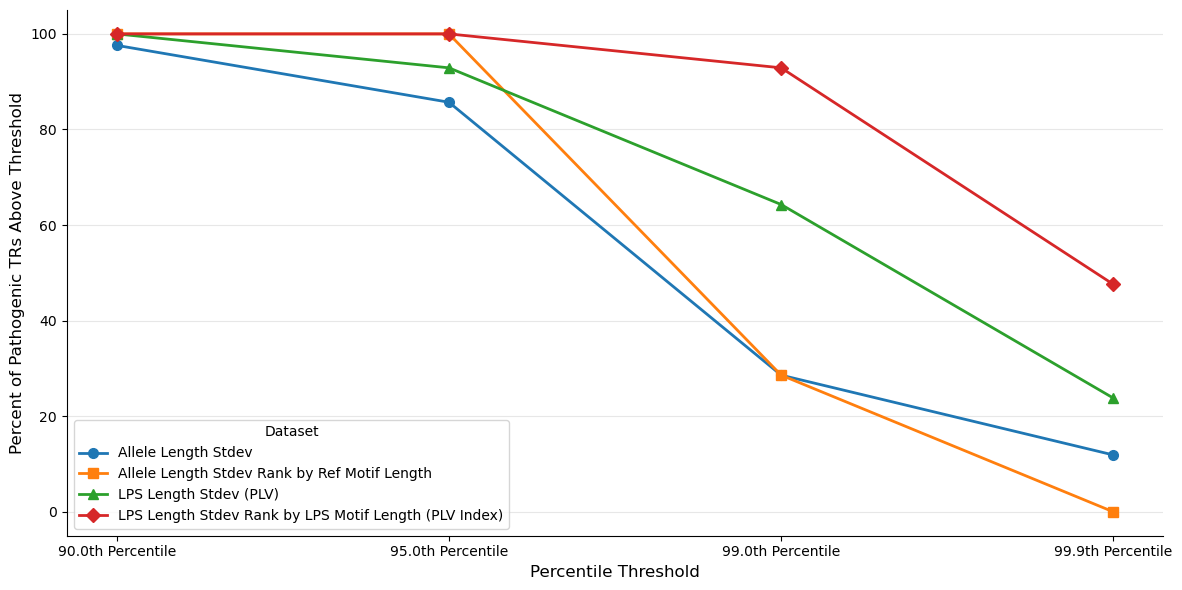

In [ ]:
# plot
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
# Collect n_pathogenic_above values for plotting
thresholds = [0.90, 0.95, 0.99, 0.999]
datasets = {
    'Allele Length Stdev': [0.976, 0.857, 0.286, 0.119],
    'Allele Length Stdev Rank by Ref Motif Length': [1.0, 1.0, 0.286, 0.0],
    'LPS Length Stdev (PLV)': [1.0, 0.929, 0.643, 0.238],
    'LPS Length Stdev Rank by LPS Motif Length (PLV Index)': [1.0, 1.0, 0.929, 0.476]
}

# Collect data for plotting
plot_data = []
for dataset_name, dataset in datasets.items():
    for idx, threshold in enumerate(thresholds):
        plot_data.append({
            'Dataset': dataset_name,
            'Threshold': f'{threshold*100:.1f}th Percentile',
            'percent_pathogenic_above': 100*dataset[idx]
        })

# Convert to DataFrame for easier plotting
plot_df = pd.DataFrame(plot_data)

# Create line plot
colorPalette=['#FFF672','#F9A31B','#EB282D','#F1378A','#9D1E89','#195CAC','#06AF9B','#C7D92F','#64CCF5','0.6']
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['svg.fonttype'] = 'none'
fig, ax = plt.subplots(figsize=(12, 6))

# Get unique thresholds and datasets
threshold_labels = [f'{t*100:.1f}th Percentile' for t in thresholds]
dataset_names = list(datasets.keys())

# Set up x positions (same spacing as before)
x = np.arange(len(threshold_labels))

# Plot lines for each dataset
colors = plt.cm.tab10(np.linspace(0, 0.7, 7))
markers = ['o', 's', '^', 'D']
for idx, dataset_name in enumerate(dataset_names):
    data_subset = plot_df[plot_df['Dataset'] == dataset_name]
    values = [data_subset[data_subset['Threshold'] == tl]['percent_pathogenic_above'].values[0]
              for tl in threshold_labels]
    ax.plot(x, values, color=colors[idx], label=dataset_name,
            marker=markers[idx], markersize=7, linewidth=2)

# Customize plot
ax.set_xlabel('Percentile Threshold', fontsize=12)
ax.set_ylabel('Percent of Pathogenic TRs Above Threshold', fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(threshold_labels)
ax.legend(title='Dataset', loc='lower left')
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('figures/SupplementaryFigure5A.svg')
plt.savefig('figures/SupplementaryFigure5A.png',dpi=600)

In [18]:
# replicate enrichment with Replication cohort
# function to convert motifs to their simplest rotational form
def simplest_motif(motif):
    i = (motif+motif).find(motif, 1, -1)
    if i != -1:
        motif = motif[:i]
    motifs = []
    b = len(motif)
    for i in range(b):
        c = motif[i:]+motif[:i]
        motifs.append(c)
    motifs = [x.upper() for x in motifs]   
    return(min(motifs))


ONT=pd.read_csv('statsTables/ReplicationCohort_lpsPerLocusStats.TR_Explorer_1.0.1.txt.gz',sep='\t')
ONTPerMotif=pd.read_csv('statsTables/ReplicationCohort_lpsPerMotifStats.TR_Explorer_1.0.1.txt.gz',sep='\t')

# drop to the most common LPS motif per locus
ONTPerMotif=ONTPerMotif.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)


# apply the simplest_motif function the data
ONTPerMotif['simpleMotif']=ONTPerMotif.loc[:,'LPS_Motif'].apply(simplest_motif)
ONTPerMotif['motifLen']=ONTPerMotif.loc[:,'simpleMotif'].str.len()

ONT=ONT.merge(ONTPerMotif.loc[:,['TRID','motifLen','simpleMotif']],how='inner',on='TRID')

# calculate percentile of standard deviation within each motif length grouping
ONT['PLVI']=ONT.groupby('motifLen',observed=True)['std'].rank(pct=True)

# mark pathogenic TRs
ONT['patho']=0
ONT.loc[ONT['TRID'].isin(otherPathogenicTRIDs),'patho']=1


# calculate generalized odds ratio for this statistic
group1=ONT.loc[ONT['patho']==1,'PLVI'].dropna().values
group2=ONT.loc[ONT['patho']==0,'PLVI'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")

Raw U Statistic: 184422830.5
P-Value: 1.6918132423246669e-28
Probability of Superiority: 0.9902
Generalized Odds Ratio: 101.2637


## S5B

In [1]:
import pandas
lpsPerMotif_noPathoAlleles=pandas.read_csv('revisionAssets/diseaseLoci_perLPSMotifStdev_noPathogenicLengthAlleles.txt',sep='\t')
lpsPerMotif_noPathoAlleles_10bpPad=pandas.read_csv('revisionAssets/diseaseLoci_perLPSMotifStdev_noPathogenicLengthAlleles_10bpPadding.txt',sep='\t')

In [3]:
lpsPerMotif_noPathoAlleles_10bpPad.loc[lpsPerMotif_noPathoAlleles_10bpPad['TRID']=='15-88569433-88569452-TTTG',:]

,TRID,simpleMotif,std,N_motif


In [6]:
lpsPerMotif=pandas.read_csv('statsTables/DiscoveryCohort_lpsPerMotifStats.TR_Explorer_1.0.1.txt.gz',sep='\t')

In [11]:
lpsPerMotif_noPathoAlleles.loc[lpsPerMotif_noPathoAlleles['TRID']=='19-18786034-18786049-GTC',:]

,TRID,simpleMotif,std,N_motif
23,19-18786034-18786049-GTC,CGT,0.0,1086


In [7]:
lpsPerMotif.loc[lpsPerMotif['TRID']=='19-18786034-18786049-GTC',:]

,TRID,LPS_Motif,N_motif,0thPercentile,1stPercentile,5thPercentile,10thPercentile,15thPercentile,20thPercentile,25thPercentile,...,90thPercentile,95thPercentile,99thPercentile,99.9thPercentile,100thPercentile,mean,std,mad,mode,uniqueLengths
4089288,19-18786034-18786049-GTC,CGT,1086,15.0,15.0,15.0,15.0,15.0,15.0,15.0,...,15.0,15.0,15.0,15.0,15.0,15.0,0.0,0.0,15,1


In [8]:
lpsPerMotif.loc[lpsPerMotif['TRID']=='15-88569433-88569452-TTTG',:]

,TRID,LPS_Motif,N_motif,0thPercentile,1stPercentile,5thPercentile,10thPercentile,15thPercentile,20thPercentile,25thPercentile,...,90thPercentile,95thPercentile,99thPercentile,99.9thPercentile,100thPercentile,mean,std,mad,mode,uniqueLengths
3608304,15-88569433-88569452-TTTG,GTTT,1086,12.0,16.0,16.0,16.0,16.0,16.0,16.0,...,16.0,16.0,16.0,16.0,16.0,15.996317,0.121379,0.0,16,2


In [13]:
import pandas
lpsPerMotif=pandas.read_csv('statsTables/DiscoveryCohort_lpsPerMotifStats.TR_Explorer_1.0.1.txt.gz',sep='\t')
lpsPerLocus=pandas.read_csv('statsTables/DiscoveryCohort_lpsPerLocusStats.TR_Explorer_1.0.1.txt.gz',sep='\t')
alleleLength=pandas.read_csv('statsTables/DiscoveryCohort_alleleLengthStats.TR_Explorer_1.0.1.txt.gz',sep='\t')

# load alternative scores for the pathogenic loci
lpsPerMotif_noPathoAlleles=pandas.read_csv('revisionAssets/diseaseLoci_perLPSMotifStdev_noPathogenicLengthAlleles.txt',sep='\t')
lpsPerMotif_noPathoAlleles_10bpPad=pandas.read_csv('revisionAssets/diseaseLoci_perLPSMotifStdev_noPathogenicLengthAlleles_10bpPadding.txt',sep='\t')
lpsPerLocus_noPathoAlleles=pandas.read_csv('revisionAssets/diseaseLoci_perLocusStdev_noPathogenicLengthAlleles.txt',sep='\t')
lpsPerLocus_noPathoAlleles_10bpPad=pandas.read_csv('revisionAssets/diseaseLoci_perLocusStdev_noPathogenicLengthAlleles_10bpPadding.txt',sep='\t')
alleleLength_noPathoAlleles=pandas.read_csv('revisionAssets/diseaseLoci_alleleLengthStdev_noPathogenicLengthAlleles.txt',sep='\t')
alleleLength_noPathoAlleles_10bpPad=pandas.read_csv('revisionAssets/diseaseLoci_alleleLengthStdev_noPathogenicLengthAlleles_10bpPadding.txt',sep='\t')
alleleLength_top1PercentRemoved=pandas.read_csv('revisionAssets/diseaseLoci_alleleLengthStdev_longest1PercentAllelesRemoved.txt',sep='\t')

def simplest_motif_noRC(motif):
    i = (motif+motif).find(motif, 1, -1)
    if i != -1:
        motif = motif[:i]
    motifs = []
    b = len(motif)
    for i in range(b):
        c = motif[i:]+motif[:i]
        motifs.append(c)
    motifs = [x.upper() for x in motifs]   
    return(min(motifs))

# swap in the new values
lpsPerMotif['simpleMotif']=lpsPerMotif.loc[:,'LPS_Motif'].apply(simplest_motif_noRC)
lpsPerMotif_alt1=lpsPerMotif.copy(deep=True)
lpsPerMotif_alt2=lpsPerMotif.copy(deep=True)
lpsPerLocus_alt1=lpsPerLocus.copy(deep=True)
lpsPerLocus_alt2=lpsPerLocus.copy(deep=True)

alleleLength[['chr','start','end','refMotif']]=alleleLength.loc[:,'TRID'].str.split(',',expand=True).iloc[:,0].str.split('-',expand=True)
alleleLength['refMotifLen']=alleleLength.loc[:,'refMotif'].str.len()
alleleLength_alt1=alleleLength.copy(deep=True)
alleleLength_alt2=alleleLength.copy(deep=True)
alleleLength_alt3=alleleLength.copy(deep=True)


for i in range(len(lpsPerMotif_noPathoAlleles)):
    lpsPerMotif_alt1.loc[((lpsPerMotif_alt1['TRID']==lpsPerMotif_noPathoAlleles.loc[i,'TRID']) & (lpsPerMotif_alt1['simpleMotif']==lpsPerMotif_noPathoAlleles.loc[i,'simpleMotif'])),'std']=lpsPerMotif_noPathoAlleles.loc[i,'std']
    lpsPerMotif_alt1.loc[((lpsPerMotif_alt1['TRID']==lpsPerMotif_noPathoAlleles.loc[i,'TRID']) & (lpsPerMotif_alt1['simpleMotif']==lpsPerMotif_noPathoAlleles.loc[i,'simpleMotif'])),'N_motif']=lpsPerMotif_noPathoAlleles.loc[i,'N_motif']
for i in range(len(lpsPerMotif_noPathoAlleles_10bpPad)):
    lpsPerMotif_alt2.loc[((lpsPerMotif_alt2['TRID']==lpsPerMotif_noPathoAlleles_10bpPad.loc[i,'TRID']) & (lpsPerMotif_alt2['simpleMotif']==lpsPerMotif_noPathoAlleles_10bpPad.loc[i,'simpleMotif'])),'std']=lpsPerMotif_noPathoAlleles_10bpPad.loc[i,'std']
    lpsPerMotif_alt2.loc[((lpsPerMotif_alt2['TRID']==lpsPerMotif_noPathoAlleles_10bpPad.loc[i,'TRID']) & (lpsPerMotif_alt2['simpleMotif']==lpsPerMotif_noPathoAlleles_10bpPad.loc[i,'simpleMotif'])),'N_motif']=lpsPerMotif_noPathoAlleles_10bpPad.loc[i,'N_motif']
for i in range(len(lpsPerLocus_noPathoAlleles)):
    lpsPerLocus_alt1.loc[((lpsPerLocus_alt1['TRID']==lpsPerLocus_noPathoAlleles.loc[i,'TRID'])),'std']=lpsPerLocus_noPathoAlleles.loc[i,'std']
for i in range(len(lpsPerLocus_noPathoAlleles_10bpPad)):
    lpsPerLocus_alt2.loc[((lpsPerLocus_alt2['TRID']==lpsPerLocus_noPathoAlleles_10bpPad.loc[i,'TRID'])),'std']=lpsPerLocus_noPathoAlleles_10bpPad.loc[i,'std']
for i in range(len(alleleLength_noPathoAlleles)):
    alleleLength_alt1.loc[((alleleLength_alt1['TRID']==alleleLength_noPathoAlleles.loc[i,'TRID'])),'std']=alleleLength_noPathoAlleles.loc[i,'std']
for i in range(len(alleleLength_noPathoAlleles_10bpPad)):
    alleleLength_alt2.loc[((alleleLength_alt2['TRID']==alleleLength_noPathoAlleles_10bpPad.loc[i,'TRID'])),'std']=alleleLength_noPathoAlleles_10bpPad.loc[i,'std']
for i in range(len(alleleLength_top1PercentRemoved)):
    alleleLength_alt3.loc[((alleleLength_alt3['TRID']==alleleLength_top1PercentRemoved.loc[i,'TRID'])),'std']=alleleLength_top1PercentRemoved.loc[i,'std']


# drop to the most common LPS motif per locus
lpsPerMotif=lpsPerMotif.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)
lpsPerMotif_alt1=lpsPerMotif_alt1.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)
lpsPerMotif_alt2=lpsPerMotif_alt2.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)

lpsPerMotif['motifLen']=lpsPerMotif.loc[:,'simpleMotif'].str.len()
lpsPerMotif_alt1['motifLen']=lpsPerMotif_alt1.loc[:,'simpleMotif'].str.len()
lpsPerMotif_alt2['motifLen']=lpsPerMotif_alt2.loc[:,'simpleMotif'].str.len()

# calculate perMotifPLVI on the per-motif data tables
lpsPerMotif['perMotifPLVI']=lpsPerMotif.groupby('motifLen',observed=True)['std'].rank(pct=True)
lpsPerMotif_alt1['perMotifPLVI_noPatho']=lpsPerMotif_alt1.groupby('motifLen',observed=True)['std'].rank(pct=True)
lpsPerMotif_alt2['perMotifPLVI_noPatho10bpPad']=lpsPerMotif_alt2.groupby('motifLen',observed=True)['std'].rank(pct=True)

# calculate PLVI alternative on allele lengths
alleleLength['alleleLen_PLVI']=alleleLength.groupby('refMotifLen',observed=True)['std'].rank(pct=True)
alleleLength_alt1['alleleLen_PLVI_noPatho']=alleleLength_alt1.groupby('refMotifLen',observed=True)['std'].rank(pct=True)
alleleLength_alt2['alleleLen_PLVI_noPatho10bpPad']=alleleLength_alt2.groupby('refMotifLen',observed=True)['std'].rank(pct=True)
alleleLength_alt3['alleleLen_PLVI_top1PercentRemoved']=alleleLength_alt3.groupby('refMotifLen',observed=True)['std'].rank(pct=True)


# combine it all together
combined=lpsPerMotif.loc[:,['TRID','std','perMotifPLVI','motifLen','simpleMotif']].rename(columns={'std':'perMotifPLV'}).merge(lpsPerMotif_alt1.loc[:,['TRID','std','perMotifPLVI_noPatho']].rename(columns={'std':'perMotifPLV_noPatho'}),how='inner',on='TRID')
combined=combined.merge(lpsPerMotif_alt2.loc[:,['TRID','std','perMotifPLVI_noPatho10bpPad']].rename(columns={'std':'perMotifPLV_noPatho10bpPad'}),how='inner',on='TRID')
combined=combined.merge(lpsPerLocus.loc[:,['TRID','std']].rename(columns={'std':'PLV'}),how='inner',on='TRID')
combined['PLVI']=combined.groupby('motifLen',observed=True)['PLV'].rank(pct=True)
combined=combined.merge(lpsPerLocus_alt1.loc[:,['TRID','std']].rename(columns={'std':'PLV_noPatho'}),how='inner',on='TRID')
combined['PLVI_noPatho']=combined.groupby('motifLen',observed=True)['PLV_noPatho'].rank(pct=True)
combined=combined.merge(lpsPerLocus_alt2.loc[:,['TRID','std']].rename(columns={'std':'PLV_noPatho10bpPad'}),how='inner',on='TRID')
combined['PLVI_noPatho10bpPad']=combined.groupby('motifLen',observed=True)['PLV_noPatho10bpPad'].rank(pct=True)
combined=combined.merge(alleleLength.loc[:,['TRID','std','alleleLen_PLVI','refMotif','refMotifLen']].rename(columns={'std':'alleleLen_PLV'}),how='inner',on='TRID')
combined=combined.merge(alleleLength_alt1.loc[:,['TRID','std','alleleLen_PLVI_noPatho']].rename(columns={'std':'alleleLen_PLV_noPatho'}),how='inner',on='TRID')
combined=combined.merge(alleleLength_alt2.loc[:,['TRID','std','alleleLen_PLVI_noPatho10bpPad']].rename(columns={'std':'alleleLen_PLV_noPatho10bpPad'}),how='inner',on='TRID')
combined=combined.merge(alleleLength_alt3.loc[:,['TRID','std','alleleLen_PLVI_top1PercentRemoved']].rename(columns={'std':'alleleLen_PLV_top1PercentRemoved'}),how='inner',on='TRID')


genicRegion=pandas.read_csv('assets/genicRegionAnnotations_TRExplorer.txt.gz',sep='\t',header=None,names=['TRID','region'])
combined=combined.merge(genicRegion,how='inner',on='TRID')

# add on additional stratifications (by motif, by biotype, and combinations)
# allele length
combined['alleleLen_std_motif']=combined.groupby('refMotif',observed=True)['alleleLen_PLV'].rank(pct=True)
combined['alleleLen_noPatho_std_motif']=combined.groupby('refMotif',observed=True)['alleleLen_PLV_noPatho'].rank(pct=True)
combined['alleleLen_noPatho10bpPad_std_motif']=combined.groupby('refMotif',observed=True)['alleleLen_PLV_noPatho10bpPad'].rank(pct=True)
combined['alleleLen_top1PercentRemoved_std_motif']=combined.groupby('refMotif',observed=True)['alleleLen_PLV_top1PercentRemoved'].rank(pct=True)
combined['alleleLen_std_biotype']=combined.groupby('region',observed=True)['alleleLen_PLV'].rank(pct=True)
combined['alleleLen_noPatho_std_biotype']=combined.groupby('region',observed=True)['alleleLen_PLV_noPatho'].rank(pct=True)
combined['alleleLen_noPatho10bpPad_std_biotype']=combined.groupby('region',observed=True)['alleleLen_PLV_noPatho10bpPad'].rank(pct=True)
combined['alleleLen_top1PercentRemoved_std_biotype']=combined.groupby('region',observed=True)['alleleLen_PLV_top1PercentRemoved'].rank(pct=True)
combined['alleleLen_std_biotypeAndMotif']=combined.groupby(['region','refMotif'],observed=True)['alleleLen_PLV'].rank(pct=True)
combined['alleleLen_noPatho_std_biotypeAndMotif']=combined.groupby(['region','refMotif'],observed=True)['alleleLen_PLV_noPatho'].rank(pct=True)
combined['alleleLen_noPatho10bpPad_std_biotypeAndMotif']=combined.groupby(['region','refMotif'],observed=True)['alleleLen_PLV_noPatho10bpPad'].rank(pct=True)
combined['alleleLen_top1PercentRemoved_std_biotypeAndMotif']=combined.groupby(['region','refMotif'],observed=True)['alleleLen_PLV_top1PercentRemoved'].rank(pct=True)
combined['alleleLen_std_biotypeAndLen']=combined.groupby(['region','refMotifLen'],observed=True)['alleleLen_PLV'].rank(pct=True)
combined['alleleLen_noPatho_std_biotypeAndLen']=combined.groupby(['region','refMotifLen'],observed=True)['alleleLen_PLV_noPatho'].rank(pct=True)
combined['alleleLen_noPatho10bpPad_std_biotypeAndLen']=combined.groupby(['region','refMotifLen'],observed=True)['alleleLen_PLV_noPatho10bpPad'].rank(pct=True)
combined['alleleLen_top1PercentRemoved_std_biotypeAndLen']=combined.groupby(['region','refMotifLen'],observed=True)['alleleLen_PLV_top1PercentRemoved'].rank(pct=True)
# per motif
combined['perMotif_std_motif']=combined.groupby('simpleMotif',observed=True)['perMotifPLV'].rank(pct=True)
combined['perMotif_noPatho_std_motif']=combined.groupby('simpleMotif',observed=True)['perMotifPLV_noPatho'].rank(pct=True)
combined['perMotif_noPatho10bpPad_std_motif']=combined.groupby('simpleMotif',observed=True)['perMotifPLV_noPatho10bpPad'].rank(pct=True)
combined['perMotif_std_biotype']=combined.groupby('region',observed=True)['perMotifPLV'].rank(pct=True)
combined['perMotif_noPatho_std_biotype']=combined.groupby('region',observed=True)['perMotifPLV_noPatho'].rank(pct=True)
combined['perMotif_noPatho10bpPad_std_biotype']=combined.groupby('region',observed=True)['perMotifPLV_noPatho10bpPad'].rank(pct=True)
combined['perMotif_std_biotypeAndMotif']=combined.groupby(['region','simpleMotif'],observed=True)['perMotifPLV'].rank(pct=True)
combined['perMotif_noPatho_std_biotypeAndMotif']=combined.groupby(['region','simpleMotif'],observed=True)['perMotifPLV_noPatho'].rank(pct=True)
combined['perMotif_noPatho10bpPad_std_biotypeAndMotif']=combined.groupby(['region','simpleMotif'],observed=True)['perMotifPLV_noPatho10bpPad'].rank(pct=True)
combined['perMotif_std_biotypeAndLen']=combined.groupby(['region','motifLen'],observed=True)['perMotifPLV'].rank(pct=True)
combined['perMotif_noPatho_std_biotypeAndLen']=combined.groupby(['region','motifLen'],observed=True)['perMotifPLV_noPatho'].rank(pct=True)
combined['perMotif_noPatho10bpPad_std_biotypeAndLen']=combined.groupby(['region','motifLen'],observed=True)['perMotifPLV_noPatho10bpPad'].rank(pct=True)
# per locus
combined['perLocus_std_motif']=combined.groupby('simpleMotif',observed=True)['PLV'].rank(pct=True)
combined['perLocus_noPatho_std_motif']=combined.groupby('simpleMotif',observed=True)['PLV_noPatho'].rank(pct=True)
combined['perLocus_noPatho10bpPad_std_motif']=combined.groupby('simpleMotif',observed=True)['PLV_noPatho10bpPad'].rank(pct=True)
combined['perLocus_std_biotype']=combined.groupby('region',observed=True)['PLV'].rank(pct=True)
combined['perLocus_noPatho_std_biotype']=combined.groupby('region',observed=True)['PLV_noPatho'].rank(pct=True)
combined['perLocus_noPatho10bpPad_std_biotype']=combined.groupby('region',observed=True)['PLV_noPatho10bpPad'].rank(pct=True)
combined['perLocus_std_biotypeAndMotif']=combined.groupby(['region','simpleMotif'],observed=True)['PLV'].rank(pct=True)
combined['perLocus_noPatho_std_biotypeAndMotif']=combined.groupby(['region','simpleMotif'],observed=True)['PLV_noPatho'].rank(pct=True)
combined['perLocus_noPatho10bpPad_std_biotypeAndMotif']=combined.groupby(['region','simpleMotif'],observed=True)['PLV_noPatho10bpPad'].rank(pct=True)
combined['perLocus_std_biotypeAndLen']=combined.groupby(['region','motifLen'],observed=True)['PLV'].rank(pct=True)
combined['perLocus_noPatho_std_biotypeAndLen']=combined.groupby(['region','motifLen'],observed=True)['PLV_noPatho'].rank(pct=True)
combined['perLocus_noPatho10bpPad_std_biotypeAndLen']=combined.groupby(['region','motifLen'],observed=True)['PLV_noPatho10bpPad'].rank(pct=True)


# Define pathogenic and poly-alanine TRIDs
pathogenic=pandas.read_csv('assets/pathogenicTRIDs_TRExplorer_v1.0.1_STRchiveFiltered_noVNTRs_withAnno.txt',sep='\t')
polyAlanineTRNames = ['ARX','NIPA1','HOXA13','PHOX2B','SOX3','HOXD13','ZIC2','RUNX2','PABPN1','FOXL2']
polyAlanineTRIDs = pathogenic.loc[pathogenic['geneName'].isin(polyAlanineTRNames),'TRID'].values
singleShiftTRNames = ['MIR7-2','COMP']
singleShiftTRIDs = pathogenic.loc[pathogenic['geneName'].isin(singleShiftTRNames),'TRID'].values
otherPathogenicTRIDs = pathogenic.loc[~pathogenic['geneName'].isin(polyAlanineTRNames),:]
otherPathogenicTRIDs = otherPathogenicTRIDs.loc[~otherPathogenicTRIDs['geneName'].isin(singleShiftTRNames),'TRID'].values
allPathogenicTRIDs = pathogenic.loc[:,'TRID'].values

# mark pathogenic TRs
combined['patho']=0
combined.loc[combined['TRID'].isin(otherPathogenicTRIDs),'patho']=1
combined.loc[combined['TRID'].isin(polyAlanineTRIDs),'patho']=2
combined.loc[combined['TRID'].isin(singleShiftTRIDs),'patho']=3
combined

,TRID,perMotifPLV,perMotifPLVI,motifLen,simpleMotif,perMotifPLV_noPatho,perMotifPLVI_noPatho,perMotifPLV_noPatho10bpPad,perMotifPLVI_noPatho10bpPad,PLV,...,perLocus_std_biotype,perLocus_noPatho_std_biotype,perLocus_noPatho10bpPad_std_biotype,perLocus_std_biotypeAndMotif,perLocus_noPatho_std_biotypeAndMotif,perLocus_noPatho10bpPad_std_biotypeAndMotif,perLocus_std_biotypeAndLen,perLocus_noPatho_std_biotypeAndLen,perLocus_noPatho10bpPad_std_biotypeAndLen,patho
0,Y-9999592-9999601-TAT,0.000000,0.396701,3,ATT,0.000000,0.396701,0.000000,0.396701,0.000000,...,0.225206,0.225206,0.225206,0.395412,0.395412,0.395412,0.388866,0.388866,0.388866,0
1,Y-9999279-9999299-T,0.340360,0.515088,1,T,0.340360,0.515088,0.340360,0.515088,0.340360,...,0.684904,0.684904,0.684904,0.507633,0.507633,0.507633,0.501977,0.501977,0.501977,0
2,Y-9999271-9999280-TG,0.204652,0.660650,2,GT,0.204652,0.660650,0.204652,0.660650,0.204652,...,0.623481,0.623481,0.623481,0.584250,0.584250,0.584250,0.644765,0.644765,0.644765,0
3,Y-9998080-9998090-CA,0.000000,0.262677,2,AC,0.000000,0.262677,0.000000,0.262677,0.000000,...,0.225206,0.225206,0.225206,0.233409,0.233409,0.233409,0.255076,0.255076,0.255076,0
4,Y-9998060-9998076-CAAA,0.000000,0.276310,4,AAAC,0.000000,0.276310,0.000000,0.276310,0.000000,...,0.225206,0.225206,0.225206,0.242444,0.242444,0.242444,0.262970,0.262970,0.262970,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4439256,1-100002782-100002795-T,0.413220,0.565089,1,T,0.413220,0.565089,0.413220,0.565089,0.413220,...,0.715243,0.715243,0.715243,0.575606,0.575606,0.575606,0.568919,0.568919,0.568919,0
4439257,1-100002614-100002631-TTG,0.000000,0.396701,3,GTT,0.000000,0.396701,0.000000,0.396701,0.000000,...,0.215349,0.215349,0.215349,0.338789,0.338789,0.338789,0.392491,0.392491,0.392491,0
4439258,1-100001444-100001454-T,0.052510,0.182692,1,T,0.052510,0.182692,0.052510,0.182692,0.052510,...,0.465455,0.465455,0.465455,0.182814,0.182814,0.182814,0.178591,0.178591,0.178591,0
4439259,1-100000874-100000884-T,0.222077,0.427572,1,T,0.222077,0.427572,0.222077,0.427572,0.222077,...,0.630071,0.630071,0.630071,0.434381,0.434381,0.434381,0.428022,0.428022,0.428022,0


In [16]:
# check on MIR7-2
combined.loc[combined['TRID'].isin(singleShiftTRIDs),'patho']=3
combined.loc[combined['TRID']=='15-88569433-88569452-TTTG',:]

,TRID,perMotifPLV,perMotifPLVI,motifLen,simpleMotif,perMotifPLV_noPatho,perMotifPLVI_noPatho,perMotifPLV_noPatho10bpPad,perMotifPLVI_noPatho10bpPad,PLV,...,perLocus_std_biotype,perLocus_noPatho_std_biotype,perLocus_noPatho10bpPad_std_biotype,perLocus_std_biotypeAndMotif,perLocus_noPatho_std_biotypeAndMotif,perLocus_noPatho10bpPad_std_biotypeAndMotif,perLocus_std_biotypeAndLen,perLocus_noPatho_std_biotypeAndLen,perLocus_noPatho10bpPad_std_biotypeAndLen,patho
3077595,15-88569433-88569452-TTTG,0.121379,0.602252,4,GTTT,0.121379,0.602252,0.121379,0.602252,0.121379,...,0.552193,0.552193,0.552193,0.5538,0.5538,0.5538,0.601538,0.601538,0.601538,3


In [17]:
# check on COMP
combined.loc[combined['TRID']=='19-18786034-18786049-GTC',:]

,TRID,perMotifPLV,perMotifPLVI,motifLen,simpleMotif,perMotifPLV_noPatho,perMotifPLVI_noPatho,perMotifPLV_noPatho10bpPad,perMotifPLVI_noPatho10bpPad,PLV,...,perLocus_std_biotype,perLocus_noPatho_std_biotype,perLocus_noPatho10bpPad_std_biotype,perLocus_std_biotypeAndMotif,perLocus_noPatho_std_biotypeAndMotif,perLocus_noPatho10bpPad_std_biotypeAndMotif,perLocus_std_biotypeAndLen,perLocus_noPatho_std_biotypeAndLen,perLocus_noPatho10bpPad_std_biotypeAndLen,patho
2642372,19-18786034-18786049-GTC,0.0,0.396701,3,CGT,0.0,0.396701,0.0,0.396701,0.0,...,0.403806,0.403806,0.403806,0.356021,0.356021,0.356021,0.413768,0.413768,0.413768,3


In [20]:
import scipy.stats
# Calculate enrichment
def calculate_generalized_odds_ratio(group1, group2):
    u_stat, p_value = scipy.stats.mannwhitneyu(group1, group2, alternative='greater')
    n1=len(group1)
    n2=len(group2)
    prob_superiority = u_stat / (n1*n2)
    odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
    return p_value, odds_ratio

results_collection=[]
for targetSet in ['primarySet','polyAlanineOnly','singleShiftOnly','combined']:
    for column in ['alleleLen_PLV', 'alleleLen_PLVI', 'alleleLen_PLV_noPatho',
                    'alleleLen_PLVI_noPatho', 'alleleLen_PLV_noPatho10bpPad',
                    'alleleLen_PLVI_noPatho10bpPad',
                    'alleleLen_PLV_top1PercentRemoved',
                    'alleleLen_PLVI_top1PercentRemoved', 
                    'alleleLen_std_motif', 'alleleLen_noPatho_std_motif',
                    'alleleLen_noPatho10bpPad_std_motif',
                    'alleleLen_top1PercentRemoved_std_motif', 'alleleLen_std_biotype',
                    'alleleLen_noPatho_std_biotype',
                    'alleleLen_noPatho10bpPad_std_biotype',
                    'alleleLen_top1PercentRemoved_std_biotype',
                    'alleleLen_std_biotypeAndMotif',
                    'alleleLen_noPatho_std_biotypeAndMotif',
                    'alleleLen_noPatho10bpPad_std_biotypeAndMotif',
                    'alleleLen_top1PercentRemoved_std_biotypeAndMotif',
                    'alleleLen_std_biotypeAndLen',
                    'alleleLen_noPatho_std_biotypeAndLen',
                    'alleleLen_noPatho10bpPad_std_biotypeAndLen',
                    'alleleLen_top1PercentRemoved_std_biotypeAndLen',
                    'perMotifPLV', 'perMotifPLVI',
                    'perMotifPLV_noPatho', 'perMotifPLVI_noPatho',
                    'perMotifPLV_noPatho10bpPad', 'perMotifPLVI_noPatho10bpPad',
                    'perMotif_std_motif', 'perMotif_noPatho_std_motif',
                    'perMotif_noPatho10bpPad_std_motif', 'perMotif_std_biotype',
                    'perMotif_noPatho_std_biotype',
                    'perMotif_noPatho10bpPad_std_biotype',
                    'perMotif_std_biotypeAndMotif',
                    'perMotif_noPatho_std_biotypeAndMotif',
                    'perMotif_noPatho10bpPad_std_biotypeAndMotif',
                    'perMotif_std_biotypeAndLen', 'perMotif_noPatho_std_biotypeAndLen',
                    'perMotif_noPatho10bpPad_std_biotypeAndLen', 'perLocus_std_motif',
                    'PLV','PLVI', 'PLV_noPatho', 'PLVI_noPatho', 'PLV_noPatho10bpPad',
                    'PLVI_noPatho10bpPad', 
                    'perLocus_noPatho_std_motif', 'perLocus_noPatho10bpPad_std_motif',
                    'perLocus_std_biotype', 'perLocus_noPatho_std_biotype',
                    'perLocus_noPatho10bpPad_std_biotype',
                    'perLocus_std_biotypeAndMotif',
                    'perLocus_noPatho_std_biotypeAndMotif',
                    'perLocus_noPatho10bpPad_std_biotypeAndMotif',
                    'perLocus_std_biotypeAndLen', 'perLocus_noPatho_std_biotypeAndLen',
                    'perLocus_noPatho10bpPad_std_biotypeAndLen']:
        # Calculate odds ratio with CI for a set of values
        if targetSet == 'primarySet':
            group1=combined.loc[combined['patho']==1,column].dropna().values
            group2=combined.loc[combined['patho']!=1,column].dropna().values
        elif targetSet == 'polyAlanineOnly':
            group1=combined.loc[combined['patho']==2,column].dropna().values
            group2=combined.loc[combined['patho']!=2,column].dropna().values
        elif targetSet == 'singleShiftOnly':
            group1=combined.loc[combined['patho']==3,column].dropna().values
            group2=combined.loc[combined['patho']!=3,column].dropna().values
        else:
            group1=combined.loc[combined['patho']>0,column].dropna().values
            group2=combined.loc[combined['patho']==0,column].dropna().values


        p_value, odds_ratio = calculate_generalized_odds_ratio(group1, group2)

        # Store results for this condition
        results_collection.append({
            'condition': f'{column} on {targetSet}',
            'p_value': p_value,
            'odds_ratio': odds_ratio,
        })

# Display summary of all collected results
print("\n" + "="*80)
print("SUMMARY OF ALL CONDITIONS")
print("="*80)
results_df = pandas.DataFrame(results_collection)
results_df.to_csv('assets/PLVI_Variations_OddsRatios.txt',sep='\t',index=False)
print(results_df.to_string(index=False))


SUMMARY OF ALL CONDITIONS
                                                          condition      p_value  odds_ratio
                                        alleleLen_PLV on primarySet 2.212904e-29   34.189368
                                       alleleLen_PLVI on primarySet 2.128048e-28   65.762889
                                alleleLen_PLV_noPatho on primarySet 5.804817e-29   30.217568
                               alleleLen_PLVI_noPatho on primarySet 6.583902e-28   50.288134
                         alleleLen_PLV_noPatho10bpPad on primarySet 6.624098e-29   29.740508
                        alleleLen_PLVI_noPatho10bpPad on primarySet 6.893975e-28   49.805984
                     alleleLen_PLV_top1PercentRemoved on primarySet 2.276582e-28   25.878576
                    alleleLen_PLVI_top1PercentRemoved on primarySet 1.115406e-27   45.250162
                                  alleleLen_std_motif on primarySet 4.199764e-27   43.248722
                          alleleLen_noPatho

In [21]:
results_df.to_csv('assets/PLVI_Variations_OddsRatios.txt',sep='\t',index=False)

In [22]:
# drop the 1Percent filter layer
results_df=results_df.loc[~results_df['condition'].str.contains('1Percent'),:]
results_df.to_csv('assets/PLVI_Variations_OddsRatios_filt.txt',sep='\t',index=False)

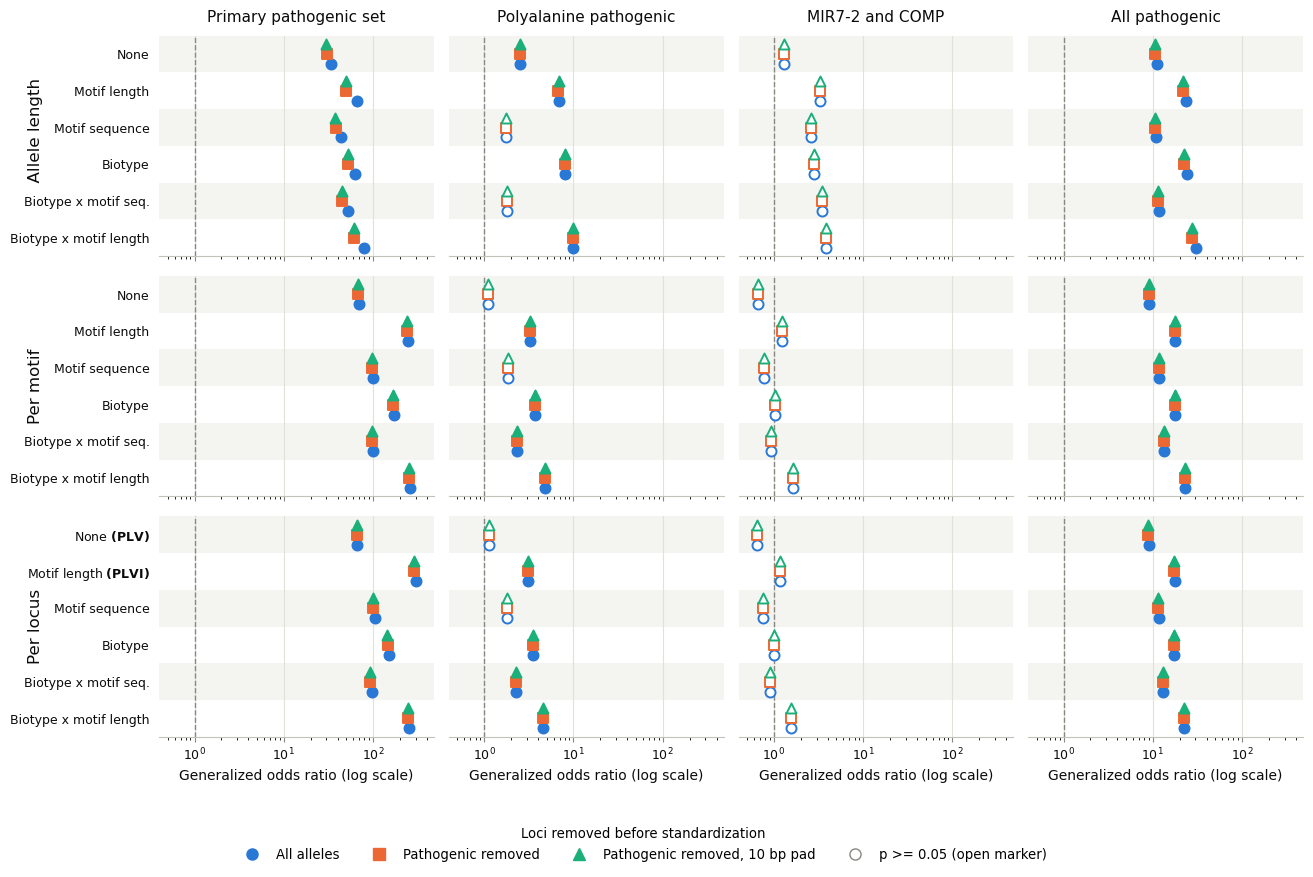

In [28]:
# Plot the odds ratios for every analytic variation as a faceted dot plot.
# Each of the 60 columns is a crossing of three factors (metric level x
# standardization x filter layer), which are put on facet row / y-axis / colour
# so that no factor is nested inside another. targetSet becomes the facet column.
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['svg.fonttype'] = 'none'  # keep SVG text in SVGs

results_df = pd.read_csv('assets/PLVI_Variations_OddsRatios_filt.txt', sep='\t')

METRIC_LEVELS = ['Allele length', 'Per motif', 'Per locus']
STANDARDIZATIONS = ['None', 'Motif length', 'Motif sequence',
                    'Biotype', 'Biotype x motif seq.', 'Biotype x motif length']
PerLocusStandardizationsStrings = ['None $\\bf{(PLV)}$', 'Motif length $\\bf{(PLVI)}$', 'Motif sequence',
                                   'Biotype', 'Biotype x motif seq.', 'Biotype x motif length']
FILTER_LAYERS = ['All alleles', 'Pathogenic removed', 'Pathogenic removed, 10 bp pad']
TARGET_SETS = ['primarySet', 'polyAlanineOnly', 'singleShiftOnly', 'combined']
TARGET_LABELS = {'primarySet': 'Primary pathogenic set',
                 'polyAlanineOnly': 'Polyalanine pathogenic',
                 'singleShiftOnly': 'MIR7-2 and COMP',
                 'combined': 'All pathogenic'}
# categorical slots validated all-pairs for CVD; marker shape is the secondary
# encoding so identity never rests on colour alone
COLORS = dict(zip(FILTER_LAYERS, ['#2a78d6', '#eb6834', '#1baf7a']))
MARKERS = dict(zip(FILTER_LAYERS, ['o', 's', '^']))
MUTED, GRID, INK = '#898781', '#e1e0d9', '#0b0b0b'


def parse_condition(condition):
    """'<column> on <targetSet>' -> (metric level, standardization, filter layer, targetSet)"""
    column, targetSet = condition.split(' on ')
    for prefix, level in [('alleleLen', 'Allele length'), ('perMotif', 'Per motif'),
                          ('perLocus', 'Per locus')]:
        if column.startswith(prefix):
            rest = column[len(prefix):].lstrip('_')
            break
    else:  # bare PLV / PLVI columns are the unstandardized per-locus values
        level, rest = 'Per locus', column

    if 'noPatho10bpPad' in rest:
        layer = 'Pathogenic removed, 10 bp pad'
    elif 'noPatho' in rest:
        layer = 'Pathogenic removed'
    else:
        layer = 'All alleles'

    if 'std_biotypeAndMotif' in rest:
        std = 'Biotype x motif seq.'
    elif 'std_biotypeAndLen' in rest:
        std = 'Biotype x motif length'
    elif 'std_biotype' in rest:
        std = 'Biotype'
    elif 'std_motif' in rest:
        std = 'Motif sequence'
    elif rest.startswith('PLVI'):
        std = 'Motif length'
    else:
        std = 'None'
    return level, std, layer, targetSet


plot_df = pd.concat([results_df,
                     pd.DataFrame([parse_condition(c) for c in results_df['condition']],
                                  columns=['level', 'std', 'layer', 'targetSet'],
                                  index=results_df.index)], axis=1)

# sanity check: every condition must land in exactly one cell of the design
assert plot_df['std'].isin(STANDARDIZATIONS).all()
assert plot_df['layer'].isin(FILTER_LAYERS).all()
assert not plot_df.duplicated(['level', 'std', 'layer', 'targetSet']).any()

# vertical dodge, held identical in every panel so rows line up across facets even
# where a variant does not exist (top-1%-removed is allele-length only)
OFFSETS = dict(zip(FILTER_LAYERS, np.linspace(0.27, -0.27, len(FILTER_LAYERS))))

finite = plot_df.loc[np.isfinite(plot_df['odds_ratio']) & (plot_df['odds_ratio'] > 0), 'odds_ratio']
xlim = (min(finite.min() / 1.6, 0.8), finite.max() * 1.6)  # always keep OR=1 in view

fig, axes = plt.subplots(len(METRIC_LEVELS), len(TARGET_SETS), figsize=(13.5, 9.5),
                         sharex=True, sharey='row')  # 'row', not True: a shared y-axis
                         # would force one tick formatter on all 9 panels
for r, level in enumerate(METRIC_LEVELS):
    for c, targetSet in enumerate(TARGET_SETS):
        ax = axes[r, c]
        panel = plot_df.loc[(plot_df['level'] == level) & (plot_df['targetSet'] == targetSet)]

        ax.axvline(1, color=MUTED, linestyle='--', linewidth=1, zorder=1)
        for y, std in enumerate(STANDARDIZATIONS):
            if y % 2 == 0:  # banding to tie each row of markers to its label
                ax.axhspan(y - 0.5, y + 0.5, color=GRID, alpha=0.35, zorder=0, linewidth=0)
        ax.grid(axis='x', color=GRID, linewidth=0.8, zorder=0)
        ax.set_axisbelow(True)

        for layer in FILTER_LAYERS:
            sub = panel.loc[panel['layer'] == layer]
            if sub.empty:
                continue
            ys = [STANDARDIZATIONS.index(s) + OFFSETS[layer] for s in sub['std']]
            sig = (sub['p_value'] < 0.05).values
            # filled = p < 0.05 (one-sided Mann-Whitney), open = not significant
            for mask, face in [(sig, COLORS[layer]), (~sig, 'white')]:
                if not mask.any():
                    continue
                ax.scatter(sub['odds_ratio'].values[mask], np.array(ys)[mask],
                           marker=MARKERS[layer], s=52, facecolors=face,
                           edgecolors=COLORS[layer], linewidths=1.4, zorder=3)

        ax.set_xscale('log')
        ax.set_xlim(*xlim)
        ax.set_ylim(len(STANDARDIZATIONS) - 0.5, -0.5)
        ax.set_yticks(range(len(STANDARDIZATIONS)))
        ax.set_yticklabels(STANDARDIZATIONS, fontsize=9)
        if level=="Per locus":
            ax.set_yticklabels(PerLocusStandardizationsStrings, fontsize=9)
        ax.tick_params(axis='both', colors=MUTED, labelsize=9, left=False)
        for lbl in ax.get_yticklabels() + ax.get_xticklabels():
            lbl.set_color(INK)
        for side in ['top', 'right', 'left']:
            ax.spines[side].set_visible(False)
        ax.spines['bottom'].set_color('#c3c2b7')

        if r == 0:
            ax.set_title(TARGET_LABELS[targetSet], fontsize=11, color=INK, pad=10)
        if r == len(METRIC_LEVELS) - 1:
            ax.set_xlabel('Generalized odds ratio (log scale)', fontsize=10, color=INK)
        if c == 0:
            if r==0:
                # shift the 'Allele Length' label up slightly to avoid a text collision 
                ax.annotate("      " + level + '\n', xy=(-0.42, 0.5), xycoords='axes fraction',
                            rotation=90, va='center', ha='center', fontsize=12, color=INK)
            else:
                ax.annotate(level + '\n', xy=(-0.42, 0.5), xycoords='axes fraction',
                            rotation=90, va='center', ha='center', fontsize=12, color=INK)

handles = [Line2D([], [], marker=MARKERS[l], color='none', markerfacecolor=COLORS[l],
                  markeredgecolor=COLORS[l], markersize=8, label=l) for l in FILTER_LAYERS]
handles += [Line2D([], [], marker='o', color='none', markerfacecolor='white',
                   markeredgecolor=MUTED, markersize=8, label='p >= 0.05 (open marker)')]
leg = fig.legend(handles=handles, loc='lower center', ncol=5, frameon=False,
                 fontsize=9.5, bbox_to_anchor=(0.5, 0.035),
                 title='Loci removed before standardization')
leg.get_title().set_fontsize(9.5)

#fig.suptitle('Enrichment of pathogenic TRs across PLV/PLVI analytic variations',
#             fontsize=13, color=INK, y=0.98)
plt.tight_layout(rect=[0.02, 0.115, 1, 0.96])
plt.savefig('figures/SupplementaryFigure5B.svg')
plt.savefig('figures/SupplementaryFigure5B.png', dpi=600)

# flag any degenerate odds ratios (prob. of superiority pinned at 1 -> OR ~1e9)
extreme = plot_df.loc[plot_df['odds_ratio'] > 1e6, 'condition']
if len(extreme):
    print(f'WARNING: {len(extreme)} conditions have OR > 1e6 (probability of '
          f'superiority == 1); these are off-scale:\n' + '\n'.join(extreme))

# S6: Replication of enrichment

## S6A

In [1]:
# caluclate the proportion of the pathogenic TRs that rank above the 90th, 95th, and 99th percentiles
# initial data loading and package import
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sb
import matplotlib
from matplotlib.colors import to_rgba

mpl.rcParams['svg.fonttype'] = 'none'  # keep SVG text in SVGs

DiscoveryPerMotif=pd.read_csv('statsTables/DiscoveryCohort_lpsPerMotifStats.TR_Explorer_1.0.1.txt.gz',sep='\t')
ValidationPerMotif=pd.read_csv('statsTables/ValidationCohort_lpsPerMotifStats.TR_Explorer_1.0.1.txt.gz',sep='\t')
AFRPerMotif=pd.read_csv('statsTables/ValidationCohort_lpsPerMotifStats_AFR.TR_Explorer_1.0.1.txt.gz',sep='\t')
AMRPerMotif=pd.read_csv('statsTables/ValidationCohort_lpsPerMotifStats_AMR.TR_Explorer_1.0.1.txt.gz',sep='\t')
EURPerMotif=pd.read_csv('statsTables/ValidationCohort_lpsPerMotifStats_EUR.TR_Explorer_1.0.1.txt.gz',sep='\t')
EASPerMotif=pd.read_csv('statsTables/ValidationCohort_lpsPerMotifStats_EAS.TR_Explorer_1.0.1.txt.gz',sep='\t')
SASPerMotif=pd.read_csv('statsTables/ValidationCohort_lpsPerMotifStats_SAS.TR_Explorer_1.0.1.txt.gz',sep='\t')
ReplicationPerMotif=pd.read_csv('statsTables/ReplicationCohort_lpsPerMotifStats.TR_Explorer_1.0.1.txt.gz',sep='\t')

Discovery=pd.read_csv('statsTables/DiscoveryCohort_lpsPerLocusStats.TR_Explorer_1.0.1.txt.gz',sep='\t')
Validation=pd.read_csv('statsTables/ValidationCohort_lpsPerLocusStats.TR_Explorer_1.0.1.txt.gz',sep='\t')
AFR=pd.read_csv('statsTables/ValidationCohort_lpsPerLocusStats_AFR.TR_Explorer_1.0.1.txt.gz',sep='\t')
AMR=pd.read_csv('statsTables/ValidationCohort_lpsPerLocusStats_AMR.TR_Explorer_1.0.1.txt.gz',sep='\t')
EUR=pd.read_csv('statsTables/ValidationCohort_lpsPerLocusStats_EUR.TR_Explorer_1.0.1.txt.gz',sep='\t')
EAS=pd.read_csv('statsTables/ValidationCohort_lpsPerLocusStats_EAS.TR_Explorer_1.0.1.txt.gz',sep='\t')
SAS=pd.read_csv('statsTables/ValidationCohort_lpsPerLocusStats_SAS.TR_Explorer_1.0.1.txt.gz',sep='\t')
Replication=pd.read_csv('statsTables/ReplicationCohort_lpsPerLocusStats.TR_Explorer_1.0.1.txt.gz',sep='\t')

# drop to the most common LPS motif per locus
DiscoveryPerMotif=DiscoveryPerMotif.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)
ValidationPerMotif=ValidationPerMotif.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)
AFRPerMotif=AFRPerMotif.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)
AMRPerMotif=AMRPerMotif.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)
EURPerMotif=EURPerMotif.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)
EASPerMotif=EASPerMotif.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)
SASPerMotif=SASPerMotif.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)
ReplicationPerMotif=ReplicationPerMotif.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)

# function to convert motifs to their simplest rotational form with reverse complements
def complement(seq):
    complement = {'A': 'T', 'C': 'G', 'G': 'C', 'T': 'A'} 
    bases = list(seq) 
    bases = [complement[base] for base in bases] 
    return ''.join(bases)
def reverse_complement(seq):
    return complement(seq[::-1])
def simplest_motif(motif):
    i = (motif+motif).find(motif, 1, -1)
    if i != -1:
        motif = motif[:i]
    motifs = []
    b = len(motif)
    for i in range(b):
        c = motif[i:]+motif[:i]
        motifs.append(c)
    motifs = [x.upper() for x in motifs]
    # repeat with reverse complement
    motifRC=reverse_complement(motif.upper())
    i = (motifRC+motifRC).find(motifRC, 1, -1)
    if i != -1:
        motifRC = motifRC[:i]
    b = len(motifRC)
    for i in range(b):
        c = motifRC[i:]+motifRC[:i]
        motifs.append(c)    
    return(min(motifs))

# apply the simplest_motif function the data
DiscoveryPerMotif['simpleMotif']=DiscoveryPerMotif.loc[:,'LPS_Motif'].apply(simplest_motif)
ValidationPerMotif['simpleMotif']=ValidationPerMotif.loc[:,'LPS_Motif'].apply(simplest_motif)
AFRPerMotif['simpleMotif']=AFRPerMotif.loc[:,'LPS_Motif'].apply(simplest_motif)
AMRPerMotif['simpleMotif']=AMRPerMotif.loc[:,'LPS_Motif'].apply(simplest_motif)
EURPerMotif['simpleMotif']=EURPerMotif.loc[:,'LPS_Motif'].apply(simplest_motif)
EASPerMotif['simpleMotif']=EASPerMotif.loc[:,'LPS_Motif'].apply(simplest_motif)
SASPerMotif['simpleMotif']=SASPerMotif.loc[:,'LPS_Motif'].apply(simplest_motif)
ReplicationPerMotif['simpleMotif']=ReplicationPerMotif.loc[:,'LPS_Motif'].apply(simplest_motif)

# calculate percentile of standard deviation within each motif length
DiscoveryPerMotif['motifLen']=DiscoveryPerMotif.loc[:,'simpleMotif'].str.len()
ValidationPerMotif['motifLen']=ValidationPerMotif.loc[:,'simpleMotif'].str.len()
AFRPerMotif['motifLen']=AFRPerMotif.loc[:,'simpleMotif'].str.len()
AMRPerMotif['motifLen']=AMRPerMotif.loc[:,'simpleMotif'].str.len()
EURPerMotif['motifLen']=EURPerMotif.loc[:,'simpleMotif'].str.len()
EASPerMotif['motifLen']=EASPerMotif.loc[:,'simpleMotif'].str.len()
SASPerMotif['motifLen']=SASPerMotif.loc[:,'simpleMotif'].str.len()
ReplicationPerMotif['motifLen']=ReplicationPerMotif.loc[:,'simpleMotif'].str.len()

Discovery=Discovery.merge(DiscoveryPerMotif.loc[:,['TRID','motifLen']],how='inner',on='TRID')
Validation=Validation.merge(ValidationPerMotif.loc[:,['TRID','motifLen']],how='inner',on='TRID')
AFR=AFR.merge(AFRPerMotif.loc[:,['TRID','motifLen']],how='inner',on='TRID')
AMR=AMR.merge(AMRPerMotif.loc[:,['TRID','motifLen']],how='inner',on='TRID')
EUR=EUR.merge(EURPerMotif.loc[:,['TRID','motifLen']],how='inner',on='TRID')
EAS=EAS.merge(EASPerMotif.loc[:,['TRID','motifLen']],how='inner',on='TRID')
SAS=SAS.merge(SASPerMotif.loc[:,['TRID','motifLen']],how='inner',on='TRID')
Replication=Replication.merge(ReplicationPerMotif.loc[:,['TRID','motifLen']],how='inner',on='TRID')

Discovery['PLVI']=Discovery.groupby('motifLen',observed=True)['std'].rank(pct=True)
Validation['PLVI']=Validation.groupby('motifLen',observed=True)['std'].rank(pct=True)
AFR['PLVI']=AFR.groupby('motifLen',observed=True)['std'].rank(pct=True)
AMR['PLVI']=AMR.groupby('motifLen',observed=True)['std'].rank(pct=True)
EUR['PLVI']=EUR.groupby('motifLen',observed=True)['std'].rank(pct=True)
EAS['PLVI']=EAS.groupby('motifLen',observed=True)['std'].rank(pct=True)
SAS['PLVI']=SAS.groupby('motifLen',observed=True)['std'].rank(pct=True)
Replication['PLVI']=Replication.groupby('motifLen',observed=True)['std'].rank(pct=True)


# Define pathogenic and poly-alanine TRIDs
pathogenic=pd.read_csv('assets/pathogenicTRIDs_TRExplorer_v1.0.1_STRchiveFiltered_noVNTRs_withAnno.txt',sep='\t')

polyAlanineTRNames = ['ARX','NIPA1','HOXA13','PHOX2B','SOX3','HOXD13','ZIC2','RUNX2','PABPN1','FOXL2']
polyAlanineTRIDs = pathogenic.loc[pathogenic['geneName'].isin(polyAlanineTRNames),'TRID'].values
singleShiftTRNames = ['MIR7-2','COMP']
singleShiftTRIDs = pathogenic.loc[pathogenic['geneName'].isin(singleShiftTRNames),'TRID'].values
otherPathogenicTRIDs = pathogenic.loc[~pathogenic['geneName'].isin(polyAlanineTRNames),:]
otherPathogenicTRIDs = otherPathogenicTRIDs.loc[~otherPathogenicTRIDs['geneName'].isin(singleShiftTRNames),'TRID'].values



# Analyze the known pathogenic TR enrichment
Discovery['patho']=0
Discovery.loc[Discovery['TRID'].isin(otherPathogenicTRIDs),'patho']=1
Validation['patho']=0
Validation.loc[Validation['TRID'].isin(otherPathogenicTRIDs),'patho']=1
AFR['patho']=0
AFR.loc[AFR['TRID'].isin(otherPathogenicTRIDs),'patho']=1
AMR['patho']=0
AMR.loc[AMR['TRID'].isin(otherPathogenicTRIDs),'patho']=1
EUR['patho']=0
EUR.loc[EUR['TRID'].isin(otherPathogenicTRIDs),'patho']=1
EAS['patho']=0
EAS.loc[EAS['TRID'].isin(otherPathogenicTRIDs),'patho']=1
SAS['patho']=0
SAS.loc[SAS['TRID'].isin(otherPathogenicTRIDs),'patho']=1
Replication['patho']=0
Replication.loc[Replication['TRID'].isin(otherPathogenicTRIDs),'patho']=1

from statsmodels.stats.contingency_tables import Table2x2

def calculate_enrichment_with_ci(df, percentile_threshold, pathogenic_col='patho'):
    above_threshold = df['PLVI'] > percentile_threshold
    
    a = ((df[pathogenic_col] == 1) & above_threshold).sum()
    b = ((df[pathogenic_col] == 0) & above_threshold).sum()
    c = ((df[pathogenic_col] == 1) & ~above_threshold).sum()
    d = ((df[pathogenic_col] == 0) & ~above_threshold).sum()
    
    table = Table2x2([[a, b], [c, d]])
    
    return {
        'odds_ratio': table.oddsratio,
        'p_value': table.oddsratio_pvalue(),
        'ci_95': table.oddsratio_confint(alpha=0.05),
        'contingency_table': [[a, b], [c, d]],
        'n_pathogenic_above': a,
        'n_pathogenic_total': a + c,
        'n_total_above': a + b
    }
# Collect n_pathogenic_above values for plotting
thresholds = [0.90, 0.95, 0.99, 0.999]
datasets = {
    'Discovery Cohort': Discovery,
    'Validation Cohort (All Ancestries)': Validation,
    'AFR-only (Validation Cohort)': AFR,
    'AMR-only (Validation Cohort)': AMR,
    'EUR-only (Validation Cohort)': EUR,
    'EAS-only (Validation Cohort)': EAS,
    'SAS-only (Validation Cohort)': SAS,
    'Replication Cohort': Replication
}

# Collect data for plotting
plot_data = []
for dataset_name, dataset in datasets.items():
    for threshold in thresholds:
        stats = calculate_enrichment_with_ci(dataset, threshold)
        plot_data.append({
            'Dataset': dataset_name,
            'Threshold': f'{threshold*100:.1f}th Percentile',
            'percent_pathogenic_above': 100*stats['n_pathogenic_above']/42
        })

# Convert to DataFrame for easier plotting
plot_df = pd.DataFrame(plot_data)

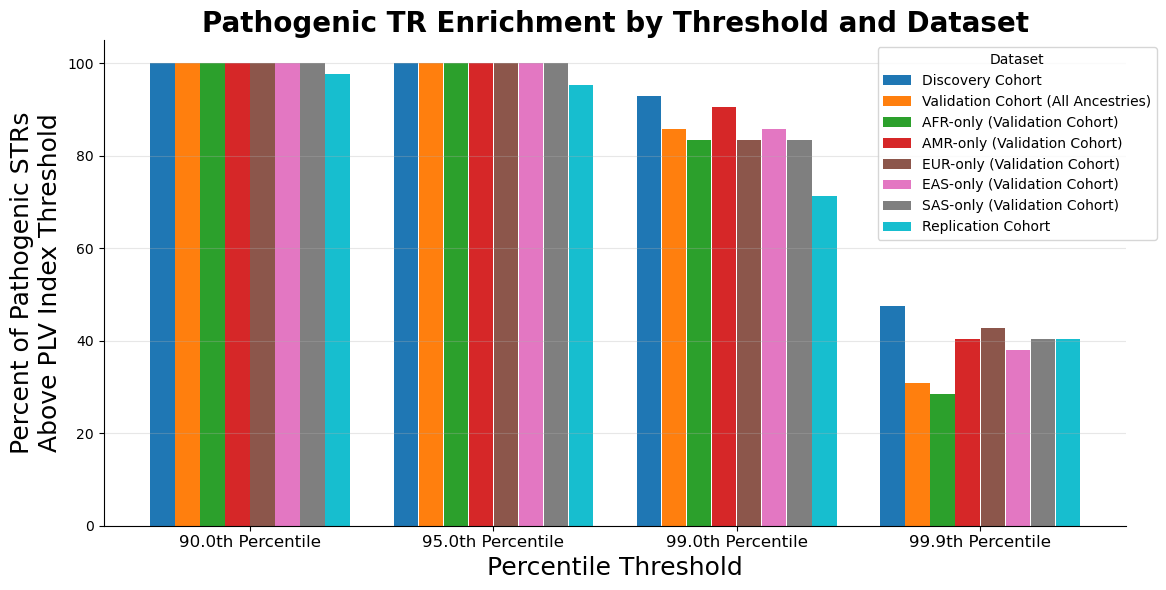

In [2]:

# Create grouped bar plot
colorPalette=['#FFF672','#F9A31B','#EB282D','#F1378A','#9D1E89','#195CAC','#06AF9B','#C7D92F','#64CCF5','0.6']
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['svg.fonttype'] = 'none'
fig, ax = plt.subplots(figsize=(12, 6))

# Get unique thresholds and datasets
threshold_labels = [f'{t*100:.1f}th Percentile' for t in thresholds]
dataset_names = list(datasets.keys())

# Set up bar positions
x = np.arange(len(threshold_labels))
width = 0.1
offsets = np.linspace(-width*3.6, width*3.6, len(dataset_names))

# Plot bars for each dataset
colors = plt.cm.tab10(np.linspace(0, 0.9, len(dataset_names)))
for idx, dataset_name in enumerate(dataset_names):
    data_subset = plot_df[plot_df['Dataset'] == dataset_name]
    values = [data_subset[data_subset['Threshold'] == tl]['percent_pathogenic_above'].values[0] 
              for tl in threshold_labels]
    ax.bar(x + offsets[idx], values, width, label=dataset_name, color=colors[idx])

# Customize plot
ax.set_xlabel('Percentile Threshold', fontsize=18)
ax.set_ylabel('Percent of Pathogenic STRs\nAbove PLV Index Threshold', fontsize=18)
ax.set_title('Pathogenic TR Enrichment by Threshold and Dataset', fontsize=20, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(threshold_labels,fontsize=12)
ax.legend(title='Dataset', bbox_to_anchor=(0.75, 1), loc='upper left')
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('figures/SupplementaryFigure6A.png',dpi=600)
plt.savefig('figures/SupplementaryFigure6A.svg')

## S6B

In [1]:
# Adotto catalog version
# initial data loading and package import
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sb
import matplotlib
from matplotlib.colors import to_rgba

mpl.rcParams['svg.fonttype'] = 'none'  # keep SVG text in SVGs

DiscoveryPerMotif=pd.read_csv('statsTables/DiscoveryCohort_lpsPerMotifStats.Adotto.txt.gz',sep='\t')
ValidationPerMotif=pd.read_csv('statsTables/ValidationCohort_lpsPerMotifStats.Adotto.txt.gz',sep='\t')
AFRPerMotif=pd.read_csv('statsTables/ValidationCohort_lpsPerMotifStats_AFR.Adotto.txt.gz',sep='\t')
AMRPerMotif=pd.read_csv('statsTables/ValidationCohort_lpsPerMotifStats_AMR.Adotto.txt.gz',sep='\t')
EURPerMotif=pd.read_csv('statsTables/ValidationCohort_lpsPerMotifStats_EUR.Adotto.txt.gz',sep='\t')
EASPerMotif=pd.read_csv('statsTables/ValidationCohort_lpsPerMotifStats_EAS.Adotto.txt.gz',sep='\t')
SASPerMotif=pd.read_csv('statsTables/ValidationCohort_lpsPerMotifStats_SAS.Adotto.txt.gz',sep='\t')

Discovery=pd.read_csv('statsTables/DiscoveryCohort_lpsPerLocusStats.Adotto.txt.gz',sep='\t')
Validation=pd.read_csv('statsTables/ValidationCohort_lpsPerLocusStats.Adotto.txt.gz',sep='\t')
AFR=pd.read_csv('statsTables/ValidationCohort_lpsPerLocusStats_AFR.Adotto.txt.gz',sep='\t')
AMR=pd.read_csv('statsTables/ValidationCohort_lpsPerLocusStats_AMR.Adotto.txt.gz',sep='\t')
EUR=pd.read_csv('statsTables/ValidationCohort_lpsPerLocusStats_EUR.Adotto.txt.gz',sep='\t')
EAS=pd.read_csv('statsTables/ValidationCohort_lpsPerLocusStats_EAS.Adotto.txt.gz',sep='\t')
SAS=pd.read_csv('statsTables/ValidationCohort_lpsPerLocusStats_SAS.Adotto.txt.gz',sep='\t')

# drop to the most common LPS motif per locus
DiscoveryPerMotif=DiscoveryPerMotif.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)
ValidationPerMotif=ValidationPerMotif.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)
AFRPerMotif=AFRPerMotif.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)
AMRPerMotif=AMRPerMotif.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)
EURPerMotif=EURPerMotif.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)
EASPerMotif=EASPerMotif.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)
SASPerMotif=SASPerMotif.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)

# function to convert motifs to their simplest rotational form with reverse complements
def complement(seq):
    complement = {'A': 'T', 'C': 'G', 'G': 'C', 'T': 'A'} 
    bases = list(seq) 
    bases = [complement[base] for base in bases] 
    return ''.join(bases)
def reverse_complement(seq):
    return complement(seq[::-1])
def simplest_motif(motif):
    i = (motif+motif).find(motif, 1, -1)
    if i != -1:
        motif = motif[:i]
    motifs = []
    b = len(motif)
    for i in range(b):
        c = motif[i:]+motif[:i]
        motifs.append(c)
    motifs = [x.upper() for x in motifs]
    # repeat with reverse complement
    motifRC=reverse_complement(motif.upper())
    i = (motifRC+motifRC).find(motifRC, 1, -1)
    if i != -1:
        motifRC = motifRC[:i]
    b = len(motifRC)
    for i in range(b):
        c = motifRC[i:]+motifRC[:i]
        motifs.append(c)    
    return(min(motifs))

# apply the simplest_motif function the data
DiscoveryPerMotif['simpleMotif']=DiscoveryPerMotif.loc[:,'LPS_Motif'].apply(simplest_motif)
ValidationPerMotif['simpleMotif']=ValidationPerMotif.loc[:,'LPS_Motif'].apply(simplest_motif)
AFRPerMotif['simpleMotif']=AFRPerMotif.loc[:,'LPS_Motif'].apply(simplest_motif)
AMRPerMotif['simpleMotif']=AMRPerMotif.loc[:,'LPS_Motif'].apply(simplest_motif)
EURPerMotif['simpleMotif']=EURPerMotif.loc[:,'LPS_Motif'].apply(simplest_motif)
EASPerMotif['simpleMotif']=EASPerMotif.loc[:,'LPS_Motif'].apply(simplest_motif)
SASPerMotif['simpleMotif']=SASPerMotif.loc[:,'LPS_Motif'].apply(simplest_motif)

# calculate percentile of standard deviation within each motif length
DiscoveryPerMotif['motifLen']=DiscoveryPerMotif.loc[:,'simpleMotif'].str.len()
ValidationPerMotif['motifLen']=ValidationPerMotif.loc[:,'simpleMotif'].str.len()
AFRPerMotif['motifLen']=AFRPerMotif.loc[:,'simpleMotif'].str.len()
AMRPerMotif['motifLen']=AMRPerMotif.loc[:,'simpleMotif'].str.len()
EURPerMotif['motifLen']=EURPerMotif.loc[:,'simpleMotif'].str.len()
EASPerMotif['motifLen']=EASPerMotif.loc[:,'simpleMotif'].str.len()
SASPerMotif['motifLen']=SASPerMotif.loc[:,'simpleMotif'].str.len()

Discovery=Discovery.merge(DiscoveryPerMotif.loc[:,['TRID','motifLen']],how='inner',on='TRID')
Validation=Validation.merge(ValidationPerMotif.loc[:,['TRID','motifLen']],how='inner',on='TRID')
AFR=AFR.merge(AFRPerMotif.loc[:,['TRID','motifLen']],how='inner',on='TRID')
AMR=AMR.merge(AMRPerMotif.loc[:,['TRID','motifLen']],how='inner',on='TRID')
EUR=EUR.merge(EURPerMotif.loc[:,['TRID','motifLen']],how='inner',on='TRID')
EAS=EAS.merge(EASPerMotif.loc[:,['TRID','motifLen']],how='inner',on='TRID')
SAS=SAS.merge(SASPerMotif.loc[:,['TRID','motifLen']],how='inner',on='TRID')

Discovery['PLVI']=Discovery.groupby('motifLen',observed=True)['std'].rank(pct=True)
Validation['PLVI']=Validation.groupby('motifLen',observed=True)['std'].rank(pct=True)
AFR['PLVI']=AFR.groupby('motifLen',observed=True)['std'].rank(pct=True)
AMR['PLVI']=AMR.groupby('motifLen',observed=True)['std'].rank(pct=True)
EUR['PLVI']=EUR.groupby('motifLen',observed=True)['std'].rank(pct=True)
EAS['PLVI']=EAS.groupby('motifLen',observed=True)['std'].rank(pct=True)
SAS['PLVI']=SAS.groupby('motifLen',observed=True)['std'].rank(pct=True)


# Define pathogenic and poly-alanine TRIDs
pathogenic=pd.read_csv('assets/pathogenicTRs_ageOfOnset_STRchiveVersion_Adotto.txt',sep='\t')
pathogenic=pathogenic.rename(columns={'TRName':'geneName'})

polyAlanineTRNames = ['ARX','NIPA1','HOXA13','PHOX2B','SOX3','HOXD13','ZIC2','RUNX2','PABPN1','FOXL2']
polyAlanineTRIDs = pathogenic.loc[pathogenic['geneName'].isin(polyAlanineTRNames),'TRID'].values
singleShiftTRNames = ['MIR7-2','COMP']
singleShiftTRIDs = pathogenic.loc[pathogenic['geneName'].isin(singleShiftTRNames),'TRID'].values
otherPathogenicTRIDs = pathogenic.loc[~pathogenic['geneName'].isin(polyAlanineTRNames),:]
otherPathogenicTRIDs = otherPathogenicTRIDs.loc[~otherPathogenicTRIDs['geneName'].isin(singleShiftTRNames),'TRID'].values



In [2]:
# Analyze the known pathogenic TR enrichment
Discovery['patho']=0
Discovery.loc[Discovery['TRID'].isin(otherPathogenicTRIDs),'patho']=1
Validation['patho']=0
Validation.loc[Validation['TRID'].isin(otherPathogenicTRIDs),'patho']=1
AFR['patho']=0
AFR.loc[AFR['TRID'].isin(otherPathogenicTRIDs),'patho']=1
AMR['patho']=0
AMR.loc[AMR['TRID'].isin(otherPathogenicTRIDs),'patho']=1
EUR['patho']=0
EUR.loc[EUR['TRID'].isin(otherPathogenicTRIDs),'patho']=1
EAS['patho']=0
EAS.loc[EAS['TRID'].isin(otherPathogenicTRIDs),'patho']=1
SAS['patho']=0
SAS.loc[SAS['TRID'].isin(otherPathogenicTRIDs),'patho']=1

from statsmodels.stats.contingency_tables import Table2x2

def calculate_enrichment_with_ci(df, percentile_threshold, pathogenic_col='patho'):
    above_threshold = df['PLVI'] > percentile_threshold
    
    a = ((df[pathogenic_col] == 1) & above_threshold).sum()
    b = ((df[pathogenic_col] == 0) & above_threshold).sum()
    c = ((df[pathogenic_col] == 1) & ~above_threshold).sum()
    d = ((df[pathogenic_col] == 0) & ~above_threshold).sum()
    
    table = Table2x2([[a, b], [c, d]])
    
    return {
        'odds_ratio': table.oddsratio,
        'p_value': table.oddsratio_pvalue(),
        'ci_95': table.oddsratio_confint(alpha=0.05),
        'contingency_table': [[a, b], [c, d]],
        'n_pathogenic_above': a,
        'n_pathogenic_total': a + c,
        'n_total_above': a + b
    }


print("\n\n=== Select Pathogenic TRs (excluding polyAlanine and singleShift TRs) ===")
for threshold in [0.90, 0.95, 0.99, 0.999]:
    for dataset in [Discovery, Validation, AFR, AMR, EUR, EAS, SAS]:
        stats = calculate_enrichment_with_ci(dataset, threshold)
        print(f"\nAbove {threshold*100:.1f}th percentile:")
        print(f"  Contingency table: {stats['contingency_table']}")
        print(f"  Odds Ratio: {stats['odds_ratio']:.2f}")
        print(f"  Confidence Interval: {stats['ci_95']}")
        print(f"  P-value: {stats['p_value']:.2e}")
        print(f"  Pathogenic above threshold: {stats['n_pathogenic_above']}/{stats['n_pathogenic_total']} ({stats['n_pathogenic_above']/stats['n_pathogenic_total']:.1%})")
        print("")



=== Select Pathogenic TRs (excluding polyAlanine and singleShift TRs) ===

Above 90.0th percentile:
  Contingency table: [[42, 178536], [0, 1605682]]
  Odds Ratio: 755.46
  Confidence Interval: (46.4821527530617, 12278.34452902028)
  P-value: 3.18e-06
  Pathogenic above threshold: 42/42 (100.0%)


Above 90.0th percentile:
  Contingency table: [[42, 178544], [0, 1605750]]
  Odds Ratio: 755.46
  Confidence Interval: (46.482038454244, 12278.314332089765)
  P-value: 3.18e-06
  Pathogenic above threshold: 42/42 (100.0%)


Above 90.0th percentile:
  Contingency table: [[40, 178545], [2, 1605736]]
  Odds Ratio: 179.87
  Confidence Interval: (43.470904743552055, 744.2420690620394)
  P-value: 7.73e-13
  Pathogenic above threshold: 40/42 (95.2%)


Above 90.0th percentile:
  Contingency table: [[42, 178532], [0, 1605662]]
  Odds Ratio: 755.47
  Confidence Interval: (46.482615195153485, 12278.46668618741)
  P-value: 3.18e-06
  Pathogenic above threshold: 42/42 (100.0%)


Above 90.0th percentile:

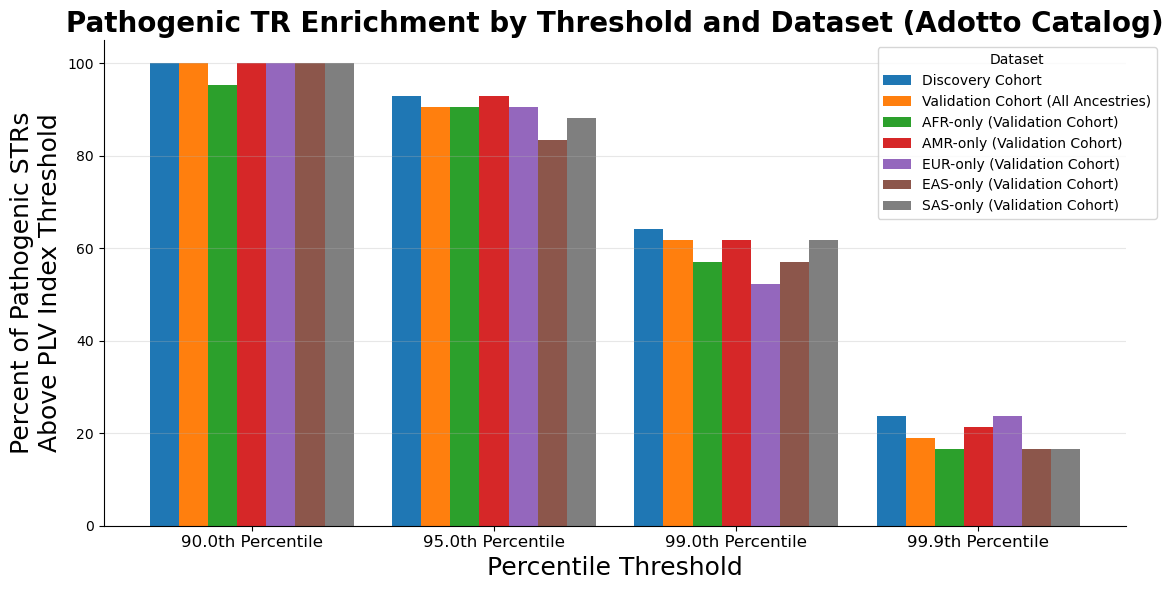

In [3]:
# Collect n_pathogenic_above values for plotting
thresholds = [0.90, 0.95, 0.99, 0.999]
datasets = {
    'Discovery Cohort': Discovery,
    'Validation Cohort (All Ancestries)': Validation,
    'AFR-only (Validation Cohort)': AFR,
    'AMR-only (Validation Cohort)': AMR,
    'EUR-only (Validation Cohort)': EUR,
    'EAS-only (Validation Cohort)': EAS,
    'SAS-only (Validation Cohort)': SAS
}

# Collect data for plotting
plot_data = []
for dataset_name, dataset in datasets.items():
    for threshold in thresholds:
        stats = calculate_enrichment_with_ci(dataset, threshold)
        plot_data.append({
            'Dataset': dataset_name,
            'Threshold': f'{threshold*100:.1f}th Percentile',
            'percent_pathogenic_above': 100*stats['n_pathogenic_above']/42
        })

# Convert to DataFrame for easier plotting
plot_df = pd.DataFrame(plot_data)

# Create grouped bar plot
colorPalette=['#FFF672','#F9A31B','#EB282D','#F1378A','#9D1E89','#195CAC','#06AF9B','#C7D92F','#64CCF5','0.6']
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['svg.fonttype'] = 'none'
fig, ax = plt.subplots(figsize=(12, 6))

# Get unique thresholds and datasets
threshold_labels = [f'{t*100:.1f}th Percentile' for t in thresholds]
dataset_names = list(datasets.keys())

# Set up bar positions
x = np.arange(len(threshold_labels))
width = 0.12
offsets = np.linspace(-width*3, width*3, len(dataset_names))

# Plot bars for each dataset
colors = plt.cm.tab10(np.linspace(0, 0.7, len(dataset_names)))
for idx, dataset_name in enumerate(dataset_names):
    data_subset = plot_df[plot_df['Dataset'] == dataset_name]
    values = [data_subset[data_subset['Threshold'] == tl]['percent_pathogenic_above'].values[0] 
              for tl in threshold_labels]
    ax.bar(x + offsets[idx], values, width, label=dataset_name, color=colors[idx])

# Customize plot
ax.set_xlabel('Percentile Threshold', fontsize=18)
ax.set_ylabel('Percent of Pathogenic STRs\nAbove PLV Index Threshold', fontsize=18)
ax.set_title('Pathogenic TR Enrichment by Threshold and Dataset (Adotto Catalog)', fontsize=20, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(threshold_labels, fontsize=12)
ax.legend(title='Dataset', bbox_to_anchor=(0.75, 1), loc='upper left')
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('figures/SupplementaryFigure6B.png',dpi=600)
plt.savefig('figures/SupplementaryFigure6B.svg')

# S7: Limitations of disease-associated TR Enrichment with Population Variation

## S7A

In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib as mpl
from collections import Counter, defaultdict
import argparse
import sys


def get_canonical_kmer(kmer):
    """
    Get the lexicographically smallest rotation of a k-mer.

    For example, 'GAAGG' and 'AAGGG' both return 'AAGGG'.
    """
    if not kmer:
        return kmer

    # Generate all rotations and return the lexicographically smallest
    rotations = [kmer[i:] + kmer[:i] for i in range(len(kmer))]
    return min(rotations)


def get_all_rotations(kmer):
    """
    Get all rotations of a k-mer.
    """
    return [kmer[i:] + kmer[:i] for i in range(len(kmer))]


def extract_all_kmers(sequences, k_sizes):
    """
    Extract all k-mers of specified sizes from all sequences.

    Args:
        sequences: List of sequences to extract k-mers from
        k_sizes: List of k-mer sizes to extract (e.g., [3, 5, 6])

    Returns a Counter of canonical k-mer frequencies.
    """
    kmer_counts = Counter()

    for seq in sequences:
        if pd.isna(seq) or seq == '':
            continue
        seq = str(seq).upper()

        # Extract k-mers of specified sizes
        for k in k_sizes:
            if k > len(seq):
                continue
            for i in range(len(seq) - k + 1):
                kmer = seq[i:i+k]
                # Convert to canonical form (lexicographically smallest rotation)
                canonical = get_canonical_kmer(kmer)
                kmer_counts[canonical] += 1

    return kmer_counts


def is_perfect_repetition(kmer):
    """
    Check if a k-mer is a perfect repetition of a shorter k-mer.

    For example, 'AAGAAGAAGAAG' is a perfect repetition of 'AAG'.
    Returns (True, base_kmer) if it's a perfect repetition, (False, None) otherwise.
    """
    kmer_len = len(kmer)

    # Try all possible divisor lengths
    for base_len in range(1, kmer_len):
        if kmer_len % base_len == 0:
            # Check if kmer is made of perfect repetitions of the base
            num_reps = kmer_len // base_len
            base = kmer[:base_len]
            if base * num_reps == kmer:
                return True, base

    return False, None


def filter_subsequence_kmers(kmer_counts, sequences):
    """
    Filter out k-mers that only appear as subsequences of other k-mers.

    If k-mer A is a subsequence of k-mer B, and all occurrences of A
    are within occurrences of B, then A is removed.
    Works with canonical k-mers and their rotations.

    Also filters out k-mers that are perfect repetitions of shorter k-mers.
    """
    # Sort k-mers by length (longest first) then by frequency (most frequent first)
    sorted_kmers = sorted(kmer_counts.items(), key=lambda x: (len(x[0]), x[1]), reverse=True)

    filtered_kmers = {}
    removed_kmers = set()
    repetition_removed = []

    for kmer, count in sorted_kmers:
        if kmer in removed_kmers:
            continue

        # Filter out k-mers that are perfect repetitions of shorter k-mers
        is_rep, base = is_perfect_repetition(kmer)
        if is_rep:
            # Check if the base k-mer (or its canonical form) exists
            canonical_base = get_canonical_kmer(base)
            if canonical_base in kmer_counts:
                removed_kmers.add(kmer)
                repetition_removed.append((kmer, canonical_base))
                continue

        # Check if this k-mer is a subsequence of any larger, already-accepted k-mer
        is_pure_subsequence = False

        for larger_kmer in filtered_kmers:
            # Check if any rotation of kmer appears in any rotation of larger_kmer
            kmer_rotations = get_all_rotations(kmer)
            larger_rotations = get_all_rotations(larger_kmer)

            is_subsequence = False
            for kr in kmer_rotations:
                for lr in larger_rotations:
                    if len(lr) > len(kr) and kr in lr:
                        is_subsequence = True
                        break
                if is_subsequence:
                    break

            if not is_subsequence:
                continue

            # Count how many times kmer appears independently vs within larger_kmer
            independent_count = 0
            within_larger_count = 0

            for seq in sequences:
                if pd.isna(seq) or seq == '':
                    continue
                seq = str(seq).upper()

                # Find all occurrences of any rotation of larger_kmer
                larger_positions = []
                for lr in larger_rotations:
                    start = 0
                    while True:
                        pos = seq.find(lr, start)
                        if pos == -1:
                            break
                        larger_positions.append((pos, pos + len(lr)))
                        start = pos + 1

                # Find all occurrences of any rotation of kmer
                for kr in kmer_rotations:
                    start = 0
                    while True:
                        pos = seq.find(kr, start)
                        if pos == -1:
                            break

                        # Check if this occurrence is within any larger_kmer occurrence
                        is_within = False
                        for lstart, lend in larger_positions:
                            if pos >= lstart and pos + len(kr) <= lend:
                                is_within = True
                                break

                        if is_within:
                            within_larger_count += 1
                        else:
                            independent_count += 1

                        start = pos + 1

            # If all occurrences are within the larger k-mer, mark as pure subsequence
            if independent_count == 0 and within_larger_count > 0:
                is_pure_subsequence = True
                break

        if not is_pure_subsequence:
            filtered_kmers[kmer] = count
        else:
            removed_kmers.add(kmer)

    # Print diagnostic information about filtered repetitions
    if repetition_removed:
        print(f"\nFiltered {len(repetition_removed)} k-mers that are perfect repetitions:")
        for kmer, base in repetition_removed[:10]:  # Show first 10
            num_reps = len(kmer) // len(base)
            print(f"  {kmer} ({len(kmer)}bp) = {num_reps}x {base} ({len(base)}bp)")
        if len(repetition_removed) > 10:
            print(f"  ... and {len(repetition_removed) - 10} more")

    return filtered_kmers


def decompose_sequence(seq, top_kmers):
    """
    Decompose a sequence into k-mers, prioritizing longer and more common k-mers.
    Matches any rotation of the canonical k-mers.

    Returns a list of (kmer, length, position) tuples where:
    - kmer: the canonical k-mer or 'other'
    - length: the actual length of the matched segment
    - position: the starting position in the sequence
    """
    if pd.isna(seq) or seq == '':
        return []

    seq = str(seq).upper()
    decomposition = []

    # Sort k-mers by length (longest first) then by frequency (most common first)
    sorted_kmers = sorted(top_kmers, key=lambda x: (len(x), top_kmers[x]), reverse=True)

    position = 0
    while position < len(seq):
        matched = False

        # Try to match k-mers starting from longest
        for canonical_kmer in sorted_kmers:
            # Try all rotations of this canonical k-mer
            rotations = get_all_rotations(canonical_kmer)
            for rotation in rotations:
                if seq[position:position+len(rotation)] == rotation:
                    # Store the canonical form with the actual matched length
                    decomposition.append((canonical_kmer, len(rotation), position))
                    position += len(rotation)
                    matched = True
                    break
            if matched:
                break

        # If no match, add as 'other' with length 1
        if not matched:
            decomposition.append(('other', 1, position))
            position += 1

    # Merge consecutive 'other' segments to avoid thin lines in the plot
    merged_decomposition = []
    for kmer, length, pos in decomposition:
        if kmer == 'other' and merged_decomposition and merged_decomposition[-1][0] == 'other':
            # Extend the previous 'other' segment
            prev_kmer, prev_length, prev_pos = merged_decomposition[-1]
            merged_decomposition[-1] = (prev_kmer, prev_length + length, prev_pos)
        else:
            merged_decomposition.append((kmer, length, pos))

    return merged_decomposition


def create_waterfall_plot(df, output_file_base='waterfall_plot', k_sizes=None, N_kmers=10):
    """
    Create a waterfall plot showing k-mer composition of alleles.

    Args:
        df: DataFrame with allele1 and allele2 columns
        output_file_base: Output file name without file extension
        k_sizes: List of k-mer sizes to extract (e.g., [3, 5, 6])
    """
    if k_sizes is None:
        k_sizes = list(range(1, 16))  # Default: 1-15
    # Collect all sequences
    all_sequences = []

    for _, row in df.iterrows():
        if 'allele1' in row and not pd.isna(row['allele1']):
            all_sequences.append(str(row['allele1']).upper())
        if 'allele2' in row and not pd.isna(row['allele2']):
            all_sequences.append(str(row['allele2']).upper())

    if not all_sequences:
        print("Error: No valid allele sequences found in input file.")
        sys.exit(1)

    print(f"Found {len(all_sequences)} total alleles.")

    # Group by unique alleles and count occurrences
    allele_counts = Counter(all_sequences)
    print(f"Found {len(allele_counts)} unique alleles.")

    # Use all unique alleles, sorted by length then alphabetically
    allele_data = sorted(allele_counts.items(),
                         key=lambda x: (len(x[0]), x[0]),
                         reverse=False)
    print(f"Plotting all {len(allele_data)} alleles.")
    all_sequences = [a[0] for a in allele_data]


    # Extract all k-mers (use all sequences for frequency calculation)
    print(f"Extracting k-mers (sizes: {sorted(k_sizes)})...")
    kmer_counts = extract_all_kmers(all_sequences, k_sizes)
    print(f"Found {len(kmer_counts)} unique k-mers.")

    # Filter subsequence k-mers
    print("Filtering subsequence k-mers...")
    filtered_kmers = filter_subsequence_kmers(kmer_counts, all_sequences)
    print(f"After filtering: {len(filtered_kmers)} k-mers remain.")

    # Get top N k-mers
    top_N_kmers = dict(Counter(filtered_kmers).most_common(N_kmers))
    print(f"\nTop {N_kmers} k-mers:")
    for kmer, count in top_N_kmers.items():
        print(f"  {kmer}: {count} occurrences")

    # Create color map
    colors = plt.cm.tab10(range(10))
    kmer_colors = {kmer: colors[i] for i, kmer in enumerate(top_N_kmers.keys())}
    kmer_colors['other'] = "#404040"

    # Create plot with two subplots: main waterfall and count bar
    mpl.rcParams['pdf.fonttype'] = 42
    mpl.rcParams['svg.fonttype'] = 'none'
    fig = plt.figure(figsize=(8,10))

    # Main waterfall plot (left side, takes up most space)
    ax_main = plt.subplot2grid((1, 20), (0, 0), colspan=17)

    # Count bar plot (right side, narrow)
    ax_count = plt.subplot2grid((1, 20), (0, 17), colspan=3)

    y_positions = range(len(allele_data))

    # Plot alleles as segmented sequences
    for i, (seq, count) in enumerate(allele_data):
        decomposition = decompose_sequence(seq, top_N_kmers)

        # Validate complete coverage
        total_length = sum(length for _, length, _ in decomposition)
        if total_length != len(seq):
            print(f"Warning: Sequence {i} has incomplete coverage: {total_length} != {len(seq)}")

        # Plot each k-mer segment
        current_pos = 0
        for kmer, length, _ in decomposition:
            color = kmer_colors.get(kmer, kmer_colors['other'])

            ax_main.barh(i, length, left=current_pos, height=0.8,
                        color=color, edgecolor='none', linewidth=0)
            current_pos += length

    # Set labels for main plot
    max_length = max(len(seq) for seq, _ in allele_data)

    ax_main.set_yticks([])
    ax_main.set_xlabel('Position (bp)', fontsize=20)
    ax_main.tick_params(labelsize=14)
    #ax_main.set_title('Tandem Repeat Allele Composition - Waterfall Plot', fontsize=14, fontweight='bold')
    ax_main.set_xlim(0, max_length *  1.01)

    # Plot observation counts
    counts = [count for _, count in allele_data]
    ax_count.barh(y_positions, counts, height=0.8, color='#4CAF50', alpha=0.7)
    ax_count.set_yticks(y_positions)
    ax_count.set_yticklabels([])  # No labels, shared with main plot
    ax_count.set_xlabel('Count', fontsize=14)
    ax_count.tick_params(labelsize=10)
    #ax_count.set_title('Obs.', fontsize=14)
    ax_count.set_xlim(0, max(counts) * 1.2)

    # Add count values as text
    for i, count in enumerate(counts):
        ax_count.text(count + max(counts) * 0.02, i, str(count),
                     va='center', ha='left', fontsize=8)

    # Create legend
    legend_elements = [mpatches.Patch(facecolor=kmer_colors[kmer], label=kmer)
                      for kmer in top_N_kmers.keys()]
    legend_elements.append(mpatches.Patch(facecolor=kmer_colors['other'], label='other'))

    ax_main.legend(handles=legend_elements,
                  title='LPS Motif', fontsize=14)

    plt.tight_layout()
    plt.savefig(f'{output_file_base}.svg', bbox_inches='tight')
    plt.savefig(f'{output_file_base}.png',dpi=600, bbox_inches='tight')
    print(f"\nWaterfall plot saved to: {output_file_base}")
    plt.close()

In [34]:
import pandas
allDiseaseAssociatedAlleles=pandas.read_csv('assets/pathogenicSTRs_alleleInfo_noIDs.txt',sep='\t',header=None,names=['TRID','allele1','allele2','allele1_lps_length','allele1_lps_motif','allele2_lps_length','allele2_lps_motif','allele1_len','allele2_len'])
phox2bAlleles=allDiseaseAssociatedAlleles.loc[allDiseaseAssociatedAlleles['TRID']=='4-41745972-41746032-GCN',:]
outputBaseName="figures/SupplementaryFigure17A"
kmers=[3]
create_waterfall_plot(phox2bAlleles, outputBaseName, kmers, N_kmers=4)

Found 1086 total alleles.
Found 12 unique alleles.
Plotting all 12 alleles.
Extracting k-mers (sizes: [3])...
Found 7 unique k-mers.
Filtering subsequence k-mers...
After filtering: 7 k-mers remain.

Top 4 k-mers:
  CCG: 333 occurrences
  CTG: 229 occurrences
  CGG: 45 occurrences
  AGC: 11 occurrences

Waterfall plot saved to: figures/SupplementaryFigure17A


## S7B

In [35]:
runx2Alleles=allDiseaseAssociatedAlleles.loc[allDiseaseAssociatedAlleles['TRID']=='6-45422750-45422792-GCN',:]
outputBaseName="figures/SupplementaryFigure17B"
kmers=[3]
create_waterfall_plot(runx2Alleles, outputBaseName, kmers, N_kmers=4)

Found 1086 total alleles.
Found 10 unique alleles.
Plotting all 10 alleles.
Extracting k-mers (sizes: [3])...
Found 6 unique k-mers.
Filtering subsequence k-mers...
After filtering: 6 k-mers remain.

Top 4 k-mers:
  CGG: 254 occurrences
  CTG: 45 occurrences
  AGC: 43 occurrences
  AGG: 8 occurrences

Waterfall plot saved to: figures/SupplementaryFigure17B


## S7C

In [4]:
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sb
import matplotlib
from matplotlib.colors import to_rgba
import scipy.stats

mpl.rcParams['svg.fonttype'] = 'none'  # keep SVG text in SVGs

totalLen=pd.read_csv('statsTables/DiscoveryCohort_alleleLengthStats.TR_Explorer_1.0.1.txt.gz',sep='\t')

# calculate percentile of standard deviation
totalLen['percentile_stdev']=totalLen.loc[:,'std'].rank(pct=True)

# Define pathogenic and poly-alanine TRIDs
pathogenic=pd.read_csv('assets/pathogenicTRIDs_TRExplorer_v1.0.1_STRchiveFiltered_noVNTRs_withAnno.txt',sep='\t')
polyAlanineTRNames = ['ARX','NIPA1','HOXA13','PHOX2B','SOX3','HOXD13','ZIC2','RUNX2','PABPN1','FOXL2']
polyAlanineTRIDs = pathogenic.loc[pathogenic['geneName'].isin(polyAlanineTRNames),'TRID'].values
singleShiftTRNames = ['MIR7-2','COMP']
singleShiftTRIDs = pathogenic.loc[pathogenic['geneName'].isin(singleShiftTRNames),'TRID'].values
otherPathogenicTRIDs = pathogenic.loc[~pathogenic['geneName'].isin(polyAlanineTRNames),:]
otherPathogenicTRIDs = otherPathogenicTRIDs.loc[~otherPathogenicTRIDs['geneName'].isin(singleShiftTRNames),'TRID'].values

# define pathogenic VNTRs
vntrs=pd.read_csv('assets/pathogenicTRIDs_TRExplorer_v1.0.1_STRchiveVNTRs.txt',sep='\t')
vntrTRIDs = vntrs.loc[:,'TRID'].values

# mark pathogenic TRs
totalLen['patho']=0
totalLen.loc[totalLen['TRID'].isin(polyAlanineTRIDs),'patho']=1

# calculate generalized odds ratio for the poly-alanine set
group1=totalLen.loc[totalLen['patho']==1,'std'].dropna().values
group2=totalLen.loc[totalLen['patho']==0,'std'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Poly-Alanine Loci:")
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")
print()


# repeat for single shifters
totalLen['patho']=0
totalLen.loc[totalLen['TRID'].isin(singleShiftTRIDs),'patho']=1

# calculate generalized odds ratio for the single shift set
group1=totalLen.loc[totalLen['patho']==1,'std'].dropna().values
group2=totalLen.loc[totalLen['patho']==0,'std'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Single Shift Loci:")
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")
print()

# repeat for single shifters
totalLen['patho']=0
totalLen.loc[totalLen['TRID'].isin(vntrTRIDs),'patho']=1

# calculate generalized odds ratio for the VNTR set
group1=totalLen.loc[totalLen['patho']==1,'std'].dropna().values
group2=totalLen.loc[totalLen['patho']==0,'std'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"VNTR Loci:")
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")
print()

Poly-Alanine Loci:
Raw U Statistic: 26470898.0
P-Value: 0.03711520625723619
Probability of Superiority: 0.6625
Generalized Odds Ratio: 1.9628

Single Shift Loci:
Raw U Statistic: 5018391.5
P-Value: 0.367846383430823
Probability of Superiority: 0.5652
Generalized Odds Ratio: 1.2998

VNTR Loci:
Raw U Statistic: 16292026.0
P-Value: 0.0011165254302898937
Probability of Superiority: 0.9174
Generalized Odds Ratio: 11.1084



In [5]:
# repeat, normalized to reference motif 
# calculate reference motif  
totalLen[['chr','start','end','refMotif']]=totalLen.loc[:,'TRID'].str.split(',',expand=True).iloc[:,0].str.split('-',expand=True)
totalLen['motifLen']=totalLen.loc[:,'refMotif'].str.len()

# calculate percentile of standard deviation grouped by ref motif length
totalLen['percentile_stdev']=totalLen.groupby('motifLen',observed=True)['std'].rank(pct=True)

# mark pathogenic TRs
totalLen['patho']=0
totalLen.loc[totalLen['TRID'].isin(polyAlanineTRIDs),'patho']=1

# calculate generalized odds ratio for the poly-alanine set
group1=totalLen.loc[totalLen['patho']==1,'percentile_stdev'].dropna().values
group2=totalLen.loc[totalLen['patho']==0,'percentile_stdev'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Poly-Alanine Loci:")
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")
print()


# repeat for single shifters
totalLen['patho']=0
totalLen.loc[totalLen['TRID'].isin(singleShiftTRIDs),'patho']=1

# calculate generalized odds ratio for the single shift set
group1=totalLen.loc[totalLen['patho']==1,'percentile_stdev'].dropna().values
group2=totalLen.loc[totalLen['patho']==0,'percentile_stdev'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Single Shift Loci:")
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")
print()

# repeat for single shifters
totalLen['patho']=0
totalLen.loc[totalLen['TRID'].isin(vntrTRIDs),'patho']=1

# calculate generalized odds ratio for the VNTR set
group1=totalLen.loc[totalLen['patho']==1,'percentile_stdev'].dropna().values
group2=totalLen.loc[totalLen['patho']==0,'percentile_stdev'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"VNTR Loci:")
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")
print()

Poly-Alanine Loci:
Raw U Statistic: 32989574.0
P-Value: 0.0003182138000171396
Probability of Superiority: 0.8256
Generalized Odds Ratio: 4.7349

Single Shift Loci:
Raw U Statistic: 6825544.5
P-Value: 0.09198394819130323
Probability of Superiority: 0.7687
Generalized Odds Ratio: 3.3234

VNTR Loci:
Raw U Statistic: 12714641.0
P-Value: 0.06549208582579208
Probability of Superiority: 0.7160
Generalized Odds Ratio: 2.5207



In [6]:
# repeat for LPS length
lpsPerMotif=pd.read_csv('statsTables/DiscoveryCohort_lpsPerMotifStats.TR_Explorer_1.0.1.txt.gz',sep='\t')
lps=pd.read_csv('statsTables/DiscoveryCohort_lpsPerLocusStats.TR_Explorer_1.0.1.txt.gz',sep='\t')

# drop to the most common LPS motif per locus
lpsPerMotif=lpsPerMotif.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)

# function to convert motifs to their simplest rotational form
def simplest_motif(motif):
    i = (motif+motif).find(motif, 1, -1)
    if i != -1:
        motif = motif[:i]
    motifs = []
    b = len(motif)
    for i in range(b):
        c = motif[i:]+motif[:i]
        motifs.append(c)
    motifs = [x.upper() for x in motifs]   
    return(min(motifs))

# apply the simplest_motif function the data
lpsPerMotif['simpleMotif']=lpsPerMotif.loc[:,'LPS_Motif'].apply(simplest_motif)
lpsPerMotif['motifLen']=lpsPerMotif.loc[:,'simpleMotif'].str.len()

lps=lps.merge(lpsPerMotif.loc[:,['TRID','motifLen','simpleMotif']],how='inner',on='TRID')
lps['percentile_stdev']=lps['std'].rank(pct=True)

# mark pathogenic TRs
lps['patho']=0
lps.loc[lps['TRID'].isin(otherPathogenicTRIDs),'patho']=1

# mark pathogenic TRs
lps['patho']=0
lps.loc[lps['TRID'].isin(polyAlanineTRIDs),'patho']=1

# calculate generalized odds ratio for the poly-alanine set
group1=lps.loc[lps['patho']==1,'percentile_stdev'].dropna().values
group2=lps.loc[lps['patho']==0,'percentile_stdev'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Poly-Alanine Loci:")
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")
print()


# repeat for single shifters
lps['patho']=0
lps.loc[lps['TRID'].isin(singleShiftTRIDs),'patho']=1

# calculate generalized odds ratio for the single shift set
group1=lps.loc[lps['patho']==1,'percentile_stdev'].dropna().values
group2=lps.loc[lps['patho']==0,'percentile_stdev'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Single Shift Loci:")
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")
print()

# repeat for single shifters
lps['patho']=0
lps.loc[lps['TRID'].isin(vntrTRIDs),'patho']=1

# calculate generalized odds ratio for the VNTR set
group1=lps.loc[lps['patho']==1,'percentile_stdev'].dropna().values
group2=lps.loc[lps['patho']==0,'percentile_stdev'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"VNTR Loci:")
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")
print()

Poly-Alanine Loci:
Raw U Statistic: 16471638.5
P-Value: 0.38661324502624894
Probability of Superiority: 0.5300
Generalized Odds Ratio: 1.1277

Single Shift Loci:
Raw U Statistic: 3476445.0
P-Value: 0.7111116192742843
Probability of Superiority: 0.3915
Generalized Odds Ratio: 0.6434

VNTR Loci:
Raw U Statistic: 16965719.5
P-Value: 0.00047594257597441153
Probability of Superiority: 0.9554
Generalized Odds Ratio: 21.3970



In [7]:
# repeat with LPS length normalized to length of LPS motif
lps['PLVI']=lps.groupby('motifLen',observed=True)['std'].rank(pct=True, method='max')

# mark pathogenic TRs
lps['patho']=0
lps.loc[lps['TRID'].isin(polyAlanineTRIDs),'patho']=1

# calculate generalized odds ratio for the poly-alanine set
group1=lps.loc[lps['patho']==1,'PLVI'].dropna().values
group2=lps.loc[lps['patho']==0,'PLVI'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Poly-Alanine Loci:")
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")
print()


# repeat for single shifters
lps['patho']=0
lps.loc[lps['TRID'].isin(singleShiftTRIDs),'patho']=1

# calculate generalized odds ratio for the single shift set
group1=lps.loc[lps['patho']==1,'PLVI'].dropna().values
group2=lps.loc[lps['patho']==0,'PLVI'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Single Shift Loci:")
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")
print()

# repeat for single shifters
lps['patho']=0
lps.loc[lps['TRID'].isin(vntrTRIDs),'patho']=1

# calculate generalized odds ratio for the VNTR set
group1=lps.loc[lps['patho']==1,'PLVI'].dropna().values
group2=lps.loc[lps['patho']==0,'PLVI'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"VNTR Loci:")
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")
print()

Poly-Alanine Loci:
Raw U Statistic: 25556603.5
P-Value: 0.0014581365313542246
Probability of Superiority: 0.8223
Generalized Odds Ratio: 4.6290

Single Shift Loci:
Raw U Statistic: 4776559.0
P-Value: 0.42572604991368523
Probability of Superiority: 0.5379
Generalized Odds Ratio: 1.1642

VNTR Loci:
Raw U Statistic: 13211704.0
P-Value: 0.04430081251266834
Probability of Superiority: 0.7440
Generalized Odds Ratio: 2.9056



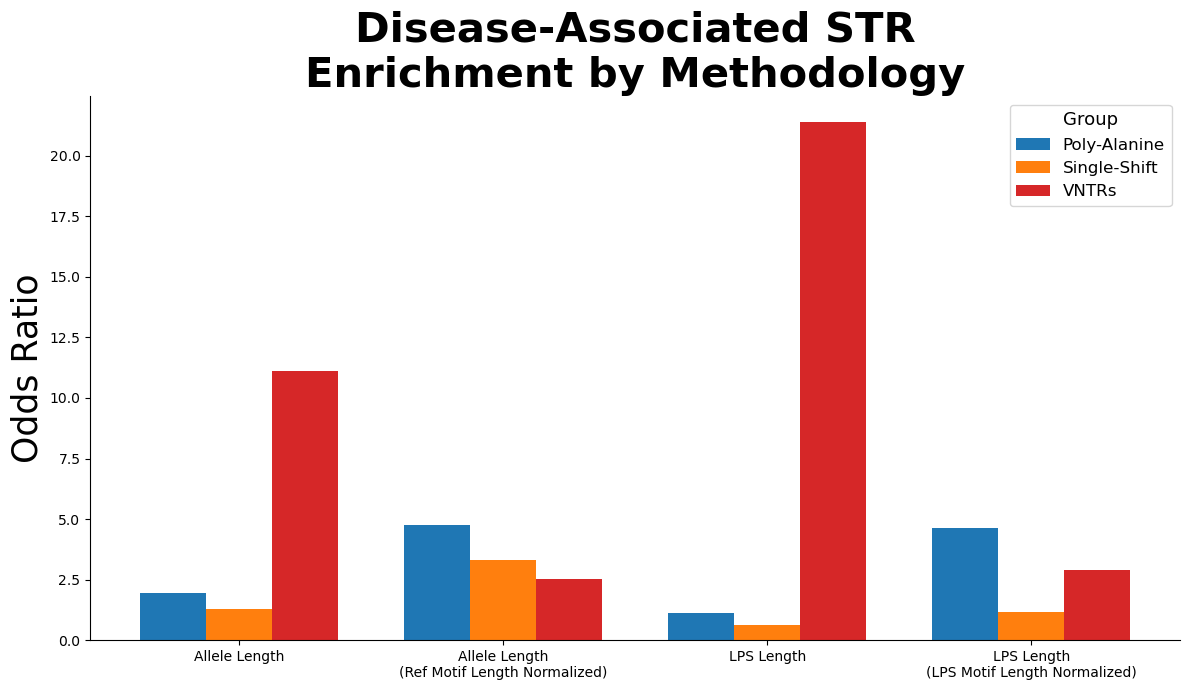

In [8]:
# Grouped bar plot for S7C: odds ratios by group and methodology
import matplotlib.ticker as mticker

# Odds ratios extracted from the analyses above
odds_ratios = {
    'Poly-Alanine':  [1.9628, 4.7348, 1.1277, 4.629],
    'Single-Shift':  [1.2998, 3.3234, 0.6434, 1.1642],
    'VNTRs':         [11.1084, 2.5207, 21.3970, 2.9056],
}
categoryNames = [
    'Allele Length',
    'Allele Length\n(Ref Motif Length Normalized)',
    'LPS Length',
    'LPS Length\n(LPS Motif Length Normalized)',
]
groupNames = list(odds_ratios.keys())

mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['svg.fonttype'] = 'none'
fig, ax = plt.subplots(figsize=(12, 7))

x = np.arange(len(categoryNames))
n_groups = len(groupNames)
width = 0.25
offsets = np.linspace(-(n_groups - 1) * width / 2, (n_groups - 1) * width / 2, n_groups)

colors = plt.cm.tab10(np.linspace(0, 0.3, n_groups))
for idx, group in enumerate(groupNames):
    ax.bar(x + offsets[idx], odds_ratios[group], width, label=group, color=colors[idx])

ax.set_ylabel('Odds Ratio', fontsize=25)
ax.set_title('Disease-Associated STR\nEnrichment by Methodology', fontsize=30, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(categoryNames)
#plt.yscale('log')
ax.yaxis.set_major_formatter(mticker.ScalarFormatter())
ax.yaxis.set_minor_formatter(mticker.ScalarFormatter())
ax.ticklabel_format(axis='y', style='plain')
ax.legend(title='Group', fontsize=12, title_fontsize=13)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('figures/SupplementaryFigure7C.svg')
plt.savefig('figures/SupplementaryFigure7C.png', dpi=600)

# S8: Multi-modality and regulatory STRs

## S8A

In [ ]:
# in Researcher Workbench, run the skewness analysis, then generate ridge plots
! scripts/skewnessAnalyses.py --alleles selectLoci_alleleInfo_withAncestry.txt.gz --outdir skewnessResults --min-dip 0.1
# YEATS2 locus plotting allele length by ancestry
! scripts/ridgePlotLocus.py --alleles selectLoci_alleleInfo_withAncestry.txt.gz --trid 3-183712187-183712222-TTTTA --metric alleleLength --group-by ancestry --out figures/SupplementaryFigure8A.png --dpi 600 --no-pooled 

## S8B

In [ ]:
# YEATS2 locus plotting allele length by motif
! scripts/ridgePlotLocus.py --alleles selectLoci_alleleInfo_withAncestry.txt.gz --trid 3-183712187-183712222-TTTTA --metric alleleLength --group-by motif --out figures/SupplementaryFigure8B.png --dpi 600 --no-pooled 

## S8C

In [8]:
# Enrichment for regulatory STRs
import pandas
import numpy as np
import scipy.stats
lps=pandas.read_csv('statsTables/DiscoveryCohort_lpsPerLocusStats.TR_Explorer_1.0.1_withPLVI.txt.gz',sep='\t')
totalLen=pandas.read_csv('statsTables/DiscoveryCohort_alleleLengthStats.TR_Explorer_1.0.1.txt.gz',sep='\t')

eSTR=pandas.read_csv('assets/eSTR_TRExplorer_TRIDs_CAVIAR_0.3.txt',sep='\t',low_memory=False,header=None,names=['TRID'])
sTR=pandas.read_csv('assets/sQTL_TRIDs.txt',sep='\t',header=None,names=['TRID'])
xTR=pandas.read_csv('assets/TR_xQTL_TRIDs.txt',sep='\t',header=None,names=['TRID'])
pathogenic=pandas.read_csv('assets/pathogenicTRIDs_TRExplorer_v1.0.1_STRchiveFiltered_noVNTRs_withAnno.txt',sep='\t')
polyAlanineTRNames = ['ARX','NIPA1','HOXA13','PHOX2B','SOX3','HOXD13','ZIC2','RUNX2','PABPN1','FOXL2']
polyAlanineTRIDs = pathogenic.loc[pathogenic['geneName'].isin(polyAlanineTRNames),'TRID'].values
singleShiftTRNames = ['MIR7-2','COMP']
singleShiftTRIDs = pathogenic.loc[pathogenic['geneName'].isin(singleShiftTRNames),'TRID'].values
otherPathogenicTRIDs = pathogenic.loc[~pathogenic['geneName'].isin(polyAlanineTRNames),:]
otherPathogenicTRIDs = otherPathogenicTRIDs.loc[~otherPathogenicTRIDs['geneName'].isin(singleShiftTRNames),'TRID'].values
allPathogenicTRIDs = pathogenic.loc[:,'TRID'].values
utrCGGPathoTRIDs=["1-94418421-94418442-GCC","X-148500610-148500625-GCC,X-148500697-148500712-GCCGC,X-148500732-148500742-CCG,X-148500743-148500753-GCC","9-27573528-27573546-GGCCCC","11-119206289-119206322-CGG","X-147912050-147912110-CGG","19-14496041-14496074-CCG","2-190880872-190880920-GCA","8-104588961-104589000-CGA","1-149390802-149390841-GGC","10-79826383-79826404-GGC","5-146878727-146878757-GCT","12-123533720-123533750-GGC","16-17470907-17470922-GCC"]
pathoTRs=lps.loc[:,['TRID']]
pathoTRs[['allPatho','utrCGG']]=0
pathoTRs.loc[lps['TRID'].isin(otherPathogenicTRIDs),'allPatho']=1
pathoTRs.loc[lps['TRID'].isin(utrCGGPathoTRIDs),'utrCGG']=1


lps[['eSTR','sTR','xTR','patho']]=0
totalLen[['eSTR','sTR','xTR','patho']]=0
pathoTRs[['eSTR','sTR','xTR']]=0
lps.loc[lps['TRID'].isin(eSTR.TRID.values),'eSTR']=1
lps.loc[lps['TRID'].isin(sTR.TRID.values),'sTR']=1
lps.loc[lps['TRID'].isin(xTR.TRID.values),'xTR']=1
lps.loc[lps['TRID'].isin(otherPathogenicTRIDs),'patho']=1
totalLen.loc[totalLen['TRID'].isin(eSTR.TRID.values),'eSTR']=1
totalLen.loc[totalLen['TRID'].isin(sTR.TRID.values),'sTR']=1
totalLen.loc[totalLen['TRID'].isin(xTR.TRID.values),'xTR']=1
totalLen.loc[totalLen['TRID'].isin(otherPathogenicTRIDs),'patho']=1
pathoTRs.loc[pathoTRs['TRID'].isin(eSTR.TRID.values),'eSTR']=1
pathoTRs.loc[pathoTRs['TRID'].isin(sTR.TRID.values),'sTR']=1
pathoTRs.loc[pathoTRs['TRID'].isin(xTR.TRID.values),'xTR']=1

 
# metric name -> (table, column)
metrics = {
    'PLVI':           (lps,              'PLVI'),
    'PLV':            (lps,              'std'),
    'medianLPSLen':   (lps,              '50thPercentile'),
    'medianTotalLen': (totalLen,         '50thPercentile'),
    'diseaseSTRs':    (pathoTRs,         'allPatho'),
    'diseaseUTRCGGs': (pathoTRs,         'utrCGG'),
}
groups=['eSTR','sTR','xTR','patho']


def calculate_generalized_odds_ratio(group1, group2):
    u_stat, p_value = scipy.stats.mannwhitneyu(group1, group2, alternative='greater')
    n1=len(group1)
    n2=len(group2)
    prob_superiority = u_stat / (n1*n2)
    odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
    return p_value, odds_ratio

results_collection = []
for metricName, (df, col) in metrics.items(): 
    for groupName in groups:
        if ((groupName=='patho') & (metricName in ['diseaseSTRs','diseaseUTRCGGs'])):
            continue
        group1=df.loc[df[groupName]==1,col].dropna().values
        group2=df.loc[df[groupName]==0,col].dropna().values
        p_value, odds_ratio = calculate_generalized_odds_ratio(group1, group2)
        results_collection.append({
            'condition': f'{metricName} vs {groupName}',
            'p_value': p_value,
            'odds_ratio': odds_ratio,
        })
 
results = pandas.DataFrame(results_collection)
 
pandas.set_option('display.width', 200)
print(results.to_string(index=False))


              condition       p_value  odds_ratio
           PLVI vs eSTR  0.000000e+00    3.520883
            PLVI vs sTR  0.000000e+00   10.838700
            PLVI vs xTR  0.000000e+00    6.858280
          PLVI vs patho  1.394721e-29  300.044833
            PLV vs eSTR  0.000000e+00    4.560624
             PLV vs sTR  0.000000e+00   16.554348
             PLV vs xTR  0.000000e+00    8.937742
           PLV vs patho  1.870887e-30   66.651449
   medianLPSLen vs eSTR 2.971467e-276    2.769090
    medianLPSLen vs sTR  0.000000e+00   18.178698
    medianLPSLen vs xTR  0.000000e+00    7.023168
  medianLPSLen vs patho  1.009290e-27   36.218321
 medianTotalLen vs eSTR 5.467159e-292    2.887297
  medianTotalLen vs sTR  0.000000e+00   11.890171
  medianTotalLen vs xTR  0.000000e+00    7.168081
medianTotalLen vs patho  4.811213e-26   24.100236
    diseaseSTRs vs eSTR  4.375491e-01    1.004369
     diseaseSTRs vs sTR  4.662814e-01    1.001025
     diseaseSTRs vs xTR  4.421459e-01    1.000499


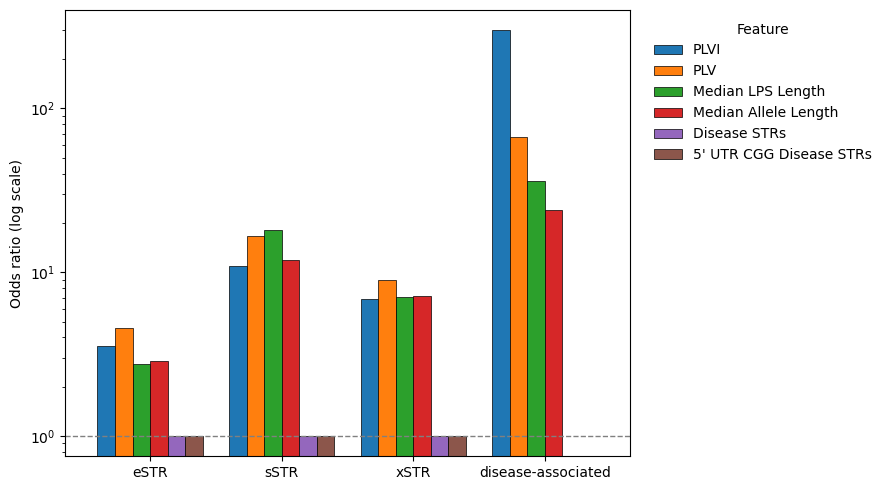

In [9]:
import matplotlib.pyplot as plt
# split "PLVI vs eSTR" into feature / category
results[["feature", "category"]] = results["condition"].str.split(" vs ", expand=True)
results["feature"] = results["feature"].replace({"medianLPSLen": "Median LPS Length"})
results["feature"] = results["feature"].replace({"medianTotalLen": "Median Allele Length"})
results["feature"] = results["feature"].replace({"diseaseSTRs": "Disease STRs"})
results["feature"] = results["feature"].replace({"diseaseUTRCGGs": "5' UTR CGG Disease STRs"})
results["category"] = results["category"].replace({"patho": "disease-associated"})
# use the term 'sSTR' instead of 'sTR' and 'xSTR' instead of 'xTR'
results["category"] = results["category"].replace({"sTR": "sSTR"})
results["category"] = results["category"].replace({"xTR": "xSTR"})
 
categories = ["eSTR", "sSTR", "xSTR", "disease-associated"]
features = ["PLVI", "PLV", "Median LPS Length", "Median Allele Length", "Disease STRs", "5' UTR CGG Disease STRs"]
 
# Rows = x-axis categories, columns = bar groups (colors)
pivot = (results.pivot(index="category", columns="feature", values="odds_ratio")
           .loc[categories, features])
 
ax = pivot.plot(kind="bar", figsize=(9, 5), width=0.8, edgecolor="black", linewidth=0.5)
ax.set_yscale("log")  # odds ratios range from ~2 to ~300
ax.axhline(1, color="grey", linestyle="--", linewidth=1)
ax.set_xlabel("")
ax.set_ylabel("Odds ratio (log scale)")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Feature", frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
 
plt.tight_layout()
plt.savefig('figures/SupplementaryFigure8C.png',dpi=600)
plt.savefig('figures/SupplementaryFigure8C.svg')
plt.show()
 

# S9: PLV / PLVI Consistency at Highly Polymorphic Loci

## S9A

In [1]:
import pandas as pd
discoveryPerMotif=pd.read_csv('statsTables/DiscoveryCohort_lpsPerMotifStats.TR_Explorer_1.0.1.txt.gz',sep='\t')
AFRPerMotif=pd.read_csv('statsTables/ValidationCohort_lpsPerMotifStats_AFR.TR_Explorer_1.0.1.txt.gz',sep='\t')
AMRPerMotif=pd.read_csv('statsTables/ValidationCohort_lpsPerMotifStats_AMR.TR_Explorer_1.0.1.txt.gz',sep='\t')
EURPerMotif=pd.read_csv('statsTables/ValidationCohort_lpsPerMotifStats_EUR.TR_Explorer_1.0.1.txt.gz',sep='\t')
EASPerMotif=pd.read_csv('statsTables/ValidationCohort_lpsPerMotifStats_EAS.TR_Explorer_1.0.1.txt.gz',sep='\t')
SASPerMotif=pd.read_csv('statsTables/ValidationCohort_lpsPerMotifStats_SAS.TR_Explorer_1.0.1.txt.gz',sep='\t')

discovery=pd.read_csv('statsTables/DiscoveryCohort_lpsPerLocusStats.TR_Explorer_1.0.1.txt.gz',sep='\t')
AFR=pd.read_csv('statsTables/ValidationCohort_lpsPerLocusStats_AFR.TR_Explorer_1.0.1.txt.gz',sep='\t')
AMR=pd.read_csv('statsTables/ValidationCohort_lpsPerLocusStats_AMR.TR_Explorer_1.0.1.txt.gz',sep='\t')
EUR=pd.read_csv('statsTables/ValidationCohort_lpsPerLocusStats_EUR.TR_Explorer_1.0.1.txt.gz',sep='\t')
EAS=pd.read_csv('statsTables/ValidationCohort_lpsPerLocusStats_EAS.TR_Explorer_1.0.1.txt.gz',sep='\t')
SAS=pd.read_csv('statsTables/ValidationCohort_lpsPerLocusStats_SAS.TR_Explorer_1.0.1.txt.gz',sep='\t')

# drop to the most common LPS motif per locus
discoveryPerMotif=discoveryPerMotif.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)
AFRPerMotif=AFRPerMotif.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)
AMRPerMotif=AMRPerMotif.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)
EURPerMotif=EURPerMotif.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)
EASPerMotif=EASPerMotif.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)
SASPerMotif=SASPerMotif.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)

# function to convert motifs to their simplest rotational form with reverse complements
def complement(seq):
    complement = {'A': 'T', 'C': 'G', 'G': 'C', 'T': 'A'} 
    bases = list(seq) 
    bases = [complement[base] for base in bases] 
    return ''.join(bases)
def reverse_complement(seq):
    return complement(seq[::-1])
def simplest_motif(motif):
    i = (motif+motif).find(motif, 1, -1)
    if i != -1:
        motif = motif[:i]
    motifs = []
    b = len(motif)
    for i in range(b):
        c = motif[i:]+motif[:i]
        motifs.append(c)
    motifs = [x.upper() for x in motifs]
    # repeat with reverse complement
    motifRC=reverse_complement(motif.upper())
    i = (motifRC+motifRC).find(motifRC, 1, -1)
    if i != -1:
        motifRC = motifRC[:i]
    b = len(motifRC)
    for i in range(b):
        c = motifRC[i:]+motifRC[:i]
        motifs.append(c)    
    return(min(motifs))

# apply the simplest_motif function the data
discoveryPerMotif['simpleMotif']=discoveryPerMotif.loc[:,'LPS_Motif'].apply(simplest_motif)
AFRPerMotif['simpleMotif']=AFRPerMotif.loc[:,'LPS_Motif'].apply(simplest_motif)
AMRPerMotif['simpleMotif']=AMRPerMotif.loc[:,'LPS_Motif'].apply(simplest_motif)
EURPerMotif['simpleMotif']=EURPerMotif.loc[:,'LPS_Motif'].apply(simplest_motif)
EASPerMotif['simpleMotif']=EASPerMotif.loc[:,'LPS_Motif'].apply(simplest_motif)
SASPerMotif['simpleMotif']=SASPerMotif.loc[:,'LPS_Motif'].apply(simplest_motif)
# calculate percentile of standard deviation within each motif length
discoveryPerMotif['motifLen']=discoveryPerMotif.loc[:,'simpleMotif'].str.len()
AFRPerMotif['motifLen']=AFRPerMotif.loc[:,'simpleMotif'].str.len()
AMRPerMotif['motifLen']=AMRPerMotif.loc[:,'simpleMotif'].str.len()
EURPerMotif['motifLen']=EURPerMotif.loc[:,'simpleMotif'].str.len()
EASPerMotif['motifLen']=EASPerMotif.loc[:,'simpleMotif'].str.len()
SASPerMotif['motifLen']=SASPerMotif.loc[:,'simpleMotif'].str.len()

discovery=discovery.merge(discoveryPerMotif.loc[:,['TRID','motifLen']],how='inner',on='TRID')
AFR=AFR.merge(AFRPerMotif.loc[:,['TRID','motifLen']],how='inner',on='TRID')
AMR=AMR.merge(AMRPerMotif.loc[:,['TRID','motifLen']],how='inner',on='TRID')
EUR=EUR.merge(EURPerMotif.loc[:,['TRID','motifLen']],how='inner',on='TRID')
EAS=EAS.merge(EASPerMotif.loc[:,['TRID','motifLen']],how='inner',on='TRID')
SAS=SAS.merge(SASPerMotif.loc[:,['TRID','motifLen']],how='inner',on='TRID')

discovery['PLVI']=discovery.groupby('motifLen',observed=True)['std'].rank(pct=True)
AFR['PLVI']=AFR.groupby('motifLen',observed=True)['std'].rank(pct=True)
AMR['PLVI']=AMR.groupby('motifLen',observed=True)['std'].rank(pct=True)
EUR['PLVI']=EUR.groupby('motifLen',observed=True)['std'].rank(pct=True)
EAS['PLVI']=EAS.groupby('motifLen',observed=True)['std'].rank(pct=True)
SAS['PLVI']=SAS.groupby('motifLen',observed=True)['std'].rank(pct=True)

In [2]:
AFR['discovery_0.9']=0
AFR['discovery_0.95']=0
AFR['discovery_0.99']=0
AFR['discovery_0.999']=0
AFR.loc[AFR['TRID'].isin(discovery.loc[discovery['PLVI']>0.9,'TRID'].values),'discovery_0.9']=1
AFR.loc[AFR['TRID'].isin(discovery.loc[discovery['PLVI']>0.95,'TRID'].values),'discovery_0.95']=1
AFR.loc[AFR['TRID'].isin(discovery.loc[discovery['PLVI']>0.99,'TRID'].values),'discovery_0.99']=1
AFR.loc[AFR['TRID'].isin(discovery.loc[discovery['PLVI']>0.999,'TRID'].values),'discovery_0.999']=1

AMR['discovery_0.9']=0
AMR['discovery_0.95']=0
AMR['discovery_0.99']=0
AMR['discovery_0.999']=0
AMR.loc[AMR['TRID'].isin(discovery.loc[discovery['PLVI']>0.9,'TRID'].values),'discovery_0.9']=1
AMR.loc[AMR['TRID'].isin(discovery.loc[discovery['PLVI']>0.95,'TRID'].values),'discovery_0.95']=1
AMR.loc[AMR['TRID'].isin(discovery.loc[discovery['PLVI']>0.99,'TRID'].values),'discovery_0.99']=1
AMR.loc[AMR['TRID'].isin(discovery.loc[discovery['PLVI']>0.999,'TRID'].values),'discovery_0.999']=1

EUR['discovery_0.9']=0
EUR['discovery_0.95']=0
EUR['discovery_0.99']=0
EUR['discovery_0.999']=0
EUR.loc[EUR['TRID'].isin(discovery.loc[discovery['PLVI']>0.9,'TRID'].values),'discovery_0.9']=1
EUR.loc[EUR['TRID'].isin(discovery.loc[discovery['PLVI']>0.95,'TRID'].values),'discovery_0.95']=1
EUR.loc[EUR['TRID'].isin(discovery.loc[discovery['PLVI']>0.99,'TRID'].values),'discovery_0.99']=1
EUR.loc[EUR['TRID'].isin(discovery.loc[discovery['PLVI']>0.999,'TRID'].values),'discovery_0.999']=1

EAS['discovery_0.9']=0
EAS['discovery_0.95']=0
EAS['discovery_0.99']=0
EAS['discovery_0.999']=0
EAS.loc[EAS['TRID'].isin(discovery.loc[discovery['PLVI']>0.9,'TRID'].values),'discovery_0.9']=1
EAS.loc[EAS['TRID'].isin(discovery.loc[discovery['PLVI']>0.95,'TRID'].values),'discovery_0.95']=1
EAS.loc[EAS['TRID'].isin(discovery.loc[discovery['PLVI']>0.99,'TRID'].values),'discovery_0.99']=1
EAS.loc[EAS['TRID'].isin(discovery.loc[discovery['PLVI']>0.999,'TRID'].values),'discovery_0.999']=1

SAS['discovery_0.9']=0
SAS['discovery_0.95']=0
SAS['discovery_0.99']=0
SAS['discovery_0.999']=0
SAS.loc[SAS['TRID'].isin(discovery.loc[discovery['PLVI']>0.9,'TRID'].values),'discovery_0.9']=1
SAS.loc[SAS['TRID'].isin(discovery.loc[discovery['PLVI']>0.95,'TRID'].values),'discovery_0.95']=1
SAS.loc[SAS['TRID'].isin(discovery.loc[discovery['PLVI']>0.99,'TRID'].values),'discovery_0.99']=1
SAS.loc[SAS['TRID'].isin(discovery.loc[discovery['PLVI']>0.999,'TRID'].values),'discovery_0.999']=1


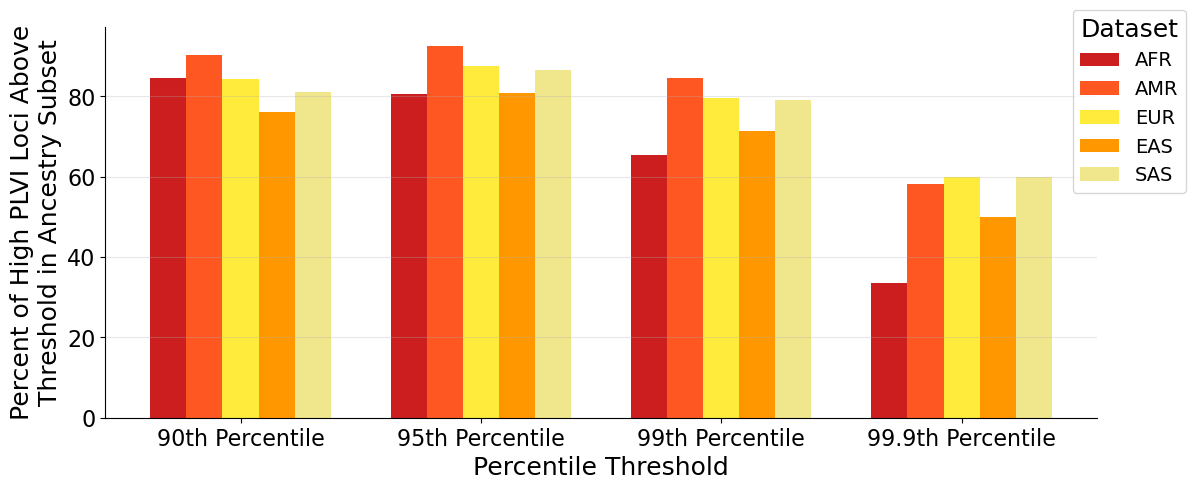

In [ ]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sb
import matplotlib
from matplotlib.colors import to_rgba
from statsmodels.stats.contingency_tables import Table2x2

mpl.rcParams['svg.fonttype'] = 'none'  # keep SVG text in SVGs

def calculate_enrichment_with_ci(df, percentile_threshold, pathogenic_col='discovery_0.9', threshold_col='PLVI'):
    above_threshold = df[threshold_col] > percentile_threshold
    
    a = ((df[pathogenic_col] == 1) & above_threshold).sum()
    b = ((df[pathogenic_col] == 0) & above_threshold).sum()
    c = ((df[pathogenic_col] == 1) & ~above_threshold).sum()
    d = ((df[pathogenic_col] == 0) & ~above_threshold).sum()
    
    table = Table2x2([[a, b], [c, d]])
    
    return {
        'odds_ratio': table.oddsratio,
        'p_value': table.oddsratio_pvalue(),
        'ci_95': table.oddsratio_confint(alpha=0.05),
        'contingency_table': [[a, b], [c, d]],
        'n_above': a,
        'n_total': a + c,
        'n_total_above': a + b
    }


# Collect n_pathogenic_above values for plotting
thresholds = [0.9, 0.95, 0.99, 0.999]
datasets = {
    'AFR': AFR,
    'AMR': AMR,
    'EUR': EUR,
    'EAS': EAS,
    'SAS': SAS
}

# Collect data for plotting
plot_data = []
for dataset_name, dataset in datasets.items():
    for threshold in thresholds:
        stats = calculate_enrichment_with_ci(dataset, threshold, pathogenic_col=f'discovery_{threshold}')
        plot_data.append({
            'Dataset': dataset_name,
            'Threshold': f'{threshold*100:.1f}th Percentile',
            'percent_above': 100*stats['n_above']/stats['n_total']
        })

# Convert to DataFrame for easier plotting
plot_df = pd.DataFrame(plot_data)

# Create grouped bar plot
anc_colors    = {
    'AFR': '#CC1E1E', 'AMR': '#FF5722', 'EAS': '#FF9800',
    'EUR': '#FFEB3B', 'SAS': '#F0E68C', 'MID': '0.6',
}

mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['svg.fonttype'] = 'none'
fig, ax = plt.subplots(figsize=(12, 5))

# Get unique thresholds and datasets
threshold_labels = [f'{t*100:.1f}th Percentile' for t in thresholds]
dataset_names = list(datasets.keys())

# Set up bar positions
x = np.arange(len(threshold_labels))
width = 0.15
offsets = np.linspace(-width*2, width*2, len(dataset_names))

# Plot bars for each dataset
for idx, dataset_name in enumerate(dataset_names):
    data_subset = plot_df[plot_df['Dataset'] == dataset_name]
    values = [data_subset[data_subset['Threshold'] == tl]['percent_above'].values[0] 
              for tl in threshold_labels]
    ax.bar(x + offsets[idx], values, width, label=dataset_name, color=anc_colors[dataset_name])

# Customize plot
ax.set_xlabel('Percentile Threshold', fontsize=18)
ax.set_ylabel('Percent of High PLVI Loci Above\nThreshold in Ancestry Subset', fontsize=18)
#ax.set_title('Pathogenic TR Enrichment by Threshold and Dataset', fontsize=18, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(['90th Percentile','95th Percentile','99th Percentile','99.9th Percentile'],fontsize=16)
plt.yticks(fontsize=16)
ax.legend(title='Dataset', bbox_to_anchor=(1.1, 1.07), loc='upper right',fontsize=14,title_fontsize=18)
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('figures/SupplementaryFigure9A.svg')
plt.savefig('figures/SupplementaryFigure9A.png',dpi=600)

## S9B

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats

def pairwise_correlation_heatmap(
    df,
    columns,
    ax=None,
    cmap="viridis",
    annot=True,
    cbar_label="Count",
    figsize=(8, 6),
):
    """
    Heatmap of pairwise overlap counts between columns of `df`.
    """
    n = len(columns)
    n_rows=len(df)
    result = np.zeros((n, n), dtype=float)

    for i, col_i in enumerate(columns):
        for j, col_j in enumerate(columns):
            result[i, j], _ = scipy.stats.pearsonr(df.loc[:,col_i].astype(float).values,df.loc[:,col_j].astype(float).values)

    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure

    im = ax.imshow(result, cmap=cmap)
    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_xticklabels(columns, rotation=45, ha="right")
    ax.set_yticklabels(columns)

    if annot:
        thresh = result.max() / 2 if result.max() else 0
        for i in range(n):
            for j in range(n):
                ax.text(
                    j, i, np.round(result[i, j],3),
                    ha="center", va="center",
                    color="white" if result[i, j] < thresh else "black",
                )

    fig.colorbar(im, ax=ax, label=cbar_label)
    fig.tight_layout()
    return fig, ax, result

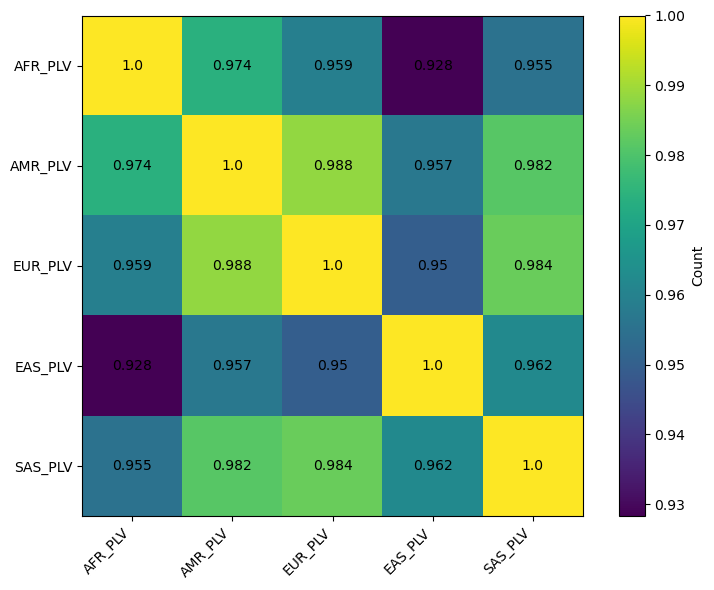

In [ ]:
combined=AFR.loc[:,['TRID','std','PLVI','discovery_0.99']].rename(columns={'PLVI':'AFR_PLVI','std':'AFR_PLV'}).merge(
    AMR.loc[:,['TRID','std','PLVI']].rename(columns={'PLVI':'AMR_PLVI','std':'AMR_PLV'}),how='inner',on='TRID')
combined=combined.merge(EUR.loc[:,['TRID','std','PLVI']].rename(columns={'PLVI':'EUR_PLVI','std':'EUR_PLV'}),how='inner',on='TRID')
combined=combined.merge(EAS.loc[:,['TRID','std','PLVI']].rename(columns={'PLVI':'EAS_PLVI','std':'EAS_PLV'}),how='inner',on='TRID')
combined=combined.merge(SAS.loc[:,['TRID','std','PLVI']].rename(columns={'PLVI':'SAS_PLVI','std':'SAS_PLV'}),how='inner',on='TRID')

combined2=combined.loc[combined['discovery_0.99']==1,:].dropna()
fig, ax, counts = pairwise_correlation_heatmap(combined2, ["AFR_PLV", "AMR_PLV", "EUR_PLV", "EAS_PLV", "SAS_PLV"])
plt.savefig('figures/SupplementaryFigure9B.svg')
plt.savefig('figures/SupplementaryFigure9B.png',dpi=600)

# S10: PLVI Downsampling analysis

In [2]:
import pandas
lpsPerMotif=pandas.read_csv('statsTables/DiscoveryCohort_lpsPerMotifStats.TR_Explorer_1.0.1.txt.gz',sep='\t')
lpsPerLocus=pandas.read_csv('statsTables/DiscoveryCohort_lpsPerLocusStats.TR_Explorer_1.0.1.txt.gz',sep='\t')
alleleLength=pandas.read_csv('statsTables/DiscoveryCohort_alleleLengthStats.TR_Explorer_1.0.1.txt.gz',sep='\t')
def complement(seq):
    complement = {'A': 'T', 'C': 'G', 'G': 'C', 'T': 'A'} 
    bases = list(seq) 
    bases = [complement[base] for base in bases] 
    return ''.join(bases)
def reverse_complement(seq):
    return complement(seq[::-1])
def simplest_motif(motif):
    i = (motif+motif).find(motif, 1, -1)
    if i != -1:
        motif = motif[:i]
    motifs = []
    b = len(motif)
    for i in range(b):
        c = motif[i:]+motif[:i]
        motifs.append(c)
    motifs = [x.upper() for x in motifs]
    # repeat with reverse complement
    motifRC=reverse_complement(motif.upper())
    i = (motifRC+motifRC).find(motifRC, 1, -1)
    if i != -1:
        motifRC = motifRC[:i]
    b = len(motifRC)
    for i in range(b):
        c = motifRC[i:]+motifRC[:i]
        motifs.append(c)    
    return(min(motifs))


# drop to the most common LPS motif per locus
lpsPerMotif=lpsPerMotif.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)
lpsPerMotif['simpleMotif']=lpsPerMotif.loc[:,'LPS_Motif'].apply(simplest_motif)
lpsPerMotif['motifLen']=lpsPerMotif.loc[:,'simpleMotif'].str.len()

# merge motifLen onto lpsPerLocus
lpsPerLocus=lpsPerLocus.merge(lpsPerMotif.loc[:,['TRID','motifLen']],how='inner',on='TRID')

# calculate the PLVI score
lpsPerLocus['PLVI']=lpsPerLocus.groupby('motifLen',observed=True)['std'].rank(pct=True)

# calculate the PLVI equivalent for allele length
alleleLength[['chr','start','end','refMotif']]=alleleLength.loc[:,'TRID'].str.split(',',expand=True).iloc[:,0].str.split('-',expand=True)
alleleLength['motifLen']=alleleLength.loc[:,'refMotif'].str.len()
alleleLength['alleleLen_PLVI']=alleleLength.groupby('motifLen',observed=True)['std'].rank(pct=True)

combined=alleleLength.loc[:,['TRID','std','alleleLen_PLVI']].rename(columns={'std':'alleleLen_PLV'})
combined=combined.merge(lpsPerLocus.loc[:,['TRID','std','PLVI']].rename(columns={'std':'PLV'}),how='inner',on='TRID')



In [3]:
subsets=[20,40,60,80,100,120,140,160,180,200,220,240,260,280,300,320,340,360,380,400,420,440,460,480,500,520,540]
for subset in subsets:
    alleleLengthSubset=pandas.read_csv(f'statsTables/downsampling/alleleLengthStats_trgt.TR_Explorer_1.0.1_subset_n{subset}.txt.gz',sep='\t')
    alleleLengthSubset[['chr','start','end','refMotif']]=alleleLengthSubset.loc[:,'TRID'].str.split(',',expand=True).iloc[:,0].str.split('-',expand=True)
    alleleLengthSubset['motifLen']=alleleLengthSubset.loc[:,'refMotif'].str.len()
    alleleLengthSubset[f'alleleLen_PLVI_n{subset}']=alleleLengthSubset.groupby('motifLen',observed=True)['std'].rank(pct=True)
    
    lpsPerMotifSubset=pandas.read_csv(f'statsTables/downsampling/lpsPerMotifStats_trgt.TR_Explorer_1.0.1_subset_n{subset}.txt.gz',sep='\t')
    lpsPerMotifSubset=lpsPerMotifSubset.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)
    lpsPerMotifSubset['simpleMotif']=lpsPerMotifSubset.loc[:,'LPS_Motif'].apply(simplest_motif)
    lpsPerMotifSubset['motifLen']=lpsPerMotifSubset.loc[:,'simpleMotif'].str.len()

    lpsPerLocusSubset=pandas.read_csv(f'statsTables/downsampling/lpsPerLocusStats_trgt.TR_Explorer_1.0.1_subset_n{subset}.txt.gz',sep='\t')
    lpsPerLocusSubset=lpsPerLocusSubset.merge(lpsPerMotifSubset.loc[:,['TRID','motifLen']],how='inner',on='TRID')
    lpsPerLocusSubset[f'PLVI_n{subset}']=lpsPerLocusSubset.groupby('motifLen',observed=True)['std'].rank(pct=True)
    
    combined=combined.merge(alleleLengthSubset.loc[:,['TRID','std',f'alleleLen_PLVI_n{subset}']]).rename(columns={'std':f'alleleLen_PLV_n{subset}'})
    combined=combined.merge(lpsPerLocusSubset.loc[:,['TRID','std',f'PLVI_n{subset}']].rename(columns={'std':f'PLV_n{subset}'}),how='inner',on='TRID')
combined


,TRID,alleleLen_PLV,alleleLen_PLVI,PLV,PLVI,alleleLen_PLV_n20,alleleLen_PLVI_n20,PLV_n20,PLVI_n20,alleleLen_PLV_n40,...,PLV_n500,PLVI_n500,alleleLen_PLV_n520,alleleLen_PLVI_n520,PLV_n520,PLVI_n520,alleleLen_PLV_n540,alleleLen_PLVI_n540,PLV_n540,PLVI_n540
0,1-201446998-201447021-ATAA,1.548801,0.818775,0.500569,0.744116,0.000000,0.361115,0.000000,0.377766,0.000000,...,0.521659,0.747540,1.582644,0.821144,0.511524,0.746024,1.553092,0.818997,0.501958,0.744258
1,1-115153082-115153091-TCA,0.000000,0.417753,0.315062,0.904210,0.000000,0.461229,0.948683,0.954383,0.000000,...,0.328304,0.906052,0.000000,0.418615,0.321941,0.904726,0.000000,0.417835,0.315935,0.904119
2,1-207587736-207587750-AAC,0.000000,0.417753,0.000000,0.390633,0.000000,0.461229,0.000000,0.460843,0.000000,...,0.000000,0.393453,0.000000,0.418615,0.000000,0.392069,0.000000,0.417835,0.000000,0.390784
3,1-28585934-28585946-A,8.923238,0.977105,1.448085,0.893274,0.357161,0.557640,1.274755,0.883025,0.297404,...,1.453860,0.893674,9.118438,0.978056,1.452323,0.893570,8.947990,0.977190,1.451441,0.893545
4,1-235666607-235666635-AC,3.974667,0.885830,3.974667,0.924206,3.848410,0.899022,3.848410,0.925351,4.062097,...,3.997757,0.924598,4.006804,0.886799,4.006804,0.924952,3.975098,0.885825,3.975098,0.924192
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4439577,Y-12513391-12513403-ATAA,0.000000,0.269124,0.000000,0.267682,0.000000,0.361115,0.000000,0.377766,0.000000,...,0.000000,0.271392,0.000000,0.270573,0.000000,0.269579,0.000000,0.269261,0.000000,0.267888
4439578,Y-15793356-15793366-T,0.125878,0.345955,0.125878,0.322953,0.000000,0.181046,0.000000,0.175428,0.000000,...,0.130067,0.327090,0.127921,0.349327,0.127921,0.326465,0.126548,0.346312,0.126548,0.323317
4439579,Y-5697431-5697444-AAAT,0.000000,0.269124,0.000000,0.267682,0.000000,0.361115,0.000000,0.377766,0.000000,...,0.000000,0.271392,0.000000,0.270573,0.000000,0.269579,0.000000,0.269261,0.000000,0.267888
4439580,Y-7164419-7164432-CTC,0.000000,0.417753,0.000000,0.390633,0.000000,0.461229,0.000000,0.460843,0.000000,...,0.000000,0.393453,0.000000,0.418615,0.000000,0.392069,0.000000,0.417835,0.000000,0.390784


In [4]:
# calculate correlations
import scipy.stats
scorecard=pandas.DataFrame(columns=['subset','alleleLen_PLV','alleleLen_PLVI','PLV','PLVI'],index=range(len(subsets)))
scorecard['subset']=subsets
combined=combined.dropna()
for i, subset in enumerate(subsets):
    scorecard.loc[i,'alleleLen_PLV'],_=scipy.stats.pearsonr(combined.loc[:,f'alleleLen_PLV_n{subset}'].values,combined.loc[:,'alleleLen_PLV'].values)
    scorecard.loc[i,'alleleLen_PLVI'],_=scipy.stats.pearsonr(combined.loc[:,f'alleleLen_PLVI_n{subset}'].values,combined.loc[:,'alleleLen_PLVI'].values)
    scorecard.loc[i,'PLV'],_=scipy.stats.pearsonr(combined.loc[:,f'PLV_n{subset}'].values,combined.loc[:,'PLV'].values)
    scorecard.loc[i,'PLVI'],_=scipy.stats.pearsonr(combined.loc[:,f'PLVI_n{subset}'].values,combined.loc[:,'PLVI'].values)
scorecard

,subset,alleleLen_PLV,alleleLen_PLVI,PLV,PLVI
0,20,0.863447,0.85345,0.974893,0.840848
1,40,0.888957,0.883268,0.983416,0.873968
2,60,0.90564,0.899584,0.986755,0.892273
3,80,0.915409,0.909634,0.988712,0.903929
4,100,0.922772,0.919006,0.99027,0.914704
5,120,0.929119,0.926023,0.991252,0.9222
6,140,0.93435,0.932138,0.99199,0.928611
7,160,0.939246,0.937311,0.992787,0.934639
8,180,0.943218,0.941814,0.993367,0.939845
9,200,0.947208,0.946742,0.993847,0.945447


In [5]:
scorecard.to_csv('assets/PLVI_downsampling_consistency_metrics.txt',sep='\t',index=False)

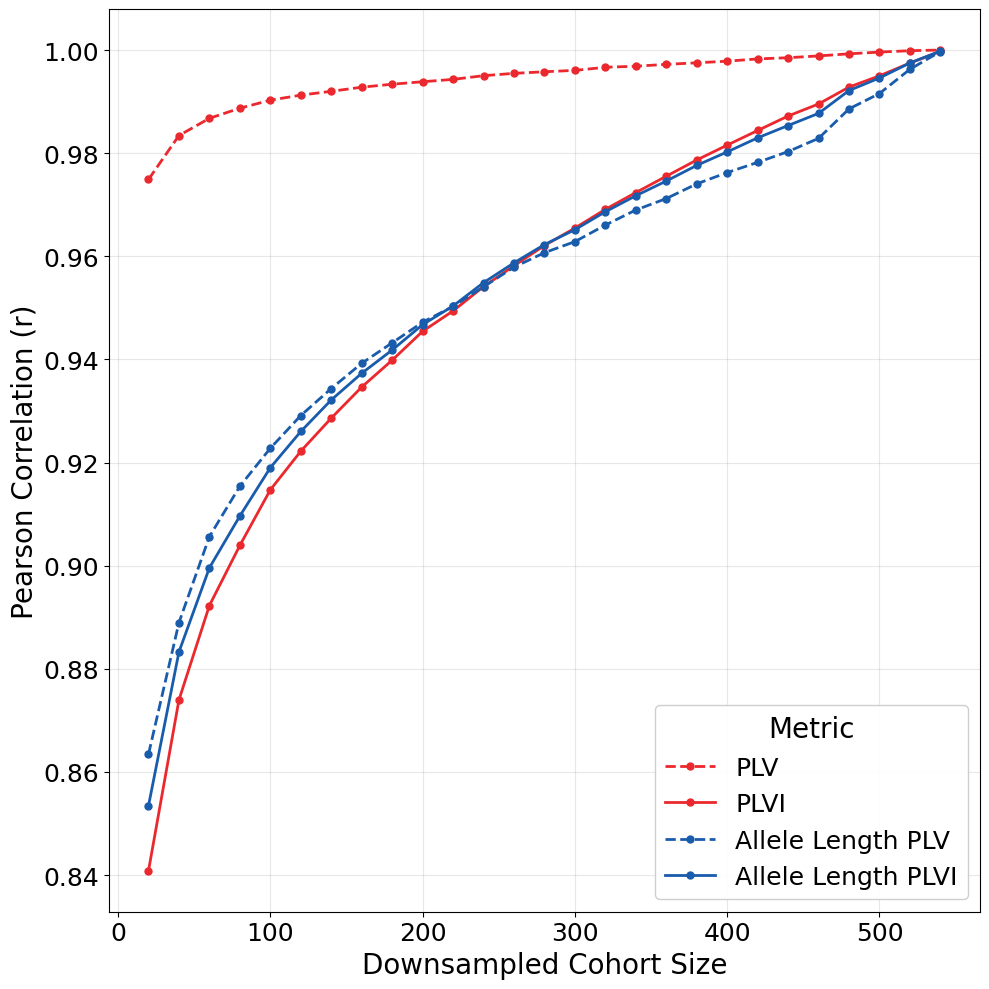

In [ ]:
# plot results
import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['svg.fonttype'] = 'none'

scorecard=pd.read_csv('assets/PLVI_downsampling_consistency_metrics.txt',sep='\t')

fig, ax1 = plt.subplots(1, 1, figsize=(10, 10))

# Get colors matching the existing plot style
dataset_colors={
    'PLV': '#EB282D',
    'PLVI': '#EB282D',
    'alleleLen_PLV': '#195CAC',
    'alleleLen_PLVI': '#195CAC'}

dataset_linestyles={
    'PLV': '--',
    'PLVI': '-',
    'alleleLen_PLV': '--',
    'alleleLen_PLVI': '-'}

dataset_labels={
    'PLV': 'PLV',
    'PLVI': 'PLVI',
    'alleleLen_PLV': 'Allele Length PLV',
    'alleleLen_PLVI': 'Allele Length PLVI'}

# Plot Pearson correlations on main panel
for idx, dataset_name in enumerate(dataset_colors.keys()):
    ax1.plot(scorecard.loc[:,'subset'].values, scorecard.loc[:,dataset_name].values,
             marker='o', label=dataset_labels[dataset_name], color=dataset_colors[dataset_name], linewidth=2, markersize=5,
             linestyle=dataset_linestyles[dataset_name])

ax1.set_xlabel('Downsampled Cohort Size', fontsize=20)
ax1.set_ylabel('Pearson Correlation (r)', fontsize=20)
ax1.tick_params(labelsize=18)
#ax1.set_title('Allele Length Percentile Correlation vs High Coverage Reference', fontsize=14, fontweight='bold')
ax1.grid(axis='both', alpha=0.3)

# Position legend in bottom left with padding
ax1.legend(title='Metric', loc='lower right', fontsize=18, framealpha=0.95,title_fontsize=20)

plt.tight_layout()
plt.savefig('figures/SupplementaryFigure10A.svg')
plt.savefig('figures/SupplementaryFigure10A.png',dpi=600)

# S11: Supplementary Linkage Region Plots

C:\Users\Matt\AppData\Local\Temp\ipykernel_67600\333033439.py:122: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  result_df = pd.concat([result_df, new_row], ignore_index=True)


HTT: Rank 6/4232, Value: 0.9988
C9orf72: Rank 44/17497, Value: 0.9975
THAP11: Rank 283/14334, Value: 0.9803
ZFHX3: Rank 234/14334, Value: 0.9837
FGF14: Rank 1/2139, Value: 1.0000
ATXN10: Rank 3/5591, Value: 0.9996
THAP11: Rank 225/11683, Value: 0.9808
BEAN1: Rank 1/11683, Value: 1.0000
DAB1: Rank 2/3334, Value: 0.9997
FXN: Rank 4/4742, Value: 0.9994
STARD7: Rank 18/25124, Value: 0.9993
AFF3: Rank 11/25124, Value: 0.9996
MARCHF6: Rank 9/13650, Value: 0.9994
ABCD3: Rank 271/61228, Value: 0.9956
NOTCH2NLC: Rank 32/61228, Value: 0.9995
CNBP: Rank 81/14233, Value: 0.9944


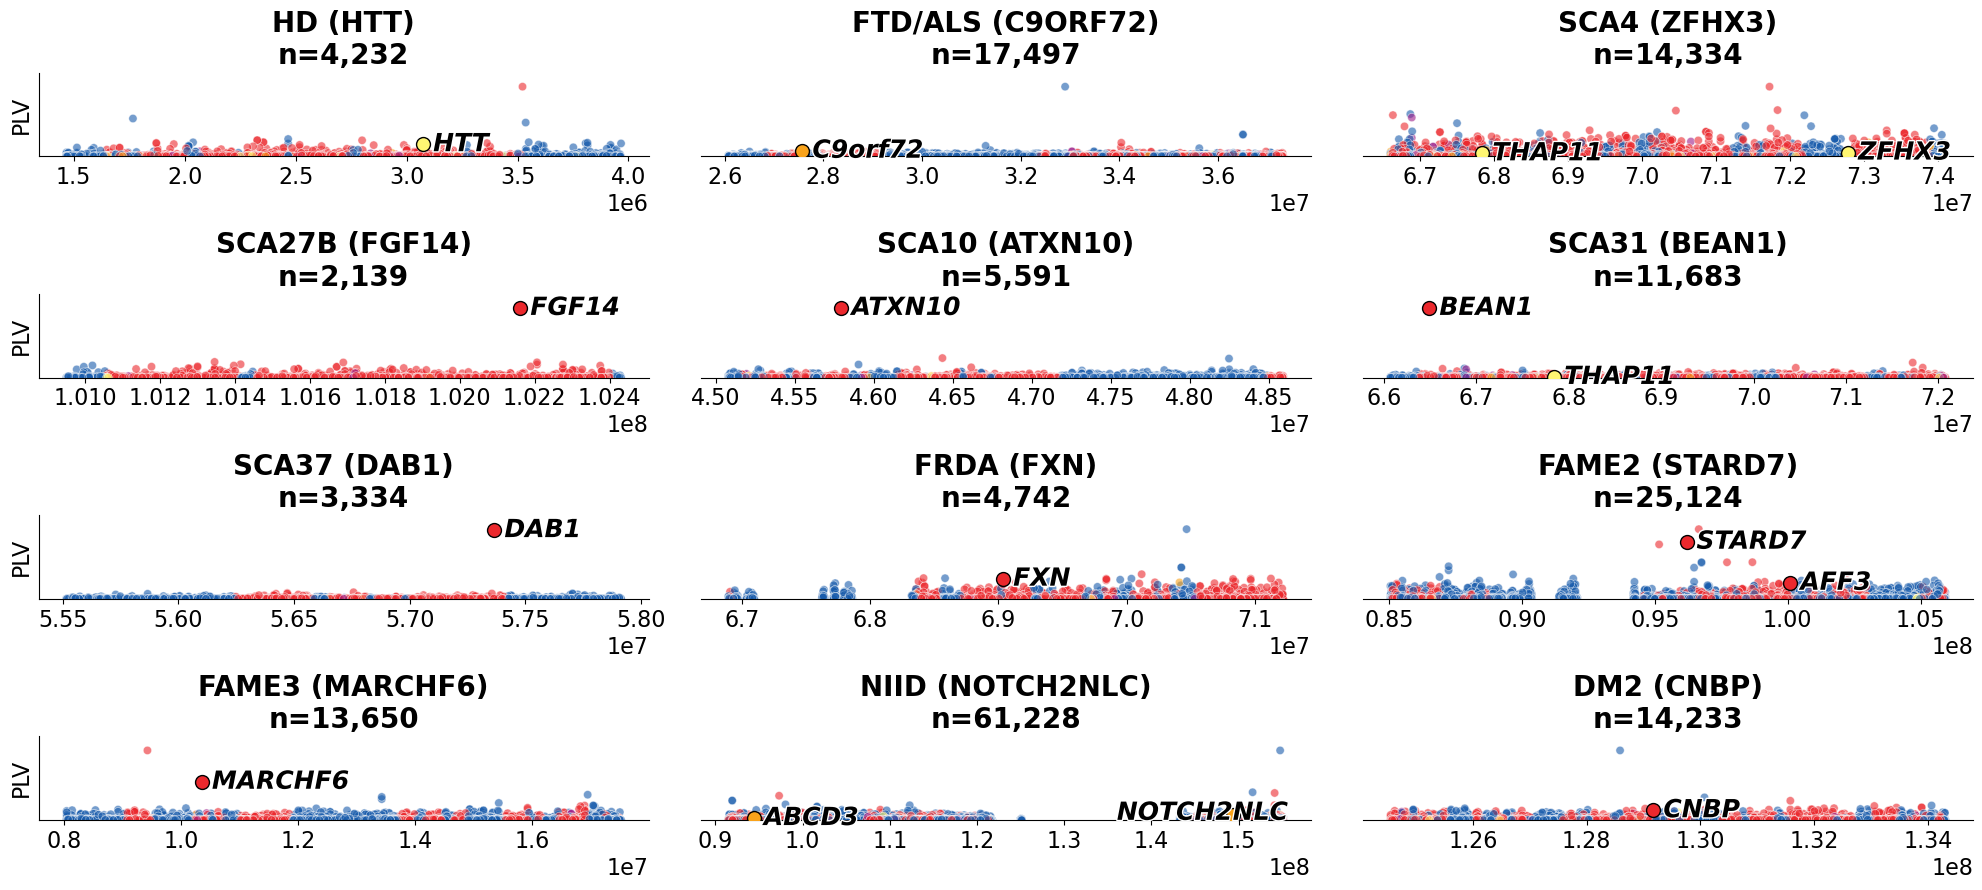

In [ ]:

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sb
import matplotlib.patheffects as pe

mpl.rcParams['svg.fonttype'] = 'none'  # keep SVG text in SVGs

df=pd.read_csv('statsTables/DiscoveryCohort_lpsPerLocusStats.TR_Explorer_1.0.1_withPLVI.txt.gz', sep="\t")

genicAnnotations=pd.read_csv('assets/genicRegionAnnotations_TRExplorer.txt.gz',sep='\t',header=None,names=['TRID','region'])
df=df.merge(genicAnnotations,how='left',on='TRID')
df.loc[df['region'].isna(),'region']='intergenic'

# drop to just the STRs
df=df.loc[df['motifLen']<=6,:].reset_index(drop=True)

# Define pathogenic TRIDs
pathogenic=pd.read_csv('assets/pathogenicTRIDs_TRExplorer_v1.0.1_STRchiveFiltered_noVNTRs_withAnno.txt',sep='\t')
df=df.merge(pathogenic.loc[:,['TRID','geneName']],how='left',on='TRID').rename(columns={'geneName':'gene'})
df['Status'] = 'Catalog'
df.loc[~(df['gene'].isna()), 'Status'] = 'Pathogenic'

# Panel definitions (phenotype regions)
regions = [
    'HD chr4_1467045_3967045', 'FTD/ALS chr9_26071033_37322562',
    'SCA4 chr16_66600001_74100000', 'SCA27B chr13_100949908_102431199',
    'SCA10 chr22_45079539_48590066', 'SCA31 chr16_66067491_72076730', 
    'SCA37 chr1_55515300_57914975', 'FRDA chr9_66891164_71223663',
    'FAME2 chr2_85059961_105930167', 'FAME3 chr5_8040420_17547546', 
    'NIID chr1_91500001_155100000', 'DM2 chr3_124549644_134304744'
]

regionsLabels = [
    'HD (HTT)\nn=4,232', 'FTD/ALS (C9ORF72)\nn=17,497', 
    'SCA4 (ZFHX3)\nn=14,334', 'SCA27B (FGF14)\nn=2,139', 'SCA10 (ATXN10)\nn=5,591', 'SCA31 (BEAN1)\nn=11,683',
    'SCA37 (DAB1)\nn=3,334', 'FRDA (FXN)\nn=4,742', 'FAME2 (STARD7)\nn=25,124',
    'FAME3 (MARCHF6)\nn=13,650', 'NIID (NOTCH2NLC)\nn=61,228', 'DM2 (CNBP)\nn=14,233'
]

# Category → color mapping
regs = ['intron', 'intergenic', 'UTR_3', 'UTR_5', 'coding']
cols = ['#EB282D', '#195CAC', '#9D1E89', '#F9A31B', '#FFF672']
cm = dict(zip(regs, cols))

# Container for per-panel results (rank/percentile summaries)
result_df = pd.DataFrame(columns=['regionSize','pheno','gene','motif','rank','nTRs','percentile'])

# Plot grid (4 rows × 3 cols = 12 panels)
fig, axs = plt.subplots(nrows=4, ncols=3, figsize=(20, 9))
axs = np.atleast_2d(axs)

### Panel loop
for idx, region in enumerate(regions):
    row = idx // 3
    col = idx % 3

    pheno, coords = region.split(' ')
    chrom, start, end = coords.split('_')
    chrom=chrom[3:]
    start = int(start); end = int(end)
    length = end - start
    lab = regionsLabels[idx]

    d = df[df['TRID'].str.startswith(chrom + '-')].copy()
    d[['chr', 'start', 'end','motif']] = d['TRID'].str.split(',', expand=True).iloc[:,0].str.split('-',expand=True)
    d['start'] = d['start'].astype(int)
    d['end'] = d['end'].astype(int)
    d = d[(d['start'] > start) & (d['end'] < end)].copy()

    d = d[d['PLVI'].notna()].copy()
    d = d.sample(frac=1, random_state=7)  # shuffle to avoid patterning

    # region-specific tweak (kept from original): reclassify some exon calls in SCA4
    if region == 'SCA4 chr16_66600001_74100000':
        mask_non3 = (d['region'] == 'coding') & (d['motifLen'] % 3 != 0)
        d.loc[mask_non3, 'region'] = 'intron'

    # scatter
    ax = axs[row, col]
    sb.scatterplot(
        x=d['start'], y=d['std'], hue=d['region'], palette=cm,
        ax=ax, marker='o', alpha=0.6, rasterized=True, legend=False
    )

    # Only show y-axis for the leftmost subplot (col == 0)
    if col == 0:
        ax.set_ylabel('PLV', fontsize=16)
        ax.set_yticks([])
    else:
        ax.set_yticks([])
        ax.set_ylabel('')
        ax.spines['left'].set_visible(False)

    if len(d) and d['std'].max() > 0:
        ax.set_ylim(0, d['std'].max() * 1.2)
    ax.set_xlabel('')
    ax.tick_params(labelsize=16)
    ax.xaxis.get_offset_text().set_fontsize(16)
    ax.set_title(lab, fontsize=20, fontweight='bold')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    total_TRs = len(d)
    if total_TRs:
        d = d.sort_values('PLVI', ascending=True).copy()
        d['Stdev_rank'] = d['PLVI'].rank(ascending=False)

        # annotate pathogenic points and collect ranks
        for _, point in d.iterrows():
            if point.get('Status') == 'Pathogenic':
                percentile_value = 1 - ((point['Stdev_rank'] - 1) / total_TRs)
                new_row = pd.DataFrame({
                    'regionSize': [length],
                    'pheno': [pheno],
                    'gene': [point['gene']],
                    'rank': [int(point['Stdev_rank'])],
                    'nTRs': [total_TRs],
                    'percentile': [percentile_value]
                })
                result_df = pd.concat([result_df, new_row], ignore_index=True)
                print(f"{point['gene']}: Rank {int(point['Stdev_rank'])}/{total_TRs}, Value: {percentile_value:.4f}")

                ax.scatter(point['start'], point['std'],
                           marker='o', color=cm.get(point['region'], 'red'),
                           edgecolors='black', s=100, zorder=3)

                if point['gene'] != 'NOTCH2NLC':
                    ax.annotate(
                        f"{point['gene']}",
                        (point['start'] + (length * 0.018), point['std']),
                        fontsize=18,
                        path_effects=[pe.withStroke(linewidth=2, foreground='white')],
                        color='black', fontstyle='italic', fontweight='bold',
                        ha='left', va='center'
                    )
                else:
                    ax.annotate(
                        f"{point['gene']}",
                        (point['start'] - (length * 0.21), point['std'] + 4),
                        fontsize=18,
                        path_effects=[pe.withStroke(linewidth=2, foreground='white')],
                        color='black', fontstyle='italic', fontweight='bold',
                        ha='left', va='center'
                    )
plt.tight_layout()
plt.savefig('figures/SupplementaryFigure11.svg')
plt.savefig('figures/SupplementaryFigure11.png',dpi=600)

# S12: Outliers per Sample

## S12A

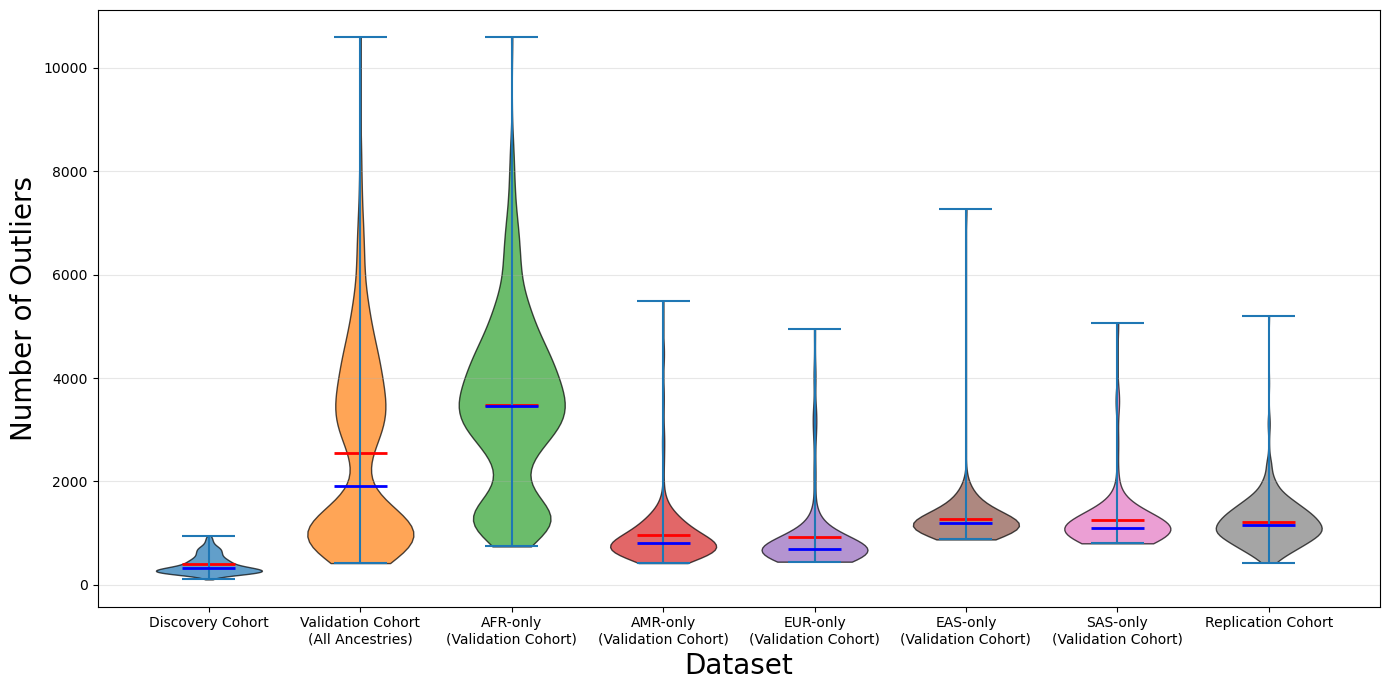


=== Summary Statistics for 99.9th Percentile Outliers ===

Discovery Cohort:
  Mean: 395.69
  Median: 334.00
  Std Dev: 178.73
  Min: 106.00
  Max: 950.00
  N samples: 543

Validation Cohort
(All Ancestries):
  Mean: 2553.76
  Median: 1919.00
  Std Dev: 1820.62
  Min: 422.00
  Max: 10596.00
  N samples: 2128

AFR-only
(Validation Cohort):
  Mean: 3472.39
  Median: 3464.00
  Std Dev: 1665.51
  Min: 744.00
  Max: 10596.00
  N samples: 1323

AMR-only
(Validation Cohort):
  Mean: 969.58
  Median: 801.50
  Std Dev: 639.81
  Min: 422.00
  Max: 5493.00
  N samples: 290

EUR-only
(Validation Cohort):
  Mean: 919.16
  Median: 689.50
  Std Dev: 746.37
  Min: 449.00
  Max: 4945.00
  N samples: 296

EAS-only
(Validation Cohort):
  Mean: 1274.82
  Median: 1188.00
  Std Dev: 585.39
  Min: 879.00
  Max: 7273.00
  N samples: 123

SAS-only
(Validation Cohort):
  Mean: 1252.38
  Median: 1102.50
  Std Dev: 645.29
  Min: 804.00
  Max: 5061.00
  N samples: 78

Replication Cohort:
  Mean: 1222.87
  Median:

In [ ]:
# initial data loading and package import
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sb
from matplotlib.colors import to_rgba

mpl.rcParams['svg.fonttype'] = 'none'  # keep SVG text in SVGs

highCovComplete=pd.read_csv('assets/outlierAnalyses/DiscoveryCohort_AlleleLengthOutliersPerSample.txt',sep='\t')
lowCovComplete=pd.read_csv('assets/outlierAnalyses/ValidationCohort_AlleleLengthOutliersPerSample.txt',sep='\t')
AFR=pd.read_csv('assets/outlierAnalyses/ValidationCohort_AlleleLengthOutliersPerSample_AFR.txt',sep='\t')
AMR=pd.read_csv('assets/outlierAnalyses/ValidationCohort_AlleleLengthOutliersPerSample_AMR.txt',sep='\t')
EUR=pd.read_csv('assets/outlierAnalyses/ValidationCohort_AlleleLengthOutliersPerSample_EUR.txt',sep='\t')
EAS=pd.read_csv('assets/outlierAnalyses/ValidationCohort_AlleleLengthOutliersPerSample_EAS.txt',sep='\t')
SAS=pd.read_csv('assets/outlierAnalyses/ValidationCohort_AlleleLengthOutliersPerSample_SAS.txt',sep='\t')
ONT=pd.read_csv('assets/outlierAnalyses/ReplicationCohort_AlleleLengthOutliersPerSample.txt',sep='\t')

# Create violin plot for 99.9th Percentile across populations
datasets = {
    'Discovery Cohort': highCovComplete,
    'Validation Cohort\n(All Ancestries)': lowCovComplete,
    'AFR-only\n(Validation Cohort)': AFR,
    'AMR-only\n(Validation Cohort)': AMR,
    'EUR-only\n(Validation Cohort)': EUR,
    'EAS-only\n(Validation Cohort)': EAS,
    'SAS-only\n(Validation Cohort)': SAS,
    'Replication Cohort': ONT
}

# Collect data for violin plot
plot_data = []
for dataset_name, dataset in datasets.items():
    if '99.9thPercentile' in dataset.columns:
        values = dataset['99.9thPercentile'].dropna()
        for val in values:
            plot_data.append({
                'Dataset': dataset_name,
                'Value': val
            })

plot_df = pd.DataFrame(plot_data)

# Create violin plot
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['svg.fonttype'] = 'none'
fig, ax = plt.subplots(figsize=(14, 7))

# Get colors matching the existing plot style
colors = plt.cm.tab10(np.linspace(0, 0.7, len(datasets)))
color_palette = [plt.cm.tab10(i/9) for i in range(len(datasets))]

# Create violin plot using seaborn
parts = ax.violinplot(
    [plot_df[plot_df['Dataset'] == name]['Value'].values for name in datasets.keys()],
    positions=range(len(datasets)),
    widths=0.7,
    showmeans=True,
    showmedians=True
)

# Color the violin plots
for idx, pc in enumerate(parts['bodies']):
    pc.set_facecolor(color_palette[idx])
    pc.set_alpha(0.7)
    pc.set_edgecolor('black')
    pc.set_linewidth(1)

# Customize other elements
parts['cmeans'].set_color('red')
parts['cmeans'].set_linewidth(2)
parts['cmedians'].set_color('blue')
parts['cmedians'].set_linewidth(2)

# Set labels and title
ax.set_xticks(range(len(datasets)))
ax.set_xticklabels(datasets.keys(), rotation=0, fontsize=10)
ax.set_ylabel('Number of Outliers', fontsize=20)
ax.set_xlabel('Dataset', fontsize=20)
#ax.set_title('Distribution of Allele Length Outliers (99.9th Percentile) Across Populations', 
#             fontsize=14, fontweight='bold')
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('figures/SupplementaryFigure12A.png',dpi=600)
plt.savefig('figures/SupplementaryFigure12A.svg')
plt.show()

# Print summary statistics
print("\n=== Summary Statistics for 99.9th Percentile Outliers ===")
for dataset_name, dataset in datasets.items():
    if '99.9thPercentile' in dataset.columns:
        values = dataset['99.9thPercentile'].dropna()
        print(f"\n{dataset_name}:")
        print(f"  Mean: {values.mean():.2f}")
        print(f"  Median: {values.median():.2f}")
        print(f"  Std Dev: {values.std():.2f}")
        print(f"  Min: {values.min():.2f}")
        print(f"  Max: {values.max():.2f}")
        print(f"  N samples: {len(values)}")

In [ ]:
# get stats for LPS outliers without PLVI filter
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sb
from matplotlib.colors import to_rgba

mpl.rcParams['svg.fonttype'] = 'none'  # keep SVG text in SVGs

highCovComplete=pd.read_csv('assets/outlierAnalyses/DiscoveryCohort_LPSOutliersPerSample.txt',sep='\t')
lowCovComplete=pd.read_csv('assets/outlierAnalyses/ValidationCohort_LPSOutliersPerSample.txt',sep='\t')
AFR=pd.read_csv('assets/outlierAnalyses/ValidationCohort_LPSOutliersPerSample_AFR.txt',sep='\t')
AMR=pd.read_csv('assets/outlierAnalyses/ValidationCohort_LPSOutliersPerSample_AMR.txt',sep='\t')
EUR=pd.read_csv('assets/outlierAnalyses/ValidationCohort_LPSOutliersPerSample_EUR.txt',sep='\t')
EAS=pd.read_csv('assets/outlierAnalyses/ValidationCohort_LPSOutliersPerSample_EAS.txt',sep='\t')
SAS=pd.read_csv('assets/outlierAnalyses/ValidationCohort_LPSOutliersPerSample_SAS.txt',sep='\t')
ONT=pd.read_csv('assets/outlierAnalyses/ReplicationCohort_LPSOutliersPerSample.txt',sep='\t')

# Create violin plot for 99.9th Percentile across populations that is also filtered for top 5% most variable loci
datasets = {
    'Discovery Cohort': highCovComplete,
    'Validation Cohort\n(All Ancestries)': lowCovComplete,
    'AFR-only\n(Validation Cohort)': AFR,
    'AMR-only\n(Validation Cohort)': AMR,
    'EUR-only\n(Validation Cohort)': EUR,
    'EAS-only\n(Validation Cohort)': EAS,
    'SAS-only\n(Validation Cohort)': SAS,
    'Replication Cohort': ONT
}

# Print summary statistics
print("\n=== Summary Statistics for 99.9th Percentile Outliers ===")
for dataset_name, dataset in datasets.items():
    if '99.9thPercentile' in dataset.columns:
        values = dataset['99.9thPercentile'].dropna()
        print(f"\n{dataset_name}:")
        print(f"  Mean: {values.mean():.2f}")
        print(f"  Median: {values.median():.2f}")
        print(f"  Std Dev: {values.std():.2f}")
        print(f"  Min: {values.min():.2f}")
        print(f"  Max: {values.max():.2f}")
        print(f"  N samples: {len(values)}")


=== Summary Statistics for 99.9th Percentile Outliers ===

Discovery Cohort:
  Mean: 262.83
  Median: 222.00
  Std Dev: 112.95
  Min: 63.00
  Max: 690.00
  N samples: 543

Validation Cohort
(All Ancestries):
  Mean: 1087.00
  Median: 1064.00
  Std Dev: 469.01
  Min: 354.00
  Max: 3295.00
  N samples: 2128

AFR-only
(Validation Cohort):
  Mean: 1346.91
  Median: 1328.00
  Std Dev: 383.44
  Min: 550.00
  Max: 3295.00
  N samples: 1323

AMR-only
(Validation Cohort):
  Mean: 617.89
  Median: 581.50
  Std Dev: 176.38
  Min: 354.00
  Max: 1431.00
  N samples: 290

EUR-only
(Validation Cohort):
  Mean: 571.53
  Median: 525.50
  Std Dev: 185.92
  Min: 354.00
  Max: 1383.00
  N samples: 296

EAS-only
(Validation Cohort):
  Mean: 852.99
  Median: 826.00
  Std Dev: 133.58
  Min: 639.00
  Max: 1703.00
  N samples: 123

SAS-only
(Validation Cohort):
  Mean: 792.33
  Median: 764.00
  Std Dev: 156.78
  Min: 561.00
  Max: 1540.00
  N samples: 78

Replication Cohort:
  Mean: 2651.63
  Median: 2967.00


## S12B

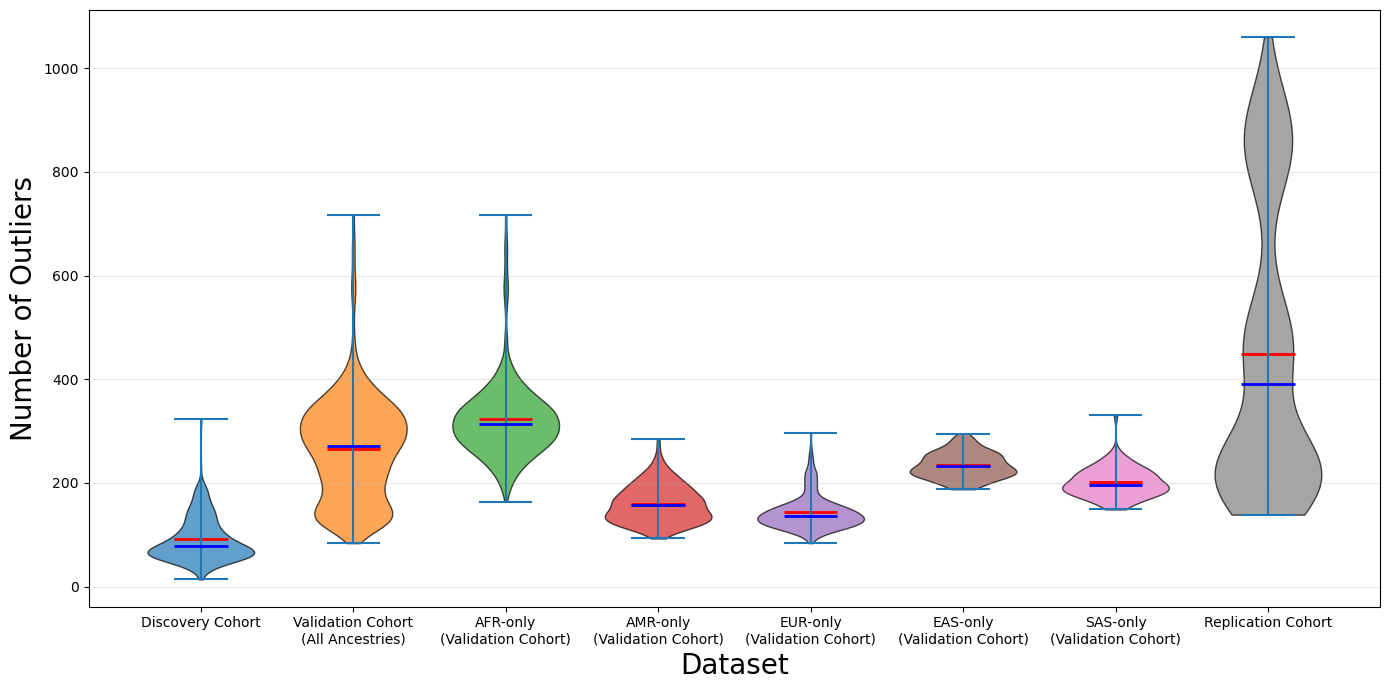


=== Summary Statistics for 99.9th Percentile Outliers ===

Discovery Cohort:
  Mean: 91.20
  Median: 78.00
  Std Dev: 41.96
  Min: 14.00
  Max: 324.00
  N samples: 543

Validation Cohort
(All Ancestries):
  Mean: 265.59
  Median: 271.00
  Std Dev: 100.00
  Min: 84.00
  Max: 717.00
  N samples: 2128

AFR-only
(Validation Cohort):
  Mean: 323.15
  Median: 314.00
  Std Dev: 76.83
  Min: 164.00
  Max: 717.00
  N samples: 1323

AMR-only
(Validation Cohort):
  Mean: 160.41
  Median: 157.00
  Std Dev: 36.10
  Min: 93.00
  Max: 284.00
  N samples: 290

EUR-only
(Validation Cohort):
  Mean: 143.91
  Median: 136.00
  Std Dev: 32.70
  Min: 84.00
  Max: 296.00
  N samples: 296

EAS-only
(Validation Cohort):
  Mean: 234.30
  Median: 233.00
  Std Dev: 24.98
  Min: 188.00
  Max: 295.00
  N samples: 123

SAS-only
(Validation Cohort):
  Mean: 201.51
  Median: 195.50
  Std Dev: 29.12
  Min: 149.00
  Max: 332.00
  N samples: 78

Replication Cohort:
  Mean: 449.07
  Median: 390.50
  Std Dev: 274.32
  Min

In [1]:
# initial data loading and package import
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sb
from matplotlib.colors import to_rgba

mpl.rcParams['svg.fonttype'] = 'none'  # keep SVG text in SVGs

highCovComplete=pd.read_csv('assets/outlierAnalyses/DiscoveryCohort_LPSOutliersPerSample_top5Percent.txt',sep='\t')
lowCovComplete=pd.read_csv('assets/outlierAnalyses/ValidationCohort_LPSOutliersPerSample_top5Percent.txt',sep='\t')
AFR=pd.read_csv('assets/outlierAnalyses/ValidationCohort_LPSOutliersPerSample_AFR_top5Percent.txt',sep='\t')
AMR=pd.read_csv('assets/outlierAnalyses/ValidationCohort_LPSOutliersPerSample_AMR_top5Percent.txt',sep='\t')
EUR=pd.read_csv('assets/outlierAnalyses/ValidationCohort_LPSOutliersPerSample_EUR_top5Percent.txt',sep='\t')
EAS=pd.read_csv('assets/outlierAnalyses/ValidationCohort_LPSOutliersPerSample_EAS_top5Percent.txt',sep='\t')
SAS=pd.read_csv('assets/outlierAnalyses/ValidationCohort_LPSOutliersPerSample_SAS_top5Percent.txt',sep='\t')
ONT=pd.read_csv('assets/outlierAnalyses/ReplicationCohort_LPSOutliersPerSample_top5Percent.txt',sep='\t')

# Create violin plot for 99.9th Percentile across populations that is also filtered for top 5% most variable loci
datasets = {
    'Discovery Cohort': highCovComplete,
    'Validation Cohort\n(All Ancestries)': lowCovComplete,
    'AFR-only\n(Validation Cohort)': AFR,
    'AMR-only\n(Validation Cohort)': AMR,
    'EUR-only\n(Validation Cohort)': EUR,
    'EAS-only\n(Validation Cohort)': EAS,
    'SAS-only\n(Validation Cohort)': SAS,
    'Replication Cohort': ONT
}

# Collect data for violin plot
plot_data = []
for dataset_name, dataset in datasets.items():
    if '99.9thPercentile' in dataset.columns:
        values = dataset['99.9thPercentile'].dropna()
        for val in values:
            plot_data.append({
                'Dataset': dataset_name,
                'Value': val
            })

plot_df = pd.DataFrame(plot_data)

# Create violin plot
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['svg.fonttype'] = 'none'
fig, ax = plt.subplots(figsize=(14, 7))

# Get colors matching the existing plot style
colors = plt.cm.tab10(np.linspace(0, 0.7, len(datasets)))
color_palette = [plt.cm.tab10(i/9) for i in range(len(datasets))]

# Create violin plot using seaborn
parts = ax.violinplot(
    [plot_df[plot_df['Dataset'] == name]['Value'].values for name in datasets.keys()],
    positions=range(len(datasets)),
    widths=0.7,
    showmeans=True,
    showmedians=True
)

# Color the violin plots
for idx, pc in enumerate(parts['bodies']):
    pc.set_facecolor(color_palette[idx])
    pc.set_alpha(0.7)
    pc.set_edgecolor('black')
    pc.set_linewidth(1)

# Customize other elements
parts['cmeans'].set_color('red')
parts['cmeans'].set_linewidth(2)
parts['cmedians'].set_color('blue')
parts['cmedians'].set_linewidth(2)

# Set labels and title
ax.set_xticks(range(len(datasets)))
ax.set_xticklabels(datasets.keys(), rotation=0, fontsize=10)
ax.set_ylabel('Number of Outliers', fontsize=20)
ax.set_xlabel('Dataset', fontsize=20)
#ax.set_title('Distribution of Allele LPS and Variation Outliers Across Populations', 
#             fontsize=14, fontweight='bold')
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('figures/SupplementaryFigure12B.png',dpi=600)
plt.savefig('figures/SupplementaryFigure12B.svg')
plt.show()

# Print summary statistics
print("\n=== Summary Statistics for 99.9th Percentile Outliers ===")
for dataset_name, dataset in datasets.items():
    if '99.9thPercentile' in dataset.columns:
        values = dataset['99.9thPercentile'].dropna()
        print(f"\n{dataset_name}:")
        print(f"  Mean: {values.mean():.2f}")
        print(f"  Median: {values.median():.2f}")
        print(f"  Std Dev: {values.std():.2f}")
        print(f"  Min: {values.min():.2f}")
        print(f"  Max: {values.max():.2f}")
        print(f"  N samples: {len(values)}")



# S13: Swimlane Plots (Supplementary results)

## S13A

In [ ]:
%%bash
# SCA27B Case using HiFi data
SAMPLEID="SCA27B_case"
repeat_catalog_nickname="TR-Explorer_v1.0.1"
repeat_catalog_nickname2="TR-Explorer_v1.0.1_AoUPhase1"
catalog_lps_stats="DiscoveryCohort_lpsPerLocusStats.TR_Explorer_1.0.1_withPLVI.txt.gz"
pathogenicTRID="13-102161566-102161579-AAGA,13-102161574-102161724-AAG,13-102161829-102161844-A"
bcftools query -f "${SAMPLEID}\t%INFO/TRID\t%INFO/MOTIFS\t[%TGT\t%AL{0}\t%AL{1}\t%SD{0}\t%SD{1}\t%AM{0}\t%AM{1}]" ${SAMPLEID}_${repeat_catalog_nickname}_trgt.vcf.gz > ${SAMPLEID}_${repeat_catalog_nickname}_trgt.txt
python scripts/prioritizeTRWithinSample.py --inputFile=${SAMPLEID}_${repeat_catalog_nickname}_trgt.txt --sampleID=${SAMPLEID} --comparisonCatalog=${catalog_lps_stats} --comparisonCatalogNickname=${repeat_catalog_nickname2} --pathogenicTRID=${pathogenicTRID}

c:\Users\Matt\anaconda3\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Matt\anaconda3\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Matt\anaconda3\lib\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


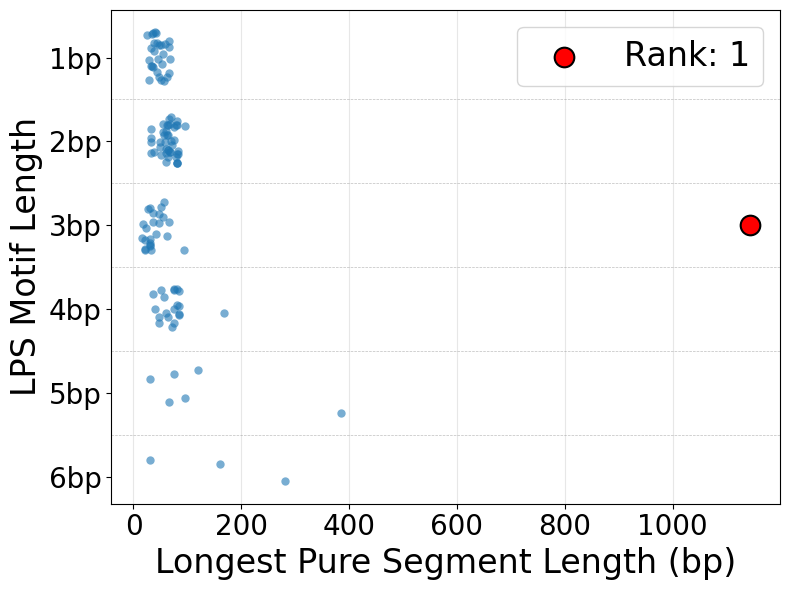

In [ ]:
# re-draw plot using a red circle
import pandas as pd
ranked=pd.read_csv('assets/outlierAnalyses/FGF14_case1/SCA27B_Case_trgt.TR-Explorer_v1.0.1_AoUPhase1_prioritized_ranks.txt',sep='\t')
pathogenicTRID="13-102161566-102161579-AAGA,13-102161574-102161724-AAG,13-102161829-102161844-A"
sampleID="SCA27B_case"
# Create the swimlane plot
import matplotlib as mpl
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 6))

# Define motif categories
motif_categories = ['1bp', '2bp', '3bp', '4bp', '5bp', '6bp']
ranked=ranked.loc[ranked['Motif_Length_Category'].isin(motif_categories),:].reset_index(drop=True)

# get rank of pathogenic variant
overall_rank=ranked[ranked['TRID'] == pathogenicTRID].index.values[0]+1

# Create stripplot with categories
pathogenic_data = ranked[ranked['TRID'] == pathogenicTRID]
# drop the pathogenic entry from sample4_sorted
ranked2 = ranked[ranked['TRID'] != pathogenicTRID]
sns.stripplot(data=ranked2,
            y='Motif_Length_Category',
            x='LPS_Length',
            order=motif_categories,
            alpha=0.6,
            size=6,
            jitter=0.3)

# Add thin dashed grey lines between strips
for i in range(len(motif_categories) - 1):
    plt.axhline(y=i + 0.5, color='grey', linestyle='--', linewidth=0.5, alpha=0.5)

# Highlight the pathogenic TRID if found
plt.scatter(pathogenic_data['LPS_Length'],
            pathogenic_data['Motif_Length_Category'],
            color='red',
            s=200,
            marker='o',
            zorder=5,
            label=f'Rank: {overall_rank}',
            edgecolors='black',
            linewidths=1.5)

plt.xlabel('Longest Pure Segment Length (bp)', fontsize=24)
plt.ylabel('LPS Motif Length', fontsize=24)
plt.tick_params(labelsize=20)
plt.legend(loc='upper right',fontsize=24)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()

# Save the plot
plt.savefig("figures/SupplementaryFigure13A.png", dpi=600, bbox_inches='tight')
plt.savefig("figures/SupplementaryFigure13A.svg", bbox_inches='tight')

## S13B

In [ ]:
%%bash
# SCA27B Case 2 using HiFi data
SAMPLEID="SCA27B_case2"
repeat_catalog_nickname="TR-Explorer_v1.0.1"
repeat_catalog_nickname2="TR-Explorer_v1.0.1_AoUPhase1"
catalog_lps_stats="DiscoveryCohort_lpsPerMotifStats_trgt.TR_Explorer_1.0.1.txt.gz"
pathogenicTRID="13-102161566-102161579-AAGA,13-102161574-102161724-AAG,13-102161829-102161844-A"
bcftools query -f "${SAMPLEID}\t%INFO/TRID\t%INFO/MOTIFS\t[%TGT\t%AL{0}\t%AL{1}\t%SD{0}\t%SD{1}\t%AM{0}\t%AM{1}]" ${SAMPLEID}_${repeat_catalog_nickname}_trgt.vcf.gz > ${SAMPLEID}_${repeat_catalog_nickname}_trgt.txt
python scripts/prioritizeTRWithinSample.py --inputFile=${SAMPLEID}_${repeat_catalog_nickname}_trgt.txt --sampleID=${SAMPLEID} --comparisonCatalog=${catalog_lps_stats} --comparisonCatalogNickname=${repeat_catalog_nickname2} --pathogenicTRID=${pathogenicTRID}


c:\Users\Matt\anaconda3\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Matt\anaconda3\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Matt\anaconda3\lib\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


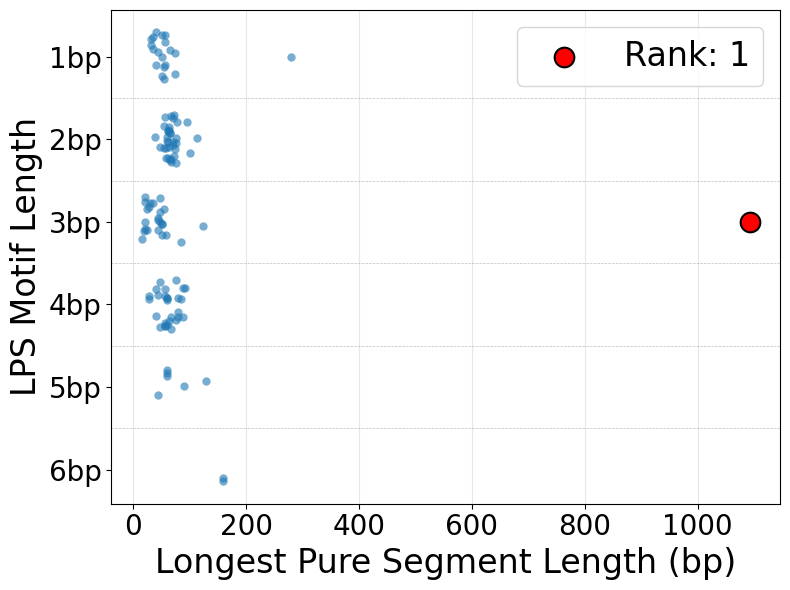

In [ ]:
# re-draw plot using a red circle
import pandas as pd
ranked=pd.read_csv('assets/outlierAnalyses/FGF14_case2/SCA27B_Case2_trgt.TR-Explorer_v1.0.1_AoUPhase1_prioritized_ranks.txt',sep='\t')
pathogenicTRID="13-102161566-102161579-AAGA,13-102161574-102161724-AAG,13-102161829-102161844-A"
sampleID="SCA27B_case2"

# Create the swimlane plot
import matplotlib as mpl
import seaborn as sns
plt.figure(figsize=(8, 6))

# Define motif categories
motif_categories = ['1bp', '2bp', '3bp', '4bp', '5bp', '6bp']
ranked=ranked.loc[ranked['Motif_Length_Category'].isin(motif_categories),:].reset_index(drop=True)

# get rank of pathogenic variant
overall_rank=ranked[ranked['TRID'] == pathogenicTRID].index.values[0]+1

# Create stripplot with categories
pathogenic_data = ranked[ranked['TRID'] == pathogenicTRID]
# drop the pathogenic entry from sample4_sorted
ranked2 = ranked[ranked['TRID'] != pathogenicTRID]
sns.stripplot(data=ranked2,
            y='Motif_Length_Category',
            x='LPS_Length',
            order=motif_categories,
            alpha=0.6,
            size=6,
            jitter=0.3)

# Add thin dashed grey lines between strips
for i in range(len(motif_categories) - 1):
    plt.axhline(y=i + 0.5, color='grey', linestyle='--', linewidth=0.5, alpha=0.5)

# Highlight the pathogenic TRID if found
plt.scatter(pathogenic_data['LPS_Length'],
            pathogenic_data['Motif_Length_Category'],
            color='red',
            s=200,
            marker='o',
            zorder=5,
            label=f'Rank: {overall_rank}',
            edgecolors='black',
            linewidths=1.5)

plt.xlabel('Longest Pure Segment Length (bp)', fontsize=24)
plt.ylabel('LPS Motif Length', fontsize=24)
plt.tick_params(labelsize=20)
plt.legend(loc='upper right',fontsize=24)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()

# Save the plot
plt.savefig("figures/SupplementaryFigure13B.png", dpi=600, bbox_inches='tight')
plt.savefig("figures/SupplementaryFigure13B.svg", bbox_inches='tight')

## S13C

In [ ]:
%%bash
# ATXN2 Case using HiFi data
SAMPLEID="ATXN2_case"
repeat_catalog_nickname="TR-Explorer_v1.0.1"
repeat_catalog_nickname2="TR-Explorer_v1.0.1_AoUPhase1"
catalog_lps_stats="DiscoveryCohort_lpsPerMotifStats_trgt.TR_Explorer_1.0.1.txt.gz"
pathogenicTRID="12-111598949-111599018-GCT"
bcftools query -f "${SAMPLEID}\t%INFO/TRID\t%INFO/MOTIFS\t[%TGT\t%AL{0}\t%AL{1}\t%SD{0}\t%SD{1}\t%AM{0}\t%AM{1}]" ${SAMPLEID}_${repeat_catalog_nickname}_trgt.vcf.gz > ${SAMPLEID}_${repeat_catalog_nickname}_trgt.txt
python scripts/prioritizeTRWithinSample.py --inputFile=${SAMPLEID}_${repeat_catalog_nickname}_trgt.txt --sampleID=${SAMPLEID} --comparisonCatalog=${catalog_lps_stats} --comparisonCatalogNickname=${repeat_catalog_nickname2} --pathogenicTRID=${pathogenicTRID}


c:\Users\Matt\anaconda3\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Matt\anaconda3\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Matt\anaconda3\lib\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


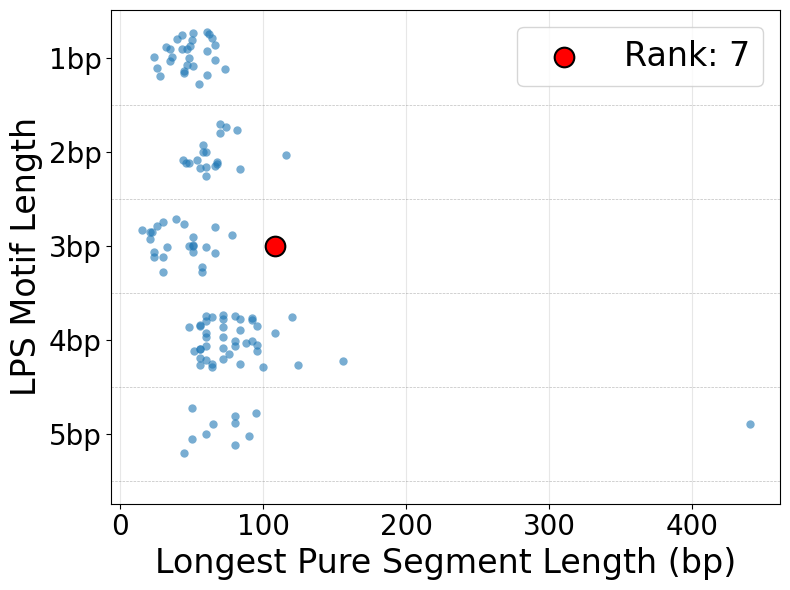

In [ ]:
# re-draw plot using a red circle
import pandas as pd
ranked=pd.read_csv('assets/outlierAnalyses/ATXN2/ATXN2_case_trgt.TR-Explorer_1.0.1_DiscoveryCohort_prioritized_ranks.txt',sep='\t')
pathogenicTRID="12-111598949-111599018-GCT"

# Create the swimlane plot
import matplotlib as mpl
import seaborn as sns
plt.figure(figsize=(8, 6))

# Define motif categories
motif_categories = ['1bp', '2bp', '3bp', '4bp', '5bp', '6bp']
ranked=ranked.loc[ranked['Motif_Length_Category'].isin(motif_categories),:].reset_index(drop=True)

# get rank of pathogenic variant
overall_rank=ranked[ranked['TRID'] == pathogenicTRID].index.values[0]+1

# Create stripplot with categories
pathogenic_data = ranked[ranked['TRID'] == pathogenicTRID]
# drop the pathogenic entry from sample4_sorted
ranked2 = ranked[ranked['TRID'] != pathogenicTRID]
sns.stripplot(data=ranked2,
            y='Motif_Length_Category',
            x='LPS_Length',
            order=motif_categories,
            alpha=0.6,
            size=6,
            jitter=0.3)

# Add thin dashed grey lines between strips
for i in range(len(motif_categories) - 1):
    plt.axhline(y=i + 0.5, color='grey', linestyle='--', linewidth=0.5, alpha=0.5)

# Highlight the pathogenic TRID if found
plt.scatter(pathogenic_data['LPS_Length'],
            pathogenic_data['Motif_Length_Category'],
            color='red',
            s=200,
            marker='o',
            zorder=5,
            label=f'Rank: {overall_rank}',
            edgecolors='black',
            linewidths=1.5)

plt.xlabel('Longest Pure Segment Length (bp)', fontsize=24)
plt.ylabel('LPS Motif Length', fontsize=24)
plt.tick_params(labelsize=20)
plt.legend(loc='upper right',fontsize=24)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()

# Save the plot
plt.savefig("figures/SupplementaryFigure13C.png", dpi=600, bbox_inches='tight')
plt.savefig("figures/SupplementaryFigure13C.svg", bbox_inches='tight')

## S13D

In [ ]:
%%bash
# ATXN3 Case using HiFi data
SAMPLEID="ATXN3_case"
repeat_catalog_nickname="TR-Explorer_v1.0.1"
repeat_catalog_nickname2="TR-Explorer_v1.0.1_AoUPhase1"
catalog_lps_stats="DiscoveryCohort_lpsPerMotifStats_trgt.TR_Explorer_1.0.1.txt.gz"
pathogenicTRID="14-92071010-92071040-CTG"
bcftools query -f "${SAMPLEID}\t%INFO/TRID\t%INFO/MOTIFS\t[%TGT\t%AL{0}\t%AL{1}\t%SD{0}\t%SD{1}\t%AM{0}\t%AM{1}]" ${SAMPLEID}_${repeat_catalog_nickname}_trgt.vcf.gz > ${SAMPLEID}_${repeat_catalog_nickname}_trgt.txt
python scripts/prioritizeTRWithinSample.py --inputFile=${SAMPLEID}_${repeat_catalog_nickname}_trgt.txt --sampleID=${SAMPLEID} --comparisonCatalog=${catalog_lps_stats} --comparisonCatalogNickname=${repeat_catalog_nickname2} --pathogenicTRID=${pathogenicTRID}


c:\Users\Matt\anaconda3\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Matt\anaconda3\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Matt\anaconda3\lib\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


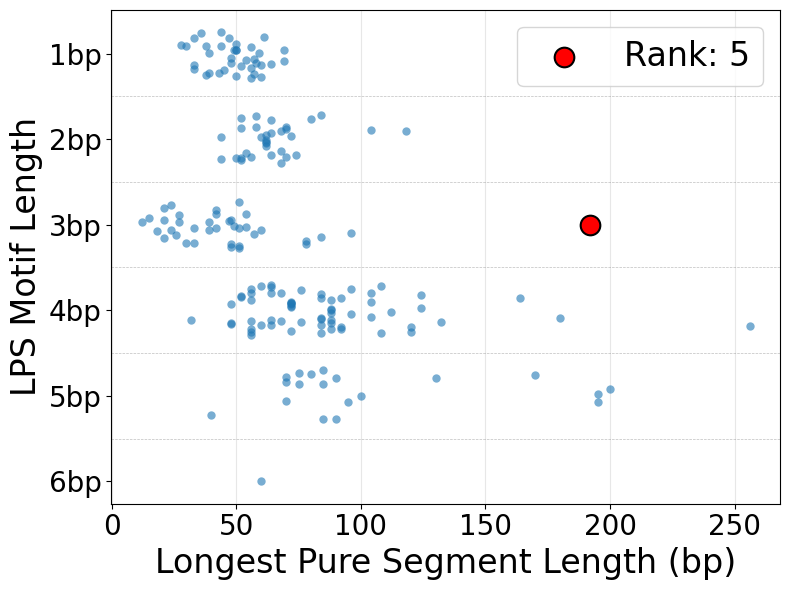

In [ ]:
# re-draw plot using a red circle
import pandas as pd
ranked=pd.read_csv('assets/outlierAnalyses/ATXN3/ATXN3_case_trgt.TR-Explorer_1.0.1_DiscoveryCohort_prioritized_ranks.txt',sep='\t')
pathogenicTRID="14-92071010-92071040-CTG"

# Create the swimlane plot
import matplotlib as mpl
import seaborn as sns
plt.figure(figsize=(8, 6))

# Define motif categories
motif_categories = ['1bp', '2bp', '3bp', '4bp', '5bp', '6bp']
ranked=ranked.loc[ranked['Motif_Length_Category'].isin(motif_categories),:].reset_index(drop=True)

# get rank of pathogenic variant
overall_rank=ranked[ranked['TRID'] == pathogenicTRID].index.values[0]+1

# Create stripplot with categories
pathogenic_data = ranked[ranked['TRID'] == pathogenicTRID]
# drop the pathogenic entry from sample4_sorted
ranked2 = ranked[ranked['TRID'] != pathogenicTRID]
sns.stripplot(data=ranked2,
            y='Motif_Length_Category',
            x='LPS_Length',
            order=motif_categories,
            alpha=0.6,
            size=6,
            jitter=0.3)

# Add thin dashed grey lines between strips
for i in range(len(motif_categories) - 1):
    plt.axhline(y=i + 0.5, color='grey', linestyle='--', linewidth=0.5, alpha=0.5)

# Highlight the pathogenic TRID if found
plt.scatter(pathogenic_data['LPS_Length'],
            pathogenic_data['Motif_Length_Category'],
            color='red',
            s=200,
            marker='o',
            zorder=5,
            label=f'Rank: {overall_rank}',
            edgecolors='black',
            linewidths=1.5)

plt.xlabel('Longest Pure Segment Length (bp)', fontsize=24)
plt.ylabel('LPS Motif Length', fontsize=24)
plt.tick_params(labelsize=20)
plt.legend(loc='upper right',fontsize=24)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()

# Save the plot
plt.savefig("figures/SupplementaryFigure13D.png", dpi=600, bbox_inches='tight')
plt.savefig("figures/SupplementaryFigure13D.svg", bbox_inches='tight')

## S13E

In [ ]:
%%bash
# ATN1 Case using HiFi data
SAMPLEID="ATN1_case"
repeat_catalog_nickname="TR-Explorer_v1.0.1"
repeat_catalog_nickname2="TR-Explorer_v1.0.1_AoUPhase1"
catalog_lps_stats="ReplicationCohort_lpsPerLocusStats.TR_Explorer_1.0.1.txt.gz"
pathogenicTRID="12-6936716-6936773-CAG"
bcftools query -f "${SAMPLEID}\t%INFO/TRID\t%INFO/MOTIFS\t[%TGT\t%AL{0}\t%AL{1}\t%SD{0}\t%SD{1}\t%AM{0}\t%AM{1}]" ${SAMPLEID}_${repeat_catalog_nickname}_trgt.vcf.gz > ${SAMPLEID}_${repeat_catalog_nickname}_trgt.txt
python scripts/prioritizeTRWithinSample.py --inputFile=${SAMPLEID}_${repeat_catalog_nickname}_trgt.txt --sampleID=${SAMPLEID} --comparisonCatalog=${catalog_lps_stats} --comparisonCatalogNickname=${repeat_catalog_nickname2} --pathogenicTRID=${pathogenicTRID}


c:\Users\Matt\anaconda3\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Matt\anaconda3\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\Matt\anaconda3\lib\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


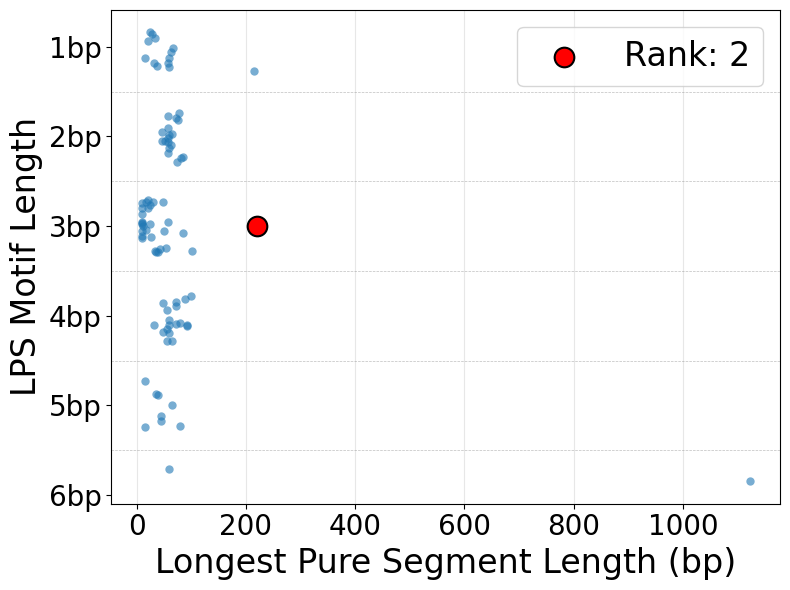

In [ ]:
# re-draw plot using a red circle
import pandas as pd
ranked=pd.read_csv('assets/outlierAnalyses/ATN1/ATN1_case_trgt.TR-Explorer_v1.0.1_AoUPhase1_prioritized_ranks.txt',sep='\t')
pathogenicTRID="12-6936716-6936773-CAG"

# Create the swimlane plot
import matplotlib as mpl
import seaborn as sns
plt.figure(figsize=(8, 6))

# Define motif categories
motif_categories = ['1bp', '2bp', '3bp', '4bp', '5bp', '6bp']
ranked=ranked.loc[ranked['Motif_Length_Category'].isin(motif_categories),:].reset_index(drop=True)

# get rank of pathogenic variant
overall_rank=ranked[ranked['TRID'] == pathogenicTRID].index.values[0]+1

# Create stripplot with categories
pathogenic_data = ranked[ranked['TRID'] == pathogenicTRID]
# drop the pathogenic entry from sample4_sorted
ranked2 = ranked[ranked['TRID'] != pathogenicTRID]
sns.stripplot(data=ranked2,
            y='Motif_Length_Category',
            x='LPS_Length',
            order=motif_categories,
            alpha=0.6,
            size=6,
            jitter=0.3)

# Add thin dashed grey lines between strips
for i in range(len(motif_categories) - 1):
    plt.axhline(y=i + 0.5, color='grey', linestyle='--', linewidth=0.5, alpha=0.5)

# Highlight the pathogenic TRID if found
plt.scatter(pathogenic_data['LPS_Length'],
            pathogenic_data['Motif_Length_Category'],
            color='red',
            s=200,
            marker='o',
            zorder=5,
            label=f'Rank: {overall_rank}',
            edgecolors='black',
            linewidths=1.5)

plt.xlabel('Longest Pure Segment Length (bp)', fontsize=24)
plt.ylabel('LPS Motif Length', fontsize=24)
plt.tick_params(labelsize=20)
plt.legend(loc='upper right',fontsize=24)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()

# Save the plot
plt.savefig("figures/SupplementaryFigure13E.png", dpi=600, bbox_inches='tight')
plt.savefig("figures/SupplementaryFigure13E.svg", bbox_inches='tight')

## S13F

In [2]:
import matplotlib.pyplot as plt
import pandas
import numpy as np
import os

filterSets = {
    'PLVI and Length Filters':            ('PLVI+LPS_99.9thPercentile', 'LPS_Length'),
    'Length Filters Only':   ('AlleleLength_99.9thPercentile', 'Allele_Length'),
    'No Filters': ('unfiltered', 'Allele_Length'),
}

ranksByFilter={'PLVI and Length Filters':[],'Length Filters Only':[],'No Filters':[]}
for sample in ["ATN1","ATXN2","ATXN3","FGF14_case1","FGF14_case2","HTT"]:
    fileNames=[f for f in os.listdir(f'assets/outlierAnalyses/{sample}') if f.endswith('_rankComparison.txt')]
    thisSampleResults=pandas.read_csv(f'assets/outlierAnalyses/{sample}/{fileNames[0]}',sep='\t')
    for filterSet, (filterName, rankVal) in filterSets.items():
        ranksByFilter[filterSet].append(thisSampleResults.loc[((thisSampleResults['filter']==filterName) & (thisSampleResults['rankBy']==rankVal)),'rankNoVNTRs'].values[0])
ranksByFilter

{'PLVI and Length Filters': [4, 7, 5, 1, 1, 2],
 'Length Filters Only': [33, 266, 275, 94, 86, 172],
 'No Filters': [20643, 88231, 30926, 2632, 2889, 22832]}

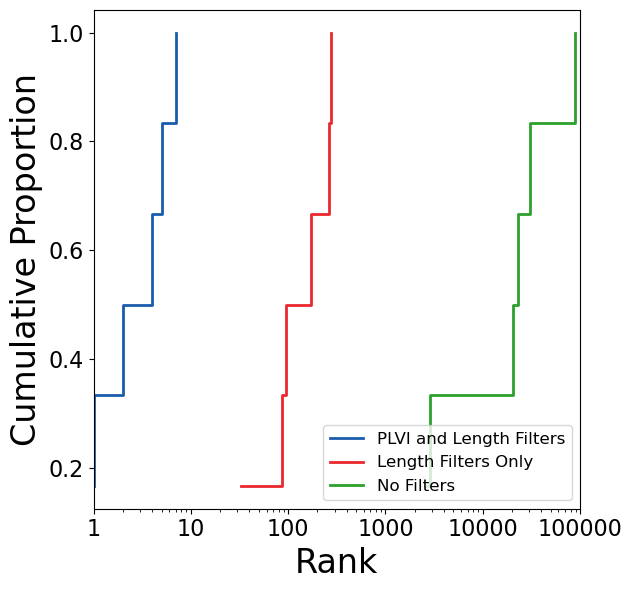

In [3]:
import matplotlib.ticker as ticker
from matplotlib.lines import Line2D

fig, ax = plt.subplots(figsize=(6, 6))

filterColors = {
    'PLVI and Length Filters': '#195CAC',
    'Length Filters Only': '#EB282D',
    'No Filters': '#2ca02c',
}

for label, color in filterColors.items():
    ranks = ranksByFilter[label]
    sorted_ranks = np.sort(ranks)
    ecdf = np.arange(1, len(sorted_ranks) + 1) / len(sorted_ranks)
    ax.step(sorted_ranks, ecdf, color=color, linewidth=2, where='post')

# legend: colors for genic region, line styles for filter set
handles = [Line2D([0], [0], color=color, linewidth=2, label=f'{label}')
           for label, color in filterColors.items()]
ax.set_xscale('log')
ax.set_xlim([1,100000])
ax.set_xlabel('Rank',fontsize=24)
ax.set_ylabel('Cumulative Proportion',fontsize=24)
ax.tick_params(labelsize=16)
ax.legend(handles=handles,fontsize=12,loc='lower right')
ax.xaxis.set_major_formatter(ticker.ScalarFormatter())
ax.xaxis.set_minor_formatter(ticker.NullFormatter())
plt.tight_layout()
plt.savefig('figures/SupplementaryFigure13F.png',dpi=600)
plt.savefig('figures/SupplementaryFigure13F.svg')
plt.show()

## S13G

In [4]:
# collect output scorecards and produce a figure of the results
import matplotlib.pyplot as plt
import pandas
import numpy as np
pathogenicTRs=pandas.read_csv('assets/pathogenicTRIDs_TRExplorer_v1.0.1_STRchiveFiltered_noVNTRs_withAnno.txt',sep='\t')
polyAlanineTRNames = ['ARX','NIPA1','HOXA13','PHOX2B','SOX3','HOXD13','ZIC2','RUNX2','PABPN1','FOXL2']
singleShiftTRNames = ['MIR7-2','COMP']
pathogenicTRs = pathogenicTRs.loc[~pathogenicTRs['geneName'].isin(polyAlanineTRNames),:]
pathogenicTRs = pathogenicTRs.loc[~pathogenicTRs['geneName'].isin(singleShiftTRNames),:].reset_index(drop=True)

# filter set -> (score file suffix, rank column)
# original: PLVI + 99.9th percentile filters, STRs only, ranked by LPS length
# noFilt: no filtering, ranked by LPS length
# pctFiltOnly: 99.9th percentile filter only, ranked by LPS length
filterSets = {
    'plvi_and_lenFilt': ('',             'noVNTRsRank'),
    'lenFiltOnly':  ('_alleleLenPctFiltOnly', 'noVNTRsAlleleLengthRank'),
    'noFilt':          ('_noFilt',      'noVNTRsAlleleLengthRank'),
}

# separate into coding, intronic, and UTR_5
coding=pathogenicTRs.loc[pathogenicTRs['Region']=='coding',:]
intronic=pathogenicTRs.loc[pathogenicTRs['Region']=='intron',:]
utr=pathogenicTRs.loc[pathogenicTRs['Region'].str.contains('UTR'),:]

ranksByFilter={}
for filterSet, (suffix, rankCol) in filterSets.items():
    ranks={}
    for sample in ["HG002","HG00438","HG00099","HG00733","HG00741","HG01106","HG01928","HG02055","HG02109","HG03579"]:
        thisSampleResults=pandas.read_csv(f'prioritizeTRWithinSample/HPRC_spikeIn/{sample}{suffix}_spikeInScores.txt',sep='\t',index_col=0)
        for TRID in thisSampleResults.index.values:
            if TRID in ranks:
                ranks[TRID].append(thisSampleResults.loc[TRID,rankCol])
            else:
                ranks[TRID]=[thisSampleResults.loc[TRID,rankCol]]

    ranksCoding=[]
    ranksIntronic=[]
    ranksUTR=[]
    ranksCombined=[]
    for TRID in coding.TRID.values:
        ranksCoding.extend(ranks[TRID])
    for TRID in intronic.TRID.values:
        ranksIntronic.extend(ranks[TRID])
    for TRID in utr.TRID.values:
        ranksUTR.extend(ranks[TRID])
    for TRID in pathogenicTRs.TRID.values:
        ranksCombined.extend(ranks[TRID])
    ranksByFilter[filterSet]={'Coding':ranksCoding,'Intronic':ranksIntronic,'UTR':ranksUTR,'Combined':ranksCombined}

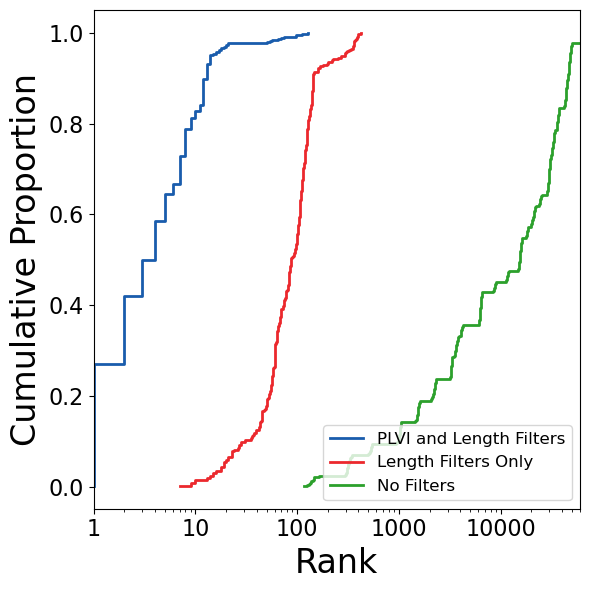

In [5]:
import matplotlib.ticker as ticker
from matplotlib.lines import Line2D

fig, ax = plt.subplots(figsize=(6, 6))

filterColors = {
    'plvi_and_lenFilt':'#195CAC',
    'lenFiltOnly': '#EB282D',
    'noFilt': '#2ca02c',
}
filterLabels=['PLVI and Length Filters','Length Filters Only','No Filters']
colors=['#195CAC','#EB282D','#2ca02c']

for label, color in filterColors.items():
    ranks = ranksByFilter[label]['Combined']
    sorted_ranks = np.sort(ranks)
    ecdf = np.arange(1, len(sorted_ranks) + 1) / len(sorted_ranks)
    ax.step(sorted_ranks, ecdf, color=color, linewidth=2, where='post')

# legend: colors for genic region, line styles for filter set
handles = [Line2D([0], [0], color=colors[i], linewidth=2, label=f'{filterLabels[i]}')
           for i in range(3)]

ax.set_xscale('log')
ax.set_xlim([1,60000])
ax.set_xlabel('Rank',fontsize=24)
ax.set_ylabel('Cumulative Proportion',fontsize=24)
ax.tick_params(labelsize=16)
#ax.set_title('HPRC spike-in rank distribution')
ax.legend(handles=handles,fontsize=12,loc='lower right')
ax.xaxis.set_major_formatter(ticker.ScalarFormatter())
ax.xaxis.set_minor_formatter(ticker.NullFormatter())
plt.tight_layout()
plt.savefig('figures/SupplementaryFigure13G.png',dpi=600)
plt.savefig('figures/SupplementaryFigure13G.svg')
plt.show()

## S13H

In [6]:
# collect output scorecards and produce a figure of the results
import matplotlib.pyplot as plt
import pandas
import numpy as np
pathogenicTRs=pandas.read_csv('assets/pathogenicTRIDs_TRExplorer_v1.0.1_STRchiveFiltered_noVNTRs_withAnno.txt',sep='\t')
polyAlanineTRNames = ['ARX','NIPA1','HOXA13','PHOX2B','SOX3','HOXD13','ZIC2','RUNX2','PABPN1','FOXL2']
singleShiftTRNames = ['MIR7-2','COMP']
pathogenicTRs = pathogenicTRs.loc[~pathogenicTRs['geneName'].isin(polyAlanineTRNames),:]
pathogenicTRs = pathogenicTRs.loc[~pathogenicTRs['geneName'].isin(singleShiftTRNames),:].reset_index(drop=True)

# filter set -> (score file suffix, rank column)
# original: PLVI + 99.9th percentile filters, STRs only, ranked by LPS length
# noFilt: no filtering, ranked by LPS length
# pctFiltOnly: 99.9th percentile filter only, ranked by LPS length
filterSets = {
    'Standard':            ('_extraFilters', 'noVNTRsRank'),
    'Remove Intergenic':   ('_extraFilters', 'noVNTRsRank_geneDistance'),
    'Remove Homopolymers': ('_extraFilters', 'noVNTRsRank_noHomopolymer'),
    'Remove Both':         ('_extraFilters', 'noVNTRsRank_bothFilters'),
}

# separate into coding, intronic, and UTR_5
coding=pathogenicTRs.loc[pathogenicTRs['Region']=='coding',:]
intronic=pathogenicTRs.loc[pathogenicTRs['Region']=='intron',:]
utr=pathogenicTRs.loc[pathogenicTRs['Region'].str.contains('UTR'),:]

ranksByFilter={}
for filterSet, (suffix, rankCol) in filterSets.items():
    ranks={}
    for sample in ["HG002","HG00438","HG00099","HG00733","HG00741","HG01106","HG01928","HG02055","HG02109","HG03579"]:
        thisSampleResults=pandas.read_csv(f'prioritizeTRWithinSample/HPRC_spikeIn/{sample}{suffix}_spikeInScores.txt',sep='\t',index_col=0)
        for TRID in thisSampleResults.index.values:
            if TRID in ranks:
                ranks[TRID].append(thisSampleResults.loc[TRID,rankCol])
            else:
                ranks[TRID]=[thisSampleResults.loc[TRID,rankCol]]

    ranksCoding=[]
    ranksIntronic=[]
    ranksUTR=[]
    ranksCombined=[]
    for TRID in coding.TRID.values:
        ranksCoding.extend(ranks[TRID])
    for TRID in intronic.TRID.values:
        ranksIntronic.extend(ranks[TRID])
    for TRID in utr.TRID.values:
        ranksUTR.extend(ranks[TRID])
    for TRID in pathogenicTRs.TRID.values:
        ranksCombined.extend(ranks[TRID])
    ranksByFilter[filterSet]={'Coding':ranksCoding,'Intronic':ranksIntronic,'UTR':ranksUTR,'Combined':ranksCombined}

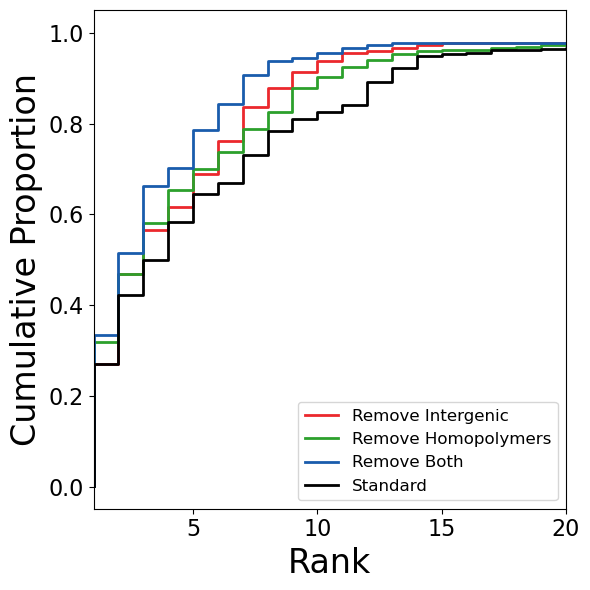

In [7]:
import matplotlib.ticker as ticker
from matplotlib.lines import Line2D

fig, ax = plt.subplots(figsize=(6, 6))

filterColors = {
    'Remove Intergenic': '#EB282D',
    'Remove Homopolymers': '#2ca02c',
    'Remove Both': '#195CAC',
    'Standard':'k',
}

for label, color in filterColors.items():
    ranks = ranksByFilter[label]['Combined']
    sorted_ranks = np.sort(ranks)
    ecdf = np.arange(1, len(sorted_ranks) + 1) / len(sorted_ranks)
    ax.step(sorted_ranks, ecdf, color=color, linewidth=2, where='post')

# legend: colors for genic region, line styles for filter set
handles = [Line2D([0], [0], color=color, linewidth=2, label=f'{label}')
           for label, color in filterColors.items()]
ax.set_xlim([1,20])
ax.set_xlabel('Rank',fontsize=24)
ax.set_ylabel('Cumulative Proportion',fontsize=24)
ax.tick_params(labelsize=16)
#ax.set_title('HPRC spike-in rank distribution')
ax.legend(handles=handles,fontsize=12,loc='lower right')
ax.xaxis.set_major_formatter(ticker.ScalarFormatter())
ax.xaxis.set_minor_formatter(ticker.NullFormatter())
plt.tight_layout()
plt.savefig('figures/SupplementaryFigure13H.png',dpi=600)
plt.savefig('figures/SupplementaryFigure13H.svg')
plt.show()

# S14: Variation at Disease-associated STRs

In [25]:
# boxplot of the distributions of allele lengths for each disease-associated STR, ordered by median size
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sb
import matplotlib
from matplotlib.colors import to_rgba

mpl.rcParams['svg.fonttype'] = 'none'  # keep SVG text in SVGs

alleleLengths=pd.read_csv('assets/pathogenicSTRs_alleleInfo_noIDs.txt',sep='\t',header=None,
                          names=['TRID','Allele1','Allele2','Allele1_LPS_Length','Allele1_LPS_Motif','Allele2_LPS_Length','Allele2_LPS_Motif','Allele1_Len','Allele2_Len'])

# Define pathogenic and poly-alanine TRIDs
pathogenic=pd.read_csv('assets/pathogenicTRIDs_TRExplorer_v1.0.1_STRchiveFiltered_noVNTRs_withAnno.txt',sep='\t')
alleleLengths=alleleLengths.merge(pathogenic,how='inner',on='TRID')
alleleLengths

,TRID,Allele1,Allele2,Allele1_LPS_Length,Allele1_LPS_Motif,Allele2_LPS_Length,Allele2_LPS_Motif,Allele1_Len,Allele2_Len,geneName,Region
0,1-57367043-57367118-AAAAT,CAAAATAAAATAAAATAAAATAAAATAAAATAAAAT,CAAAATAAAATAAAATAAAATAAAATAAAATAAAATAAAATAAAAT...,35,AAAAT,70,AAAAT,35,70,DAB1,intron
1,1-94418421-94418442-GCC,AGCCGCCGCCGCCGCCGCCGCC,AGCCGCCGCCGCCGCCGCCGCC,21,GCC,21,GCC,21,21,ABCD3,UTR_5
2,1-149390802-149390841-GGC,AGGCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGC...,AGGCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGC...,45,GGC,63,GGC,57,75,NOTCH2NLC,UTR_5
3,1-57367043-57367118-AAAAT,CAAAATAAAATAAAATAAAATAAAATAAAATAAAATAAAATAAAAT...,CAAAATAAAATAAAATAAAATAAAATAAAATAAAATAAAATAAAAT...,70,AAAAT,90,AAAAT,70,90,DAB1,intron
4,1-94418421-94418442-GCC,AGCCGCCGCCGCCGCCGCCGCC,AGCCGCCGCCGCCGCCGCCGCC,21,GCC,21,GCC,21,21,ABCD3,UTR_5
...,...,...,...,...,...,...,...,...,...,...,...
28774,X-25013649-25013697-NGC,TGGCGGCCGCTGCCGCCGCCGCCGCCGCCGCCGCCGCCGCCGCTGCCGC,.,30,CCG,-1,NaN,48,.,ARX,coding
28775,"X-67545306-67545318-TGC,X-67545400-67545419-GCA",TTGCTGCTGCTGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGC...,.,57,GCA,-1,NaN,101,.,AR,coding
28776,X-140504316-140504361-NGC,TGGCGGCAGCGGCTGCGGCCGCGGCAGCGGCGGCGGCGGCCGCGGC,.,12,CGG,-1,NaN,45,.,SOX3,coding
28777,X-147912050-147912110-CGG,GCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGGCGG...,.,57,CGG,-1,NaN,87,.,FMR1,UTR_5


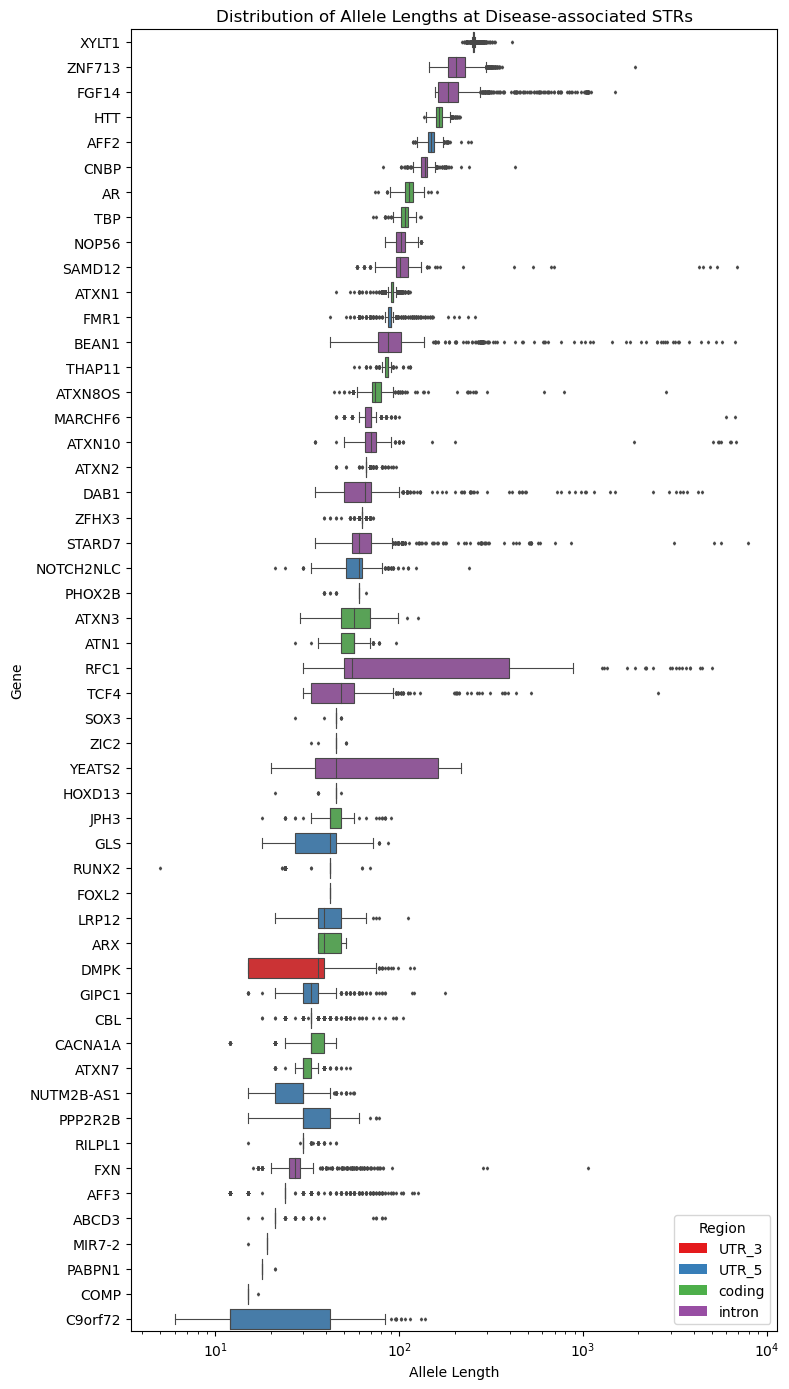

In [ ]:
# Melt allele lengths to long format and plot per-gene boxplots colored by Region
al = alleleLengths.copy()
al['Allele1_Len'] = pd.to_numeric(al['Allele1_Len'], errors='coerce')
al['Allele2_Len'] = pd.to_numeric(al['Allele2_Len'], errors='coerce')

melted = al.melt(
    id_vars=['geneName', 'Region'],
    value_vars=['Allele1_Len', 'Allele2_Len'],
    var_name='AlleleNum',
    value_name='AlleleLength'
).dropna(subset=['AlleleLength'])

# Sort genes by median allele length (lowest at top, highest at bottom)
gene_order = (melted.groupby('geneName')['AlleleLength']
              .median()
              .sort_values(ascending=False)
              .index.tolist())

# Map each gene to its Region and assign colors
gene_region = melted.groupby('geneName')['Region'].first()
region_colors = {'UTR_3': '#e41a1c', 'UTR_5': '#377eb8', 'coding': '#4daf4a', 'intron': '#984ea3'}
palette = {gene: region_colors.get(gene_region[gene], 'gray') for gene in gene_order}

fig, ax = plt.subplots(figsize=(8, 14))
sb.boxplot(data=melted, y='geneName', x='AlleleLength', order=gene_order,
           palette=palette, fliersize=1.5, linewidth=0.8, ax=ax)

ax.set_xlabel('Allele Length')
ax.set_ylabel('Gene')
ax.set_title('Distribution of Allele Lengths at Disease-associated STRs')
plt.xscale('log')

from matplotlib.patches import Patch
present_regions = [r for r in ['UTR_3', 'UTR_5', 'coding', 'intron'] if r in gene_region.values]
legend_handles = [Patch(facecolor=region_colors[r], label=r) for r in present_regions]
ax.legend(handles=legend_handles, title='Region', loc='lower right')

plt.tight_layout()
plt.savefig('figures/SupplementaryFigure14.png',dpi=600)
plt.savefig('figures/SupplementaryFigure14.svg')



# S15: FMR1 Interruptions

## S15A

In [50]:
import pandas
fmr1Alleles=pandas.read_csv('assets/FMR1_alleleInfo_noIDs.txt',sep='\t',header=None,names=
                            ['TRID','Allele1','Allele2','Allele1_LPS_Length','Allele1_LPS_Motif','Allele2_LPS_Length','Allele2_LPS_Motif','Allele1_Len','Allele2_Len'])
fmr1Alleles

,TRID,Allele1,Allele2,Allele1_LPS_Length,Allele1_LPS_Motif,Allele2_LPS_Length,Allele2_LPS_Motif,Allele1_Len,Allele2_Len
0,X-147912050-147912110-CGG,GCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGGCGG...,GCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGG...,27,CGG,30,CGG,87,90
1,X-147912050-147912110-CGG,GCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGG...,GCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGG...,30,CGG,30,CGG,90,90
2,X-147912050-147912110-CGG,GCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGG...,GCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGG...,30,CGG,60,CGG,90,99
3,X-147912050-147912110-CGG,GCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGGCGG...,GCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGG...,27,CGG,30,CGG,87,90
4,X-147912050-147912110-CGG,GCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGG...,GCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGG...,30,CGG,30,CGG,90,90
...,...,...,...,...,...,...,...,...,...
538,X-147912050-147912110-CGG,GCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGGCGG...,GCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGG...,27,CGG,30,CGG,87,90
539,X-147912050-147912110-CGG,GCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGG...,GCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGG...,30,CGG,120,CGG,93,153
540,X-147912050-147912110-CGG,GCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGGCGG...,GCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGG...,30,CGG,30,CGG,90,93
541,X-147912050-147912110-CGG,GCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGG...,GCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGG...,30,CGG,30,CGG,90,123


In [51]:
import re
allele1 = fmr1Alleles[['TRID', 'Allele1']].copy().rename(columns={'Allele1':'Allele'})
allele2 = fmr1Alleles[['TRID', 'Allele2']].copy().rename(columns={'Allele2':'Allele'})
alleles=pandas.concat([allele1,allele2], ignore_index=True)
alleles=alleles.loc[alleles['Allele']!=".",:]
alleles['Allele_CGG'] = alleles['Allele'].apply(lambda seq: len(re.findall('CGG', seq)))
alleles['Allele_AGG'] = alleles['Allele'].apply(lambda seq: len(re.findall('AGG', seq)))
alleles['totalTriplets']=alleles.loc[:,'Allele_CGG'] + alleles.loc[:,'Allele_AGG']
alleles

,TRID,Allele,Allele_CGG,Allele_AGG,totalTriplets
0,X-147912050-147912110-CGG,GCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGGCGG...,27,2,29
1,X-147912050-147912110-CGG,GCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGG...,28,2,30
2,X-147912050-147912110-CGG,GCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGG...,28,2,30
3,X-147912050-147912110-CGG,GCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGGCGG...,27,2,29
4,X-147912050-147912110-CGG,GCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGG...,28,2,30
...,...,...,...,...,...
1079,X-147912050-147912110-CGG,GCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGG...,28,2,30
1081,X-147912050-147912110-CGG,GCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGG...,28,2,30
1082,X-147912050-147912110-CGG,GCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGG...,50,1,51
1083,X-147912050-147912110-CGG,GCGGCGGCGGCGGCGGCGGCGGCGGCGGCGGAGGCGGCGGCGGCGG...,29,2,31


In [62]:
print(f'Alleles with under 24 triplets: {len(alleles.loc[alleles["totalTriplets"]<24,:])}')
print(f'Alleles with 24-34 triplets: {len(alleles.loc[((alleles["totalTriplets"]>=24) & (alleles["totalTriplets"]<35)),:])}')
print(f'Alleles with 35-44 triplets: {len(alleles.loc[((alleles["totalTriplets"]>=35) & (alleles["totalTriplets"]<45)),:])}')
print(f'Alleles with 45-54 triplets: {len(alleles.loc[((alleles["totalTriplets"]>=45) & (alleles["totalTriplets"]<54)),:])}')
print(f'Alleles with over 54 triplets: {len(alleles.loc[alleles["totalTriplets"]>54,:])}')
print(f'Alleles with 29 triplets: {len(alleles.loc[alleles["totalTriplets"]==29,:])}')
print(f'Alleles with 30 triplets: {len(alleles.loc[alleles["totalTriplets"]==30,:])}')
print(f'Alleles with 31 triplets: {len(alleles.loc[alleles["totalTriplets"]==31,:])}')

Alleles with under 24 triplets: 79
Alleles with 24-34 triplets: 750
Alleles with 35-44 triplets: 48
Alleles with 45-54 triplets: 14
Alleles with over 54 triplets: 5
Alleles with 29 triplets: 244
Alleles with 30 triplets: 363
Alleles with 31 triplets: 77


In [54]:
alleles.loc[:,'Allele_AGG'].min()

0

In [55]:
alleles.loc[:,'Allele_AGG'].max()

5

In [57]:
print(f'Percentage of alleles with 0 interruptions: {100*len(alleles.loc[alleles["Allele_AGG"]==0,:])/len(alleles)}')
print(f'Percentage of alleles with 1 interruptions: {100*len(alleles.loc[alleles["Allele_AGG"]==1,:])/len(alleles)}')
print(f'Percentage of alleles with 2 interruptions: {100*len(alleles.loc[alleles["Allele_AGG"]==2,:])/len(alleles)}')
print(f'Percentage of alleles with 3 interruptions: {100*len(alleles.loc[alleles["Allele_AGG"]==3,:])/len(alleles)}')
print(f'Percentage of alleles with 4 interruptions: {100*len(alleles.loc[alleles["Allele_AGG"]==4,:])/len(alleles)}')
print(f'Percentage of alleles with 5 interruptions: {100*len(alleles.loc[alleles["Allele_AGG"]==5,:])/len(alleles)}')



Percentage of alleles with 0 interruptions: 3.236607142857143
Percentage of alleles with 1 interruptions: 19.308035714285715
Percentage of alleles with 2 interruptions: 75.22321428571429
Percentage of alleles with 3 interruptions: 1.7857142857142858
Percentage of alleles with 4 interruptions: 0.33482142857142855
Percentage of alleles with 5 interruptions: 0.11160714285714286


In [ ]:
print(f'Percentage of high normal alleles with 3+ interruptions: {100*len(alleles.loc[((alleles["totalTriplets"]>=35) & (alleles["totalTriplets"]<45) & (alleles["Allele_AGG"]>=3)),:])/len(alleles.loc[((alleles["totalTriplets"]>=35) & (alleles["totalTriplets"]<45)),:])}')
print(f'Percentage of grey zone alleles with 3+ interruptions: {100*len(alleles.loc[((alleles["totalTriplets"]>=45) & (alleles["totalTriplets"]<54) & (alleles["Allele_AGG"]>=3)),:])/len(alleles.loc[((alleles["totalTriplets"]>=45) & (alleles["totalTriplets"]<54)),:])}')
print(f'Percentage of grey zone alleles with 4+ interruptions: {100*len(alleles.loc[((alleles["totalTriplets"]>=45) & (alleles["totalTriplets"]<54) & (alleles["Allele_AGG"]>=4)),:])/len(alleles.loc[((alleles["totalTriplets"]>=45) & (alleles["totalTriplets"]<54)),:])}')

Percentage of high normal alleles with 3+ interruptions: 31.25
Percentage of grey zone alleles with 3+ interruptions: 21.428571428571427
Percentage of grey zone alleles with 4+ interruptions: 21.428571428571427


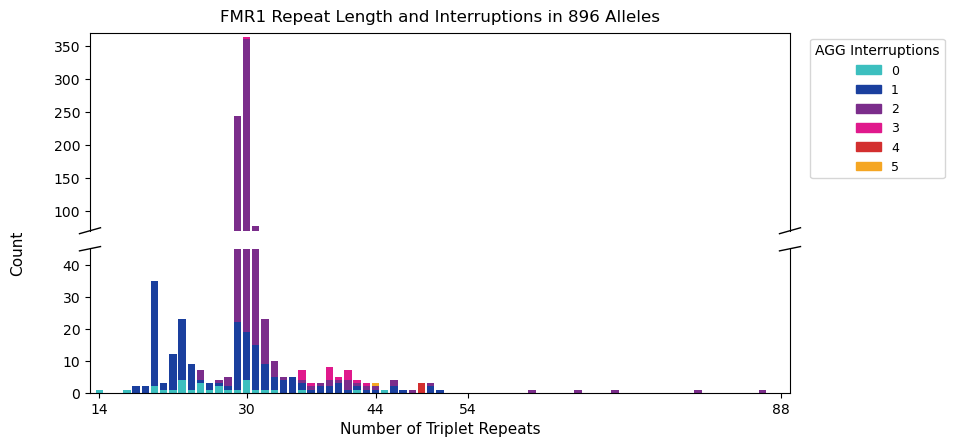

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

# Color palette for AGG interruption counts 0-5
agg_colors = {0: '#3cbfbf', 1: '#1a3f9e', 2: '#7b2d8b', 3: '#e0198c', 4: '#d32f2f', 5: '#f5a623'}
n_alleles = len(alleles)

# --- Pivot data for Panel A ---
pivot_a = alleles.groupby(['totalTriplets', 'Allele_AGG']).size().unstack(fill_value=0)
x_vals = pivot_a.index.values
agg_vals = sorted(pivot_a.columns.tolist())

# --- Pivot data for Panel B ---
bins = [13, 23, 34, 44, 54, 88]
bin_labels = ['(13, 23]', '(23, 34]', '(34, 44]', '(44, 54]', '(54, 88]']
alleles2 = alleles.copy()
alleles2['RepeatBin'] = pandas.cut(alleles2['totalTriplets'], bins=bins, labels=bin_labels)
pivot_b = alleles2.groupby(['RepeatBin', 'Allele_AGG'], observed=True).size().unstack(fill_value=0)
pivot_b_norm = pivot_b.div(pivot_b.sum(axis=1), axis=0)
bin_counts = alleles2.groupby('RepeatBin', observed=True).size()

# ===== Build figure =====
fig = plt.figure(figsize=(10, 9))

# ---- Panel A: Broken y-axis stacked histogram ----
# Top portion (high counts)
ax_top = fig.add_axes([0.12, 0.60, 0.70, 0.22])
# Bottom portion (low counts)
ax_bot = fig.add_axes([0.12, 0.42, 0.70, 0.16], sharex=ax_top)

for ax in [ax_top, ax_bot]:
    bottom = np.zeros(len(x_vals))
    for agg in agg_vals:
        if agg in pivot_a.columns:
            vals = pivot_a[agg].values
            ax.bar(x_vals, vals, bottom=bottom,
                   color=agg_colors.get(agg, 'grey'), label=str(agg), width=0.8)
            bottom += vals

ax_top.set_ylim(70, 370)
ax_bot.set_ylim(0, 45)

# Hide inner spines for broken-axis effect
ax_top.spines['bottom'].set_visible(False)
ax_bot.spines['top'].set_visible(False)
ax_top.tick_params(labelbottom=False, bottom=False)

# Draw diagonal break markers
d = 0.015
kw = dict(color='k', clip_on=False, linewidth=1)
ax_top.plot([-d, +d], [-d, +d], transform=ax_top.transAxes, **kw)
ax_top.plot([1-d, 1+d], [-d, +d], transform=ax_top.transAxes, **kw)
ax_bot.plot([-d, +d], [1-d, 1+d], transform=ax_bot.transAxes, **kw)
ax_bot.plot([1-d, 1+d], [1-d, 1+d], transform=ax_bot.transAxes, **kw)

ax_bot.set_xlim(13, 89)
ax_bot.set_xticks([14, 30, 44, 54, 88])
ax_bot.set_xlabel('Number of Triplet Repeats', fontsize=11)
fig.text(0.04, 0.575, 'Count', va='center', rotation='vertical', fontsize=11)
ax_top.set_title(f'FMR1 Repeat Length and Interruptions in {n_alleles} Alleles', fontsize=12, pad=8)

handles_a = [mpatches.Patch(color=agg_colors.get(a, 'grey'), label=str(a)) for a in agg_vals]
ax_top.legend(handles=handles_a, title='AGG Interruptions',
              bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9)
plt.savefig('figures/SupplementaryFigure15A.png',dpi=600)
plt.savefig('figures/SupplementaryFigure15A.svg')

## S15B

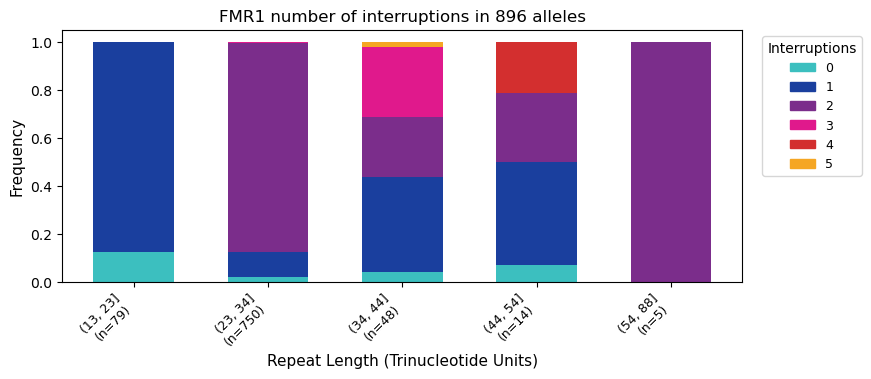

In [ ]:
fig = plt.figure(figsize=(10, 9))
# ---- Panel B: Normalized stacked bars by repeat-length bin ----
ax_b = fig.add_axes([0.12, 0.07, 0.68, 0.28])
x_pos = np.arange(len(bin_labels))
bottom_b = np.zeros(len(bin_labels))
agg_vals_b = sorted(pivot_b_norm.columns.tolist())

for agg in agg_vals_b:
    if agg in pivot_b_norm.columns:
        vals = pivot_b_norm[agg].reindex(bin_labels, fill_value=0).values
        ax_b.bar(x_pos, vals, bottom=bottom_b,
                 color=agg_colors.get(agg, 'grey'), label=str(agg), width=0.6)
        bottom_b += vals

x_tick_labels = [f'{lbl}\n(n={bin_counts.get(lbl, 0)})' for lbl in bin_labels]
ax_b.set_xticks(x_pos)
ax_b.set_xticklabels(x_tick_labels, rotation=45, ha='right', fontsize=9)
ax_b.set_ylabel('Frequency', fontsize=11)
ax_b.set_xlabel('Repeat Length (Trinucleotide Units)', fontsize=11)
ax_b.set_title(f'FMR1 number of interruptions in {n_alleles} alleles', fontsize=12)
ax_b.set_ylim(0, 1.05)

handles_b = [mpatches.Patch(color=agg_colors.get(a, 'grey'), label=str(a)) for a in agg_vals_b]
ax_b.legend(handles=handles_b, title='Interruptions',
            bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9)

plt.savefig('figures/SupplementaryFigure15B.png', dpi=600)
plt.savefig('figures/SupplementaryFigure15B.svg')

# S16: Disease-associated STR Enrichment in srWGS

## S16A

In [15]:
# caluclate the proportion of the pathogenic TRs that rank above the 90th, 95th, and 99th percentiles
# initial data loading and package import
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sb
import matplotlib
from matplotlib.colors import to_rgba

mpl.rcParams['svg.fonttype'] = 'none'  # keep SVG text in SVGs

totalLenAoU=pd.read_csv('statsTables/aou704_srWGS_alleleLengthStats.txt.gz',sep='\t')

# get reference motif lengths
catalog=pd.read_csv('assets/srWGS_IDs_with_motifs.txt',sep='\t',header=None,names=['TRID','refMotif'])
catalog['refMotifLen']=catalog.loc[:,'refMotif'].str.len()

# calculate percentile of standard deviation normalized by ref motif len
totalLenAoU=totalLenAoU.merge(catalog,how='inner',on='TRID')
totalLenAoU['percentile_stdev']=totalLenAoU.groupby('refMotifLen',observed=True)['std'].rank(pct=True)

# Define pathogenic and poly-alanine TRIDs
pathogenic=pd.read_csv('assets/pathogenicTRIDs_AoUsrWGS704_withAnno.txt',sep='\t')

polyAlanineTRNames = ['ARX','NIPA1','HOXA13','PHOX2B','SOX3','HOXD13','ZIC2','RUNX2','PABPN1','FOXL2']
polyAlanineTRIDs = pathogenic.loc[pathogenic['geneName'].isin(polyAlanineTRNames),'TRID'].values
singleShiftTRNames = ['MIR7-2','COMP']
singleShiftTRIDs = pathogenic.loc[pathogenic['geneName'].isin(singleShiftTRNames),'TRID'].values
otherPathogenicTRIDs = pathogenic.loc[((~pathogenic['geneName'].isin(polyAlanineTRNames)) & (~pathogenic['geneName'].isin(singleShiftTRNames))),'TRID'].values


# mark pathogenic TRs
totalLenAoU['patho']=0
totalLenAoU.loc[totalLenAoU['TRID'].isin(otherPathogenicTRIDs),'patho']=1

# calculate odds ratios
from statsmodels.stats.contingency_tables import Table2x2
def calculate_enrichment_with_ci(df, percentile_threshold, pathogenic_col='patho'):
    above_threshold = df['percentile_stdev'] > percentile_threshold
    
    a = ((df[pathogenic_col] == 1) & above_threshold).sum()
    b = ((df[pathogenic_col] == 0) & above_threshold).sum()
    c = ((df[pathogenic_col] == 1) & ~above_threshold).sum()
    d = ((df[pathogenic_col] == 0) & ~above_threshold).sum()
    
    table = Table2x2([[a, b], [c, d]])
    
    return {
        'odds_ratio': table.oddsratio,
        'p_value': table.oddsratio_pvalue(),
        'ci_95': table.oddsratio_confint(alpha=0.05),
        'contingency_table': [[a, b], [c, d]],
        'n_pathogenic_above': a,
        'n_pathogenic_total': a + c,
        'n_total_above': a + b
    }


print("\n=== Non-polyAlanine and non-single-shift Pathogenic TRs ===")
for threshold in [0.80, 0.90, 0.95, 0.99]:
    stats = calculate_enrichment_with_ci(totalLenAoU, threshold)
    print(f"\nAbove {threshold*100:.0f}th percentile:")
    print(f"  Contingency table: {stats['contingency_table']}")
    print(f"  Odds Ratio: {stats['odds_ratio']:.2f}")
    print(f"  Confidence Interval: {stats['ci_95']}")
    print(f"  P-value: {stats['p_value']:.2e}")
    print(f"  Pathogenic above threshold: {stats['n_pathogenic_above']}/{stats['n_pathogenic_total']} ({stats['n_pathogenic_above']/stats['n_pathogenic_total']:.1%})")






=== Non-polyAlanine and non-single-shift Pathogenic TRs ===

Above 80th percentile:
  Contingency table: [[22, 34845], [3, 139430]]
  Odds Ratio: 29.34
  Confidence Interval: (8.782416808152304, 98.04384272337526)
  P-value: 4.02e-08
  Pathogenic above threshold: 22/25 (88.0%)

Above 90th percentile:
  Contingency table: [[19, 17422], [6, 156853]]
  Odds Ratio: 28.51
  Confidence Interval: (11.384856756211114, 71.39483112102579)
  P-value: 8.48e-13
  Pathogenic above threshold: 19/25 (76.0%)

Above 95th percentile:
  Contingency table: [[18, 8709], [7, 165566]]
  Odds Ratio: 48.89
  Confidence Interval: (20.41298725133118, 117.07066838237722)
  P-value: 2.57e-18
  Pathogenic above threshold: 18/25 (72.0%)

Above 99th percentile:
  Contingency table: [[11, 1750], [14, 172525]]
  Odds Ratio: 77.46
  Confidence Interval: (35.11644730742675, 170.86247830939374)
  P-value: 4.44e-27
  Pathogenic above threshold: 11/25 (44.0%)


In [16]:
import scipy.stats
# calculate generalized odds ratio for this statistic
group1=totalLenAoU.loc[totalLenAoU['patho']==1,'percentile_stdev'].dropna().values
group2=totalLenAoU.loc[:,'percentile_stdev'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")



Raw U Statistic: 4072841.5
P-Value: 2.5720312629710714e-14
Probability of Superiority: 0.9347
Generalized Odds Ratio: 14.3078


In [17]:
# caluclate the proportion of the pathogenic TRs that rank above the 90th, 95th, and 99th percentiles
# initial data loading and package import
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sb
import matplotlib
from matplotlib.colors import to_rgba

mpl.rcParams['svg.fonttype'] = 'none'  # keep SVG text in SVGs

totalLen=pd.read_csv('statsTables/ensembleTR_alleleLengthStats.txt.gz',sep='\t')

# get reference motif lengths
catalog=pd.read_csv('assets/ensembleTR_IDs_with_motif_length.txt',sep='\t',header=None,names=['TRID','refMotifLen'])

# calculate percentile of standard deviation normalized by ref motif len
totalLen=totalLen.merge(catalog,how='inner',on='TRID')
totalLen['percentile_stdev']=totalLen.groupby('refMotifLen',observed=True)['std'].rank(pct=True)

# Define pathogenic and poly-alanine TRIDs
pathogenic=pd.read_csv('assets/pathogenicTRIDs_ensembleTR_withAnno.txt',sep='\t')

polyAlanineTRNames = ['ARX','NIPA1','HOXA13','PHOX2B','SOX3','HOXD13','ZIC2','RUNX2','PABPN1','FOXL2']
polyAlanineTRIDs = pathogenic.loc[pathogenic['geneName'].isin(polyAlanineTRNames),'TRID'].values
singleShiftTRNames = ['MIR7-2','COMP']
singleShiftTRIDs = pathogenic.loc[pathogenic['geneName'].isin(singleShiftTRNames),'TRID'].values
otherPathogenicTRIDs = pathogenic.loc[((~pathogenic['geneName'].isin(polyAlanineTRNames)) & (~pathogenic['geneName'].isin(singleShiftTRNames))),'TRID'].values


# mark pathogenic TRs
totalLen['patho']=0
totalLen.loc[totalLen['TRID'].isin(otherPathogenicTRIDs),'patho']=1

# calculate odds ratios
from statsmodels.stats.contingency_tables import Table2x2
def calculate_enrichment_with_ci(df, percentile_threshold, pathogenic_col='patho'):
    above_threshold = df['percentile_stdev'] > percentile_threshold
    
    a = ((df[pathogenic_col] == 1) & above_threshold).sum()
    b = ((df[pathogenic_col] == 0) & above_threshold).sum()
    c = ((df[pathogenic_col] == 1) & ~above_threshold).sum()
    d = ((df[pathogenic_col] == 0) & ~above_threshold).sum()
    
    table = Table2x2([[a, b], [c, d]])
    
    return {
        'odds_ratio': table.oddsratio,
        'p_value': table.oddsratio_pvalue(),
        'ci_95': table.oddsratio_confint(alpha=0.05),
        'contingency_table': [[a, b], [c, d]],
        'n_pathogenic_above': a,
        'n_pathogenic_total': a + c,
        'n_total_above': a + b
    }


print("\n=== Non-polyAlanine and non-single-shift Pathogenic TRs ===")
for threshold in [0.80, 0.90, 0.95, 0.99]:
    stats = calculate_enrichment_with_ci(totalLen, threshold)
    print(f"\nAbove {threshold*100:.0f}th percentile:")
    print(f"  Contingency table: {stats['contingency_table']}")
    print(f"  Odds Ratio: {stats['odds_ratio']:.2f}")
    print(f"  Confidence Interval: {stats['ci_95']}")
    print(f"  P-value: {stats['p_value']:.2e}")
    print(f"  Pathogenic above threshold: {stats['n_pathogenic_above']}/{stats['n_pathogenic_total']} ({stats['n_pathogenic_above']/stats['n_pathogenic_total']:.1%})")




=== Non-polyAlanine and non-single-shift Pathogenic TRs ===

Above 80th percentile:
  Contingency table: [[30, 342823], [1, 1371261]]
  Odds Ratio: 120.00
  Confidence Interval: (16.36431979842959, 879.9234627464173)
  P-value: 2.48e-06
  Pathogenic above threshold: 30/31 (96.8%)

Above 90th percentile:
  Contingency table: [[30, 171414], [1, 1542670]]
  Odds Ratio: 269.99
  Confidence Interval: (36.819114704903726, 1979.8060933955542)
  P-value: 3.64e-08
  Pathogenic above threshold: 30/31 (96.8%)

Above 95th percentile:
  Contingency table: [[28, 85716], [3, 1628368]]
  Odds Ratio: 177.31
  Confidence Interval: (53.9038698884182, 583.2233914491068)
  P-value: 1.55e-17
  Pathogenic above threshold: 28/31 (90.3%)

Above 99th percentile:
  Contingency table: [[21, 17171], [10, 1696913]]
  Odds Ratio: 207.53
  Confidence Interval: (97.71833795030368, 440.7481468772041)
  P-value: 7.97e-44
  Pathogenic above threshold: 21/31 (67.7%)


In [18]:
import scipy.stats
# calculate generalized odds ratio for this statistic
group1=totalLen.loc[totalLen['patho']==1,'percentile_stdev'].dropna().values
group2=totalLen.loc[:,'percentile_stdev'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")



Raw U Statistic: 51468059.5
P-Value: 7.39062045926227e-20
Probability of Superiority: 0.9686
Generalized Odds Ratio: 30.8283


In [21]:
from statsmodels.stats.contingency_tables import Table2x2

def calculate_enrichment_with_ci(df, percentile_threshold, pathogenic_col='patho'):
    above_threshold = df['percentile_stdev'] > percentile_threshold
    
    a = ((df[pathogenic_col] == 1) & above_threshold).sum()
    b = ((df[pathogenic_col] == 0) & above_threshold).sum()
    c = ((df[pathogenic_col] == 1) & ~above_threshold).sum()
    d = ((df[pathogenic_col] == 0) & ~above_threshold).sum()
    
    table = Table2x2([[a, b], [c, d]])
    
    return {
        'odds_ratio': table.oddsratio,
        'p_value': table.oddsratio_pvalue(),
        'ci_95': table.oddsratio_confint(alpha=0.05),
        'contingency_table': [[a, b], [c, d]],
        'n_pathogenic_above': a,
        'n_pathogenic_total': a + c,
        'n_total_above': a + b
    }
# Collect n_pathogenic_above values for plotting
thresholds = [0.90, 0.95, 0.99, 0.999]
datasets = {
    'AoU srWGS Cohort': totalLenAoU,
    'EnsembleTR Cohort': totalLen
}
numPatho={'AoU srWGS Cohort':25,'EnsembleTR Cohort':31}

# Collect data for plotting
plot_data = []
for dataset_name, dataset in datasets.items():
    for threshold in thresholds:
        stats = calculate_enrichment_with_ci(dataset, threshold)
        plot_data.append({
            'Dataset': dataset_name,
            'Threshold': f'{threshold*100:.1f}th Percentile',
            'percent_pathogenic_above': 100*stats['n_pathogenic_above']/numPatho[dataset_name]
        })

# Convert to DataFrame for easier plotting
plot_df = pd.DataFrame(plot_data)

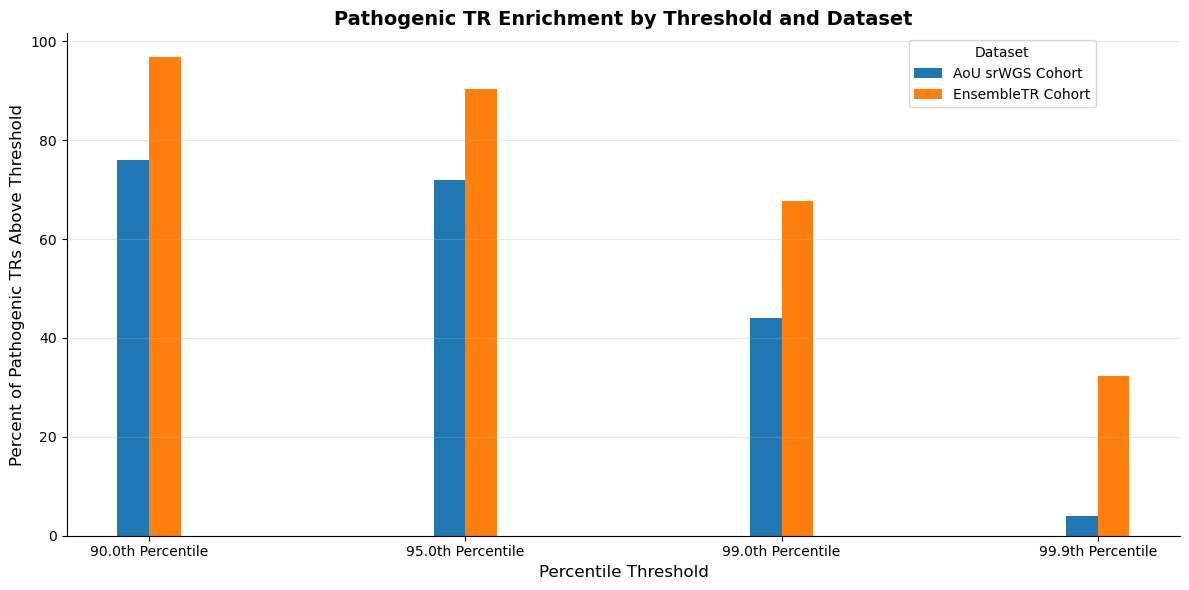

In [ ]:
# Create grouped bar plot
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['svg.fonttype'] = 'none'
fig, ax = plt.subplots(figsize=(12, 6))

# Get unique thresholds and datasets
threshold_labels = [f'{t*100:.1f}th Percentile' for t in thresholds]
dataset_names = list(datasets.keys())

# Set up bar positions
x = np.arange(len(threshold_labels))
width = 0.1
offsets = np.arange(len(dataset_names)) * width - (len(dataset_names) - 1) * width / 2

# Plot bars for each dataset
for idx, dataset_name in enumerate(dataset_names):
    data_subset = plot_df[plot_df['Dataset'] == dataset_name]
    values = [data_subset[data_subset['Threshold'] == tl]['percent_pathogenic_above'].values[0] 
              for tl in threshold_labels]
    ax.bar(x + offsets[idx], values, width, label=dataset_name)

# Customize plot
ax.set_xlabel('Percentile Threshold', fontsize=12)
ax.set_ylabel('Percent of Pathogenic TRs Above Threshold', fontsize=12)
ax.set_title('Pathogenic TR Enrichment by Threshold and Dataset', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(threshold_labels)
ax.legend(title='Dataset', bbox_to_anchor=(0.75, 1), loc='upper left')
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('figures/SupplementaryFigure16.png',dpi=600)
plt.savefig('figures/SupplementaryFigure16.svg')

# S17: Network Analyses

In [ ]:
# I have no code for this figure

# Association Investigation

## 5'-UTR CGG repeats

In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load data
lpsPerMotif=pd.read_csv('statsTables/DiscoveryCohort_lpsPerMotifStats.TR_Explorer_1.0.1.txt.gz',sep='\t')
lps=pd.read_csv('statsTables/DiscoveryCohort_lpsPerLocusStats.TR_Explorer_1.0.1.txt.gz',sep='\t')

# drop to the most common LPS motif per locus
lpsPerMotif=lpsPerMotif.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)

annotations=pd.read_csv('assets/genicRegionAnnotations_TRExplorer.txt.gz',sep='\t',header=None,names=['TRID','region'])
# function to convert motifs to their simplest rotational form with reverse complements
def complement(seq):
    complement = {'A': 'T', 'C': 'G', 'G': 'C', 'T': 'A'} 
    bases = list(seq) 
    bases = [complement[base] for base in bases] 
    return ''.join(bases)
def reverse_complement(seq):
    return complement(seq[::-1])
def simplest_motif(motif):
    i = (motif+motif).find(motif, 1, -1)
    if i != -1:
        motif = motif[:i]
    motifs = []
    b = len(motif)
    for i in range(b):
        c = motif[i:]+motif[:i]
        motifs.append(c)
    motifs = [x.upper() for x in motifs]
    # repeat with reverse complement
    motifRC=reverse_complement(motif.upper())
    i = (motifRC+motifRC).find(motifRC, 1, -1)
    if i != -1:
        motifRC = motifRC[:i]
    b = len(motifRC)
    for i in range(b):
        c = motifRC[i:]+motifRC[:i]
        motifs.append(c)    
    return(min(motifs))

# apply the simplest_motif function the data
lpsPerMotif['simpleMotif']=lpsPerMotif.loc[:,'LPS_Motif'].apply(simplest_motif)
lpsPerMotif['motifLen']=lpsPerMotif.loc[:,'simpleMotif'].str.len()

lps=lps.merge(lpsPerMotif.loc[:,['TRID','motifLen','simpleMotif']],how='inner',on='TRID')

# calculate PLVI
lps['PLVI']=lps.groupby('motifLen',observed=True)['std'].rank(pct=True)

# filter down to only 5'UTR CCGs
lps2=lps.loc[lps['simpleMotif']=='CCG',:]
lps3=lps2.loc[lps2['TRID'].isin(annotations.loc[annotations['region']=='UTR_5','TRID'].values),:]
lps3

,TRID,N,0thPercentile,1stPercentile,5thPercentile,10thPercentile,15thPercentile,20thPercentile,25thPercentile,30thPercentile,...,100thPercentile,mean,std,mad,mode,uniqueLengths,CPS,motifLen,simpleMotif,PLVI
1243,1-233614152-233614163-GGC,1086,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,...,18.0,9.008287,0.273104,0.0,9,2,0.000614,3,CCG,0.897506
2309,1-212951477-212951493-CCG,1086,9.0,15.0,15.0,15.0,15.0,15.0,15.0,15.0,...,21.0,15.011050,0.630900,0.0,15,3,0.000000,3,CCG,0.935943
3217,1-244835611-244835621-GGC,1086,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,...,9.0,9.000000,0.000000,0.0,9,1,0.000000,3,CCG,0.390633
3311,1-222815136-222815146-CGC,1086,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,...,9.0,9.000000,0.000000,0.0,9,1,0.000000,3,CCG,0.390633
3857,1-166975353-166975364-GGC,1086,6.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,...,9.0,8.997238,0.091035,0.0,9,2,0.000000,3,CCG,0.792915
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4412200,X-77786191-77786200-GCC,896,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,...,9.0,9.000000,0.000000,0.0,9,1,0.000000,3,CCG,0.390633
4412500,X-107206285-107206294-CGC,896,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,...,9.0,9.000000,0.000000,0.0,9,1,0.000000,3,CCG,0.390633
4413249,X-12138832-12138844-GCC,896,12.0,12.0,12.0,12.0,12.0,12.0,12.0,12.0,...,12.0,12.000000,0.000000,0.0,12,1,0.000000,3,CCG,0.390633
4420137,Y-6910949-6910959-CGC,190,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,...,9.0,9.000000,0.000000,0.0,9,1,0.000000,3,CCG,0.390633


In [30]:
geneNameAssignments=pd.read_csv('assets/TR_to_gene_name_TRExplorer.txt.gz',sep='\t',header=None,names=['TRID','geneName'])
geneNameAssignments=geneNameAssignments.loc[geneNameAssignments['geneName']!='intergenic',:]
genesWithUTR5CGGs=geneNameAssignments.merge(lps3,how='inner',on='TRID')
genesWithUTR5CGGs

,TRID,geneName,N,0thPercentile,1stPercentile,5thPercentile,10thPercentile,15thPercentile,20thPercentile,25thPercentile,...,100thPercentile,mean,std,mad,mode,uniqueLengths,CPS,motifLen,simpleMotif,PLVI
0,2-86623543-86623553-CGG,RNF103,1086,9.0,9.0,9.0,9.0,9.0,9.0,9.0,...,9.0,9.000000,0.000000,0.0,9,1,0.000000,3,CCG,0.390633
1,3-160565395-160565404-CGC,KPNA4,1086,9.0,9.0,9.0,9.0,9.0,9.0,9.0,...,9.0,9.000000,0.000000,0.0,9,1,0.000000,3,CCG,0.390633
2,1-96721716-96721729-CCG,PTBP2,1086,12.0,12.0,12.0,12.0,12.0,12.0,12.0,...,12.0,12.000000,0.000000,0.0,12,1,0.000000,3,CCG,0.390633
3,10-132785986-132786000-CCG,NKX6-2,1086,12.0,12.0,12.0,12.0,12.0,12.0,12.0,...,12.0,12.000000,0.000000,0.0,12,1,0.000000,3,CCG,0.390633
4,22-50193046-50193055-GCC,TRABD,1086,9.0,9.0,9.0,9.0,9.0,9.0,9.0,...,9.0,9.000000,0.000000,0.0,9,1,0.000000,3,CCG,0.390633
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6424,1-20786717-20786726-CCG,HP1BP3,1086,9.0,9.0,9.0,9.0,9.0,9.0,9.0,...,9.0,9.000000,0.000000,0.0,9,1,0.000000,3,CCG,0.390633
6425,14-57865989-57866013-GCG,SLC35F4,1086,15.0,24.0,24.0,24.0,24.0,24.0,24.0,...,30.0,24.425414,1.502520,0.0,24,4,0.000000,3,CCG,0.976727
6426,15-55587941-55587952-GCG,PYGO1,1086,9.0,9.0,9.0,9.0,9.0,9.0,9.0,...,9.0,9.000000,0.000000,0.0,9,1,0.000000,3,CCG,0.390633
6427,19-7595877-7595907-GCG,CAMSAP3,1086,15.0,15.0,18.0,18.0,18.0,18.0,18.0,...,189.0,19.966851,5.396774,0.0,21,6,0.000921,3,CCG,0.996101


In [31]:
genesWithUTR5CGGs.loc[:,'50thPercentile'].median()

9.0

In [33]:
pathogenic=pd.read_csv('assets/pathogenicTRIDs_TRExplorer_v1.0.1_STRchiveFiltered_noVNTRs_withAnno.txt',sep='\t',low_memory=False)
genesWithUTR5CGGsPatho=genesWithUTR5CGGs.loc[genesWithUTR5CGGs['TRID'].isin(pathogenic.TRID.values),:]
genesWithUTR5CGGsPatho.loc[:,'50thPercentile'].median()

30.0

In [41]:
genesWithUTR5CGGs=geneNameAssignments.merge(lps3,how='inner',on='TRID')
fiftieth, ninetyNinth = genesWithUTR5CGGs.loc[:,'std'].quantile([0.5,0.99])
genesWithUTR5CGGs=genesWithUTR5CGGs.sort_values(by='std',ascending=False).drop_duplicates(subset='geneName',keep='first')
highVarianceGenes=genesWithUTR5CGGs.loc[genesWithUTR5CGGs['std']>ninetyNinth,:]
lowVarianceGenes=genesWithUTR5CGGs.loc[genesWithUTR5CGGs['std']<=fiftieth,:]
highVarianceGenes.loc[:,'50thPercentile'].median()

22.5

In [42]:
group1=highVarianceGenes['50thPercentile'].dropna().values
group2=lowVarianceGenes['50thPercentile'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")

Raw U Statistic: 100989.5
P-Value: 1.9788939315043877e-31
Probability of Superiority: 0.8290
Generalized Odds Ratio: 4.8472


In [44]:
# show variation in GTEx genes from top 5% of genesWithUTR5s vs genes from bottom 50% of it
genesWithUTR5CGGs=geneNameAssignments.merge(lps3,how='inner',on='TRID')
fiftieth, ninetyNinth = genesWithUTR5CGGs.loc[:,'std'].quantile([0.5,0.99])
genesWithUTR5CGGs=genesWithUTR5CGGs.sort_values(by='std',ascending=False).drop_duplicates(subset='geneName',keep='first')
highVarianceGenes=genesWithUTR5CGGs.loc[genesWithUTR5CGGs['std']>ninetyNinth,:]
lowVarianceGenes=genesWithUTR5CGGs.loc[genesWithUTR5CGGs['std']<=fiftieth,:]
gtexStats=pd.read_csv('assets/gtex_gene_tissue_stats.txt.gz',sep='\t')
gtexStats=gtexStats.rename(columns={'gene_name':'geneName'})
gtexStats['CV']=0.0
gtexStats.loc[gtexStats['mean_tpm']>1,'CV']=gtexStats.loc[gtexStats['mean_tpm']>1,'std_tpm']/gtexStats.loc[gtexStats['mean_tpm']>1,'mean_tpm']
# for each gene, get the tissue with the highest mean_tpm and select its CV as the representative of this gene
geneCV = gtexStats.loc[gtexStats.groupby('geneName')['CV'].idxmax(), :]

# next, get the genes with the top 1% most variable 5'-UTR CGGs and the bottom 50% least variable ones and compare the CVs for those genes
highVarianceGenes=highVarianceGenes.loc[:,['geneName','std']].merge(geneCV,how='inner',on='geneName')
lowVarianceGenes=lowVarianceGenes.loc[:,['geneName','std']].merge(geneCV,how='inner',on='geneName')
highVarianceGenes

,geneName,std,gene_id,tissue,mean_tpm,median_tpm,std_tpm,n_samples,CV
0,LATS1,26.251980,ENSG00000131023.13,Whole Blood,3.302288,2.852000,2.170720,803,0.657338
1,NFIX,22.455194,ENSG00000008441.19,Whole Blood,11.325126,8.675660,10.073071,803,0.889444
2,SENP3,20.302676,ENSG00000161956.14,Kidney - Cortex,29.143148,23.498700,17.548836,104,0.602160
3,FMR1,18.762462,ENSG00000102081.16,Whole Blood,8.406691,7.252590,5.543344,803,0.659397
4,XYLT1,17.568185,ENSG00000103489.12,Kidney - Cortex,1.423090,0.819065,1.694100,104,1.190437
5,VENTX,16.598636,ENSG00000151650.8,Kidney - Cortex,2.369787,1.070920,3.574207,104,1.508240
6,PTPN12,16.446912,ENSG00000127947.16,Liver - Hepatocyte,14.591740,11.257900,10.322228,9,0.707402
7,FLT1,16.355878,ENSG00000102755.13,Liver,4.066776,2.098165,6.919193,262,1.701395
8,NR2F6,16.265694,ENSG00000160113.6,Whole Blood,1.952535,1.660610,1.215884,803,0.622721
9,FAM193B,16.101962,ENSG00000146067.17,Pancreas - Mixed Cell,47.397243,34.052650,49.216846,10,1.038390


In [45]:
genesWithUTR5CGGs.loc[:,'std'].quantile([0.5,0.99])

0.50    0.000000
0.99    8.073628
Name: std, dtype: float64

In [46]:
# are the high variance genes more neurological overall?
geneCV = gtexStats.loc[gtexStats.groupby('geneName')['median_tpm'].idxmax(), :]
# next, get the genes with the top 5% most variable 5'-UTR CGGs and the bottom 50% least variable ones and compare the CVs for those genes
highVarianceGenes=highVarianceGenes.loc[:,['geneName','std']].merge(geneCV,how='inner',on='geneName')
lowVarianceGenes=lowVarianceGenes.loc[:,['geneName','std']].merge(geneCV,how='inner',on='geneName')
highVarianceGenes['broadCategory']=highVarianceGenes.loc[:,'tissue'].str.split('-',expand=True).iloc[:,0].str.strip()
lowVarianceGenes['broadCategory']=lowVarianceGenes.loc[:,'tissue'].str.split('-',expand=True).iloc[:,0].str.strip()
print(f'Percentage of highVarianceGenes that are Brain or Nerve: {100*len(highVarianceGenes.loc[highVarianceGenes["broadCategory"].isin(["Brain","Nerve"]),:])/len(highVarianceGenes)}')
print(f'Percentage of lowVarianceGenes that are Brain or Nerve: {100*len(lowVarianceGenes.loc[lowVarianceGenes["broadCategory"].isin(["Brain","Nerve"]),:])/len(lowVarianceGenes)}')



Percentage of highVarianceGenes that are Brain or Nerve: 33.333333333333336
Percentage of lowVarianceGenes that are Brain or Nerve: 26.112099644128115


In [48]:
# are the high vs low variance genes differentiated in terms of gnomAD constraint?
gnomad=pd.read_csv('assets/gnomad_constraint.txt',sep='\t')
highVarianceGenes2=highVarianceGenes.merge(gnomad,how='inner',on='geneName')
lowVarianceGenes2=lowVarianceGenes.merge(gnomad,how='inner',on='geneName')

import scipy.stats
# calculate generalized odds ratio for this statistic
group1=lowVarianceGenes2.gnomad_oe_lof.dropna().values
group2=highVarianceGenes2.gnomad_oe_lof.dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")

Raw U Statistic: 60359.5
P-Value: 0.04095721844644849
Probability of Superiority: 0.5719
Generalized Odds Ratio: 1.3357


## Coding CAG repeats

In [64]:
# Load data
import pandas as pd
import pandas
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats

# Load data
lpsPerMotif=pd.read_csv('statsTables/DiscoveryCohort_lpsPerMotifStats.TR_Explorer_1.0.1.txt.gz',sep='\t')
lps=pd.read_csv('statsTables/DiscoveryCohort_lpsPerLocusStats.TR_Explorer_1.0.1.txt.gz',sep='\t')

# drop to the most common LPS motif per locus
lpsPerMotif=lpsPerMotif.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)

annotations=pd.read_csv('assets/genicRegionAnnotations_TRExplorer.txt.gz',sep='\t',header=None,names=['TRID','region'])
# function to convert motifs to their simplest rotational form with reverse complements
def complement(seq):
    complement = {'A': 'T', 'C': 'G', 'G': 'C', 'T': 'A'} 
    bases = list(seq) 
    bases = [complement[base] for base in bases] 
    return ''.join(bases)
def reverse_complement(seq):
    return complement(seq[::-1])
def simplest_motif(motif):
    i = (motif+motif).find(motif, 1, -1)
    if i != -1:
        motif = motif[:i]
    motifs = []
    b = len(motif)
    for i in range(b):
        c = motif[i:]+motif[:i]
        motifs.append(c)
    motifs = [x.upper() for x in motifs]
    # repeat with reverse complement
    motifRC=reverse_complement(motif.upper())
    i = (motifRC+motifRC).find(motifRC, 1, -1)
    if i != -1:
        motifRC = motifRC[:i]
    b = len(motifRC)
    for i in range(b):
        c = motifRC[i:]+motifRC[:i]
        motifs.append(c)    
    return(min(motifs))

# apply the simplest_motif function the data
lpsPerMotif['simpleMotif']=lpsPerMotif.loc[:,'LPS_Motif'].apply(simplest_motif)
lpsPerMotif['motifLen']=lpsPerMotif.loc[:,'simpleMotif'].str.len()

lps=lps.merge(lpsPerMotif.loc[:,['TRID','motifLen','simpleMotif']],how='inner',on='TRID')

# calculate PLVI
lps['PLVI']=lps.groupby('motifLen',observed=True)['std'].rank(pct=True)


lps2=lps.loc[lps['simpleMotif']=='AGC',:]
lps3=lps2.loc[lps2['TRID'].isin(annotations.loc[annotations['region']=='coding','TRID'].values),:]
geneNameAssignments=pd.read_csv('assets/TR_to_gene_name_TRExplorer.txt.gz',sep='\t',header=None,names=['TRID','geneName'])
geneNameAssignments=geneNameAssignments.loc[geneNameAssignments['geneName']!='intergenic',:]
genesCodingCAGs=geneNameAssignments.merge(lps3,how='inner',on='TRID')
fiftieth, ninetyNinth = genesCodingCAGs.loc[:,'std'].quantile([0.5,0.99])
genesCodingCAGs=genesCodingCAGs.sort_values(by='std',ascending=False).drop_duplicates(subset='geneName',keep='first')
highVarianceGenes=genesCodingCAGs.loc[genesCodingCAGs['std']>ninetyNinth,:]
lowVarianceGenes=genesCodingCAGs.loc[genesCodingCAGs['std']<=fiftieth,:]
group1=highVarianceGenes['50thPercentile'].dropna().values
group2=lowVarianceGenes['50thPercentile'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")
print(f"Group 1 Median: {np.median(group1)}")
print(f"Group 2 Median: {np.median(group2)}")

Raw U Statistic: 238636.5
P-Value: 2.522775488315248e-25
Probability of Superiority: 0.7033
Generalized Odds Ratio: 2.3706
Group 1 Median: 9.0
Group 2 Median: 9.0


In [50]:
pathogenic=pd.read_csv('assets/pathogenicTRIDs_TRExplorer_v1.0.1_STRchiveFiltered_noVNTRs_withAnno.txt',sep='\t',low_memory=False)
genesCodingCAGsPatho=genesCodingCAGs.loc[genesCodingCAGs['TRID'].isin(pathogenic.TRID.values),:]
genesCodingCAGsPatho.loc[:,'50thPercentile'].median()

45.0

In [51]:
# are the high variance genes more neurological overall?
gtexStats=pd.read_csv('assets/gtex_gene_tissue_stats.txt.gz',sep='\t')
gtexStats=gtexStats.rename(columns={'gene_name':'geneName'})
gtexStats['CV']=0.0
gtexStats.loc[gtexStats['mean_tpm']>1,'CV']=gtexStats.loc[gtexStats['mean_tpm']>1,'std_tpm']/gtexStats.loc[gtexStats['mean_tpm']>1,'mean_tpm']

# for each gene, get the tissue with the highest mean_tpm and select its CV as the representative of this gene
geneCV = gtexStats.loc[gtexStats.groupby('geneName')['median_tpm'].idxmax(), :]
# next, get the genes with the top 5% most variable 5'-UTR CGGs and the bottom 50% least variable ones and compare the CVs for those genes
highVarianceGenes=highVarianceGenes.loc[:,['geneName','std']].merge(geneCV,how='inner',on='geneName')
lowVarianceGenes=lowVarianceGenes.loc[:,['geneName','std']].merge(geneCV,how='inner',on='geneName')
highVarianceGenes['broadCategory']=highVarianceGenes.loc[:,'tissue'].str.split('-',expand=True).iloc[:,0].str.strip()
lowVarianceGenes['broadCategory']=lowVarianceGenes.loc[:,'tissue'].str.split('-',expand=True).iloc[:,0].str.strip()
print(f'Percentage of highVarianceGenes that are Brain or Nerve: {100*len(highVarianceGenes.loc[highVarianceGenes["broadCategory"].isin(["Brain","Nerve"]),:])/len(highVarianceGenes)}')
print(f'Percentage of lowVarianceGenes that are Brain or Nerve: {100*len(lowVarianceGenes.loc[lowVarianceGenes["broadCategory"].isin(["Brain","Nerve"]),:])/len(lowVarianceGenes)}')



Percentage of highVarianceGenes that are Brain or Nerve: 22.666666666666668
Percentage of lowVarianceGenes that are Brain or Nerve: 20.57777777777778


In [52]:
import scipy.stats
gnomad=pd.read_csv('assets/gnomad_constraint.txt',sep='\t')
highVarianceGenes2=highVarianceGenes.merge(gnomad,how='inner',on='geneName')
lowVarianceGenes2=lowVarianceGenes.merge(gnomad,how='inner',on='geneName')
# calculate generalized odds ratio for this statistic
group1=lowVarianceGenes2.gnomad_oe_lof.dropna().values
group2=highVarianceGenes2.gnomad_oe_lof.dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")

Raw U Statistic: 150013.5
P-Value: 0.05079789521631337
Probability of Superiority: 0.5591
Generalized Odds Ratio: 1.2680


In [71]:
# compare coding CAGs to intergenic ones:
intergenic=lps2.loc[lps2['TRID'].isin(annotations.loc[annotations['region']=='intergenic','TRID'].values),:]
intergenicThresh=intergenic.loc[:,'std'].quantile([0.98]).values[0]
pathoThresh=genesCodingCAGsPatho.loc[:,'std'].min()
codingThresh = genesCodingCAGs.loc[:,'std'].quantile([0.98]).values[0]
print('pathogenic: ' + str(pathoThresh))
print('intergenic 98th percentile: ' + str(intergenicThresh))
print('coding 98th percentile: ' + str(codingThresh))

pathogenic: 1.6248720819764146
intergenic 98th percentile: 1.3503380235845885
coding 98th percentile: 1.6566867509387195


In [54]:
intergenicThresh=intergenic.loc[:,'50thPercentile'].quantile(0.99)
intergenicHighVariance=intergenic.loc[intergenic['std']>=intergenicThresh,:]
highVarianceGenes=genesCodingCAGs.loc[genesCodingCAGs['std']>ninetyNinth,:]
pathoThresh=genesCodingCAGsPatho.loc[:,'50thPercentile'].median()
codingThresh=highVarianceGenes['50thPercentile'].median()
print('pathogenic: ' + str(pathoThresh))
print('intergenic 99th percentile: ' + str(intergenicHighVariance.loc[:,'50thPercentile'].median()))
print('coding 99th percentile: ' + str(codingThresh))
group1=genesCodingCAGsPatho['50thPercentile'].dropna().values
group2=intergenicHighVariance['50thPercentile'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")
print(f"Group 1 Median: {np.median(group1)}")
print(f"Group 2 Median: {np.median(group2)}")

pathogenic: 45.0
intergenic 99th percentile: 9.0
coding 99th percentile: 9.0
Raw U Statistic: 178.5
P-Value: 1.3618648348989624e-05
Probability of Superiority: 0.9545
Generalized Odds Ratio: 21.0000
Group 1 Median: 45.0
Group 2 Median: 9.0


In [72]:
group1=highVarianceGenes['50thPercentile'].dropna().values
group2=intergenicHighVariance['50thPercentile'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")
print(f"Group 1 Median: {np.median(group1)}")
print(f"Group 2 Median: {np.median(group2)}")

Raw U Statistic: 842.0
P-Value: 0.012512623201655668
Probability of Superiority: 0.6604
Generalized Odds Ratio: 1.9446
Group 1 Median: 9.0
Group 2 Median: 9.0


## Intronic AAAAT repeats

In [56]:
lps2=lps.loc[lps['simpleMotif']=='AAAAT',:]
lps3=lps2.loc[lps2['TRID'].isin(annotations.loc[annotations['region']=='intron','TRID'].values),:]
geneNameAssignments=pd.read_csv('assets/TR_to_gene_name_TRExplorer.txt.gz',sep='\t',header=None,names=['TRID','geneName'])
geneNameAssignments=geneNameAssignments.loc[geneNameAssignments['geneName']!='intergenic',:]
genesWithIntronicAAAATs=geneNameAssignments.merge(lps3,how='inner',on='TRID')
fiftieth, ninetyNinth = genesWithIntronicAAAATs.loc[:,'std'].quantile([0.5,0.99])
genesWithIntronicAAAATs=genesWithIntronicAAAATs.sort_values(by='std',ascending=False).drop_duplicates(subset='geneName',keep='first')
highVarianceGenes=genesWithIntronicAAAATs.loc[genesWithIntronicAAAATs['std']>ninetyNinth,:]
lowVarianceGenes=genesWithIntronicAAAATs.loc[genesWithIntronicAAAATs['std']<=fiftieth,:]
group1=highVarianceGenes['50thPercentile'].dropna().values
group2=lowVarianceGenes['50thPercentile'].dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")
print(f"Group 1 Median: {np.median(group1)}")
print(f"Group 2 Median: {np.median(group2)}")

Raw U Statistic: 254501.0
P-Value: 5.867776435043985e-145
Probability of Superiority: 0.9702
Generalized Odds Ratio: 32.5158
Group 1 Median: 50.0
Group 2 Median: 15.0


In [57]:
pathogenic=pd.read_csv('assets/pathogenicTRIDs_TRExplorer_v1.0.1_STRchiveFiltered_noVNTRs_withAnno.txt',sep='\t',low_memory=False)
genesWithIntronicAAAATsPatho=genesWithIntronicAAAATs.loc[genesWithIntronicAAAATs['TRID'].isin(pathogenic.TRID.values),:]
genesWithIntronicAAAATsPatho.loc[:,'50thPercentile'].median()

60.0

In [58]:
# are the high variance genes more neurological overall?
geneCV = gtexStats.loc[gtexStats.groupby('geneName')['median_tpm'].idxmax(), :]
# next, get the genes with the top 5% most variable 5'-UTR CGGs and the bottom 50% least variable ones and compare the CVs for those genes
highVarianceGenes=highVarianceGenes.loc[:,['geneName','std']].merge(geneCV,how='inner',on='geneName')
lowVarianceGenes=lowVarianceGenes.loc[:,['geneName','std']].merge(geneCV,how='inner',on='geneName')
highVarianceGenes['broadCategory']=highVarianceGenes.loc[:,'tissue'].str.split('-',expand=True).iloc[:,0].str.strip()
lowVarianceGenes['broadCategory']=lowVarianceGenes.loc[:,'tissue'].str.split('-',expand=True).iloc[:,0].str.strip()
print(f'Percentage of highVarianceGenes that are Brain or Nerve: {100*len(highVarianceGenes.loc[highVarianceGenes["broadCategory"].isin(["Brain","Nerve"]),:])/len(highVarianceGenes)}')
print(f'Percentage of lowVarianceGenes that are Brain or Nerve: {100*len(lowVarianceGenes.loc[lowVarianceGenes["broadCategory"].isin(["Brain","Nerve"]),:])/len(lowVarianceGenes)}')



Percentage of highVarianceGenes that are Brain or Nerve: 37.1900826446281
Percentage of lowVarianceGenes that are Brain or Nerve: 18.384401114206128


In [59]:
# is this statistically significant?
from scipy import stats
import numpy as np

# Create boolean masks
high_mask = highVarianceGenes['broadCategory'].isin(['Brain', 'Nerve'])
low_mask = lowVarianceGenes['broadCategory'].isin(['Brain', 'Nerve'])

# Counts for contingency table
high_true  = high_mask.sum()
high_false = (~high_mask).sum()
low_true   = low_mask.sum()
low_false  = (~low_mask).sum()

# 2x2 contingency table:
contingency = np.array([[high_true, high_false],
                         [low_true,  low_false]])

# Chi-square test (good for large counts, all cells >= 5)
chi2, p_chi2, dof, expected = stats.chi2_contingency(contingency)
print(f"Chi-square: {chi2:.4f}, p = {p_chi2:.4e}")

# Fisher's exact test (exact, works for any sample size)
# Use if any expected cell count < 5; also valid for large N
odds_ratio, p_fisher = stats.fisher_exact(contingency, alternative='greater')
print(f"Fisher's exact (one-sided, high > low): OR = {odds_ratio:.4f}, p = {p_fisher:.4e}")

# Proportions for reference
print(f"\nHigh variance Brain/Nerve: {high_true}/{len(highVarianceGenes)} = {high_true/len(highVarianceGenes):.3f}")
print(f"Low variance  Brain/Nerve: {low_true}/{len(lowVarianceGenes)} = {low_true/len(lowVarianceGenes):.3f}")

Chi-square: 24.7376, p = 6.5691e-07
Fisher's exact (one-sided, high > low): OR = 2.6286, p = 1.9604e-06

High variance Brain/Nerve: 45/121 = 0.372
Low variance  Brain/Nerve: 396/2154 = 0.184


In [60]:
import scipy.stats
gnomad=pd.read_csv('assets/gnomad_constraint.txt',sep='\t')
highVarianceGenes2=highVarianceGenes.merge(gnomad,how='inner',on='geneName')
lowVarianceGenes2=lowVarianceGenes.merge(gnomad,how='inner',on='geneName')
# calculate generalized odds ratio for this statistic
group1=lowVarianceGenes2.gnomad_oe_lof.dropna().values
group2=highVarianceGenes2.gnomad_oe_lof.dropna().values
u_stat, p_value = scipy.stats.mannwhitneyu(group1,group2,alternative='greater')
n1=len(group1)
n2=len(group2)
prob_superiority = u_stat / (n1*n2)
odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
print(f"Raw U Statistic: {u_stat}")
print(f"P-Value: {p_value}")
print(f"Probability of Superiority: {prob_superiority:.4f}")
print(f"Generalized Odds Ratio: {odds_ratio:.4f}")

Raw U Statistic: 123959.5
P-Value: 0.01182139310946524
Probability of Superiority: 0.5637
Generalized Odds Ratio: 1.2922
